# Cifra · Reconocimiento de dígitos manuscritos (caso TecnoForms)

Este cuaderno hace en Google Colab lo mismo que la aplicación **Cifra**: lee dígitos escritos a mano en fotos de formularios y
compara **siete modelos** de aprendizaje automático: red neuronal convolucional (**CNN**), red densa (**MLP**), **SVM**, **KNN**,
**regresión logística**, **regresión lineal** y **K-Means**. Usa el mismo código, los mismos hiperparámetros y la misma semilla que la aplicación.

**Ya viene ejecutado**: todos los resultados, tablas y gráficos están guardados debajo de cada celda. Para repetirlo: menú
*Entorno de ejecución → Ejecutar todas* (unos 15-25 minutos; con GPU la CNN va más rápido).

### Dónde se cumple cada requisito

| Requisito del caso | Pasos |
| --- | --- |
| Selección de algoritmos (red neuronal y comparación con KNN, SVM y otros) | 9 |
| Preparación de las imágenes: normalización, escala de grises y segmentación de los dígitos | 5, 6, 7, 8 |
| Red neuronal con capas convolucionales para extraer características | 9, 10 |
| Entrenamiento, validación cruzada y ajuste de hiperparámetros | 11, 12 |
| Conjunto de test, precisión de la clasificación, interpretación y comparación con modelos alternativos | 13, 14, 15 |
| Matriz de confusión, precisión, recall y F1 (datos de internet: MNIST) | 13, 14 |
| Código de regresión, K-Means, redes neuronales y preprocesamiento (datos ficticios) | 4, 5, 9, 17 |
| Resultados visuales: predicciones frente a etiquetas reales (datos de internet) | 16 |
| Arquitectura de la red: capas, nodos, función de activación y optimización | 10 |
| Corregir a los modelos que fallan y practicar con imágenes (como la aplicación) | 19, 20 |
| Informe con los pasos, el razonamiento, los algoritmos y los resultados | 21 (texto y PDF) |

**Datos:** *de internet* = MNIST (70 000 dígitos escritos por personas reales, descargados de Google). *Ficticios* = formularios y
números armados aquí mismo con dígitos de MNIST y degradados para parecer fotos (sombras, ruido, desenfoque, hojas cuadriculadas).

## Paso 1 · Librerías y configuración

**Qué hace:** carga las librerías y fija la configuración común a todo el cuaderno.

**Cómo funciona:**
- `numpy` (cálculo), `opencv` (procesar imágenes), `torch` (redes neuronales), `scikit-learn` (SVM, KNN, regresiones, K-Means, PCA y métricas),
  `matplotlib` (gráficos) y `reportlab` (el informe PDF; en Colab se instala sola).
- **Semilla 42** en todo: así cada ejecución da los mismos resultados.
- Si Colab tiene GPU, la CNN y la MLP la usan; si no, todo corre en CPU.
- Aquí están, igual que en la aplicación, cuántas muestras usa cada modelo, la **malla de hiperparámetros** que se prueba en la
  validación cruzada y los valores de partida.

In [1]:
import sys, subprocess
EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "reportlab"], check=False)

import itertools, json, time, warnings, urllib.request
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from PIL import Image, ImageDraw, ImageFont
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, precision_recall_fscore_support
from sklearn.model_selection import StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
pd.set_option("display.precision", 4)
pd.set_option("display.max_colwidth", None)
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

SEMILLA = 42
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)
DISPOSITIVO = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CLASES = list(range(10))
CARPETA = Path("resultados_colab")
CARPETA.mkdir(exist_ok=True)

CLAVES = ["cnn", "mlp", "svm", "knn", "regresion", "regresion_lineal", "kmeans"]
NOMBRES = {"cnn": "CNN (red convolucional)", "mlp": "MLP (red densa)", "svm": "SVM (RBF)", "knn": "KNN",
           "regresion": "Regresión logística", "regresion_lineal": "Regresión lineal", "kmeans": "K-Means"}
CORTOS = {"cnn": "CNN", "mlp": "MLP", "svm": "SVM", "knn": "KNN", "regresion": "Reg. logística",
          "regresion_lineal": "Reg. lineal", "kmeans": "K-Means"}
COLORES = {"cnn": "#e8590c", "mlp": "#6c4dff", "svm": "#12a06a", "knn": "#0a84d6", "regresion": "#d6336c",
           "regresion_lineal": "#00a3a3", "kmeans": "#b58900"}

MUESTRAS_ENTRENAMIENTO = {"cnn": 30000, "mlp": 30000, "svm": 10000, "knn": 20000,
                          "regresion": 30000, "regresion_lineal": 30000, "kmeans": 30000}
MUESTRAS_VALIDACION_CRUZADA = 5000
PLIEGUES = 5
GRILLAS = {
    "cnn": {"filtros": [8, 16], "tasa_aprendizaje": [0.001, 0.003]},
    "mlp": {"neuronas": [64, 128], "tasa_aprendizaje": [0.001, 0.003]},
    "svm": {"C": [1, 10], "gamma": ["scale", 0.05]},
    "knn": {"k": [1, 3, 5, 7]},
    "regresion": {"C": [0.1, 1.0, 10.0]},
    "regresion_lineal": {"alpha": [0.1, 1.0, 10.0, 100.0]},
    "kmeans": {"clusteres": [10, 30, 60]},
}
PARAMETROS_INICIALES = {
    "cnn": {"filtros": 16, "tasa_aprendizaje": 0.003, "epocas": 3, "dropout": 0.25},
    "mlp": {"neuronas": 128, "tasa_aprendizaje": 0.003, "epocas": 8, "dropout": 0.2},
    "svm": {"C": 10, "gamma": "scale", "componentes": 50},
    "knn": {"k": 3, "componentes": 50},
    "regresion": {"C": 1.0, "iteraciones": 200},
    "regresion_lineal": {"alpha": 1.0},
    "kmeans": {"clusteres": 60, "componentes": 50},
}
FIGURAS = {}  # nombre -> archivo PNG (van al informe PDF)


def es(texto):
    # Números al estilo español: 98.69 -> 98,69 y 10,000 -> 10 000
    import re
    texto = re.sub(r"(?<=\d),(?=\d{3}\b)", " ", str(texto))
    return re.sub(r"(?<=\d)\.(?=\d)", ",", texto)


def guardar_figura(figura, nombre):
    ruta = CARPETA / f"{nombre}.png"
    figura.savefig(ruta, bbox_inches="tight", facecolor="white")
    FIGURAS[nombre] = ruta
    plt.show()


print("En Colab:", EN_COLAB, "| dispositivo:", DISPOSITIVO, "| torch", torch.__version__, "| opencv", cv2.__version__)

En Colab: False | dispositivo: cpu | torch 2.14.0+cpu | opencv 4.10.0


## Paso 2 · Descargar MNIST (datos de internet)

**Qué hace:** baja el conjunto **MNIST**: 70 000 dígitos escritos a mano por personas reales (60 000 para entrenar y 10 000 para
el test final), cada uno en una imagen de 28 × 28 píxeles en escala de grises.

**Cómo funciona:**
- Se descarga una sola vez (11 MB) del servidor público de Google (`mnist.npz`).
- **Normalización:** cada píxel pasa de 0-255 a 0-1 (dividiendo por 255) y cada imagen se aplana a un vector de 784 valores.
- Los 10 000 dígitos de test **no se usan nunca para entrenar ni para elegir hiperparámetros**: solo para la nota final (paso 13).

In [2]:
URL_MNIST = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz"
ARCHIVO_MNIST = Path("mnist.npz")
if not ARCHIVO_MNIST.exists():
    urllib.request.urlretrieve(URL_MNIST, ARCHIVO_MNIST)

with np.load(ARCHIVO_MNIST) as datos:
    x_ent = datos["x_train"].reshape(-1, 784).astype(np.float32) / 255.0
    y_ent = datos["y_train"].astype(np.int64)
    x_pru = datos["x_test"].reshape(-1, 784).astype(np.float32) / 255.0
    y_pru = datos["y_test"].astype(np.int64)


def submuestra_estratificada(X, y, cantidad, semilla=SEMILLA):
    # Toma `cantidad` muestras manteniendo la proporción de cada dígito
    if cantidad >= len(y):
        return X, y
    azar = np.random.default_rng(semilla)
    indices = []
    for clase in np.unique(y):
        posiciones = np.flatnonzero(y == clase)
        tomar = int(round(cantidad * len(posiciones) / len(y)))
        indices.extend(azar.choice(posiciones, size=min(tomar, len(posiciones)), replace=False))
    indices = azar.permutation(np.array(indices))
    return X[indices], y[indices]


print(es(f"Entrenamiento: {x_ent.shape[0]:,} imágenes | test: {x_pru.shape[0]:,} imágenes | cada imagen: {x_ent.shape[1]} píxeles (28x28)"))
print(es(f"Valores de los píxeles: mínimo {x_ent.min():.1f}, máximo {x_ent.max():.1f}"))

Entrenamiento: 60 000 imágenes | test: 10 000 imágenes | cada imagen: 784 píxeles (28x28)
Valores de los píxeles: mínimo 0,0, máximo 1,0


## Paso 3 · Mirar los datos

**Qué hace:** muestra ejemplos de MNIST y cuántos hay de cada dígito.

**Cómo funciona:** toma 3 ejemplos de cada dígito y cuenta las etiquetas. Si las clases están **equilibradas** (casi la misma cantidad
de cada dígito), la exactitud es una medida justa y no hace falta compensar clases.

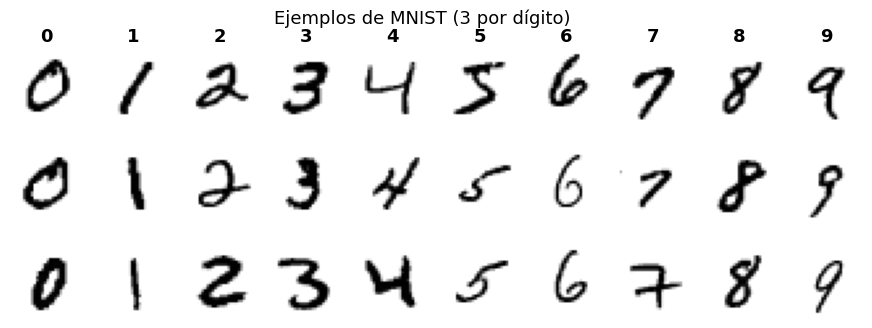

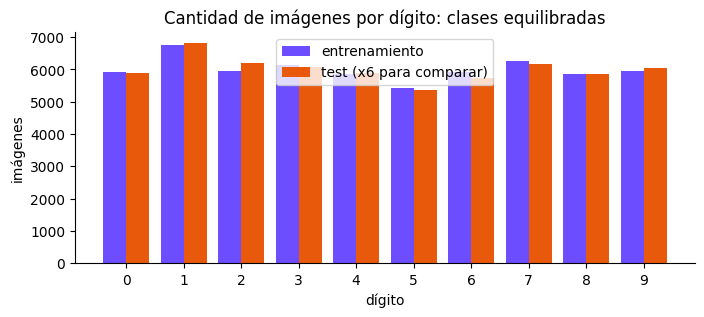

dígito,0,1,2,3,4,5,6,7,8,9
entrenamiento,5923,6742,5958,6131,5842,5421,5918,6265,5851,5949
test,980,1135,1032,1010,982,892,958,1028,974,1009


In [3]:
figura, ejes = plt.subplots(3, 10, figsize=(11, 3.6))
for d in range(10):
    for fila, i in enumerate(np.flatnonzero(y_ent == d)[:3]):
        ejes[fila, d].imshow(x_ent[i].reshape(28, 28), cmap="gray_r")
        ejes[fila, d].axis("off")
    ejes[0, d].set_title(str(d), fontsize=13, fontweight="bold")
figura.suptitle("Ejemplos de MNIST (3 por dígito)", fontsize=13)
guardar_figura(figura, "mnist_ejemplos")

conteo = pd.DataFrame({"entrenamiento": np.bincount(y_ent, minlength=10), "test": np.bincount(y_pru, minlength=10)})
conteo.index.name = "dígito"
figura, eje = plt.subplots(figsize=(8, 3))
eje.bar(conteo.index - 0.2, conteo["entrenamiento"], 0.4, label="entrenamiento", color="#6c4dff")
eje.bar(conteo.index + 0.2, conteo["test"] * 6, 0.4, label="test (x6 para comparar)", color="#e8590c")
eje.set_xticks(range(10)); eje.set_xlabel("dígito"); eje.set_ylabel("imágenes"); eje.legend()
eje.set_title("Cantidad de imágenes por dígito: clases equilibradas")
guardar_figura(figura, "mnist_clases")
display(conteo.T)

## Paso 4 · Datos ficticios: formularios y números «fotografiados»

**Qué hace:** crea imágenes de prueba parecidas a las fotos reales de TecnoForms: formularios llenados a mano, números en hoja lisa
y números en hojas **cuadriculadas o rayadas** de colores.

**Cómo funciona** (mismo generador que la aplicación):
1. Para escribir un número, toma un dígito de MNIST por cada cifra, lo recorta y lo agranda (60-110 px), con separación,
   altura e inclinación al azar, como letra de una persona.
2. Los **formularios** se dibujan con PIL: título, etiquetas («Teléfono», «Edad»…) y un recuadro por campo donde se pone el número.
3. El **efecto foto**: sombra en degradado, ruido, desenfoque y un tinte de color. La *dificultad* (0 a 1) controla cuánto.
4. Las hojas cuadriculadas tienen 12 colores de línea y 6 de tinta, cuadros de 18-34 px y la hoja algo torcida.

Como el valor de cada número es conocido, sirven para medir cuánto acierta todo el sistema (paso 17).

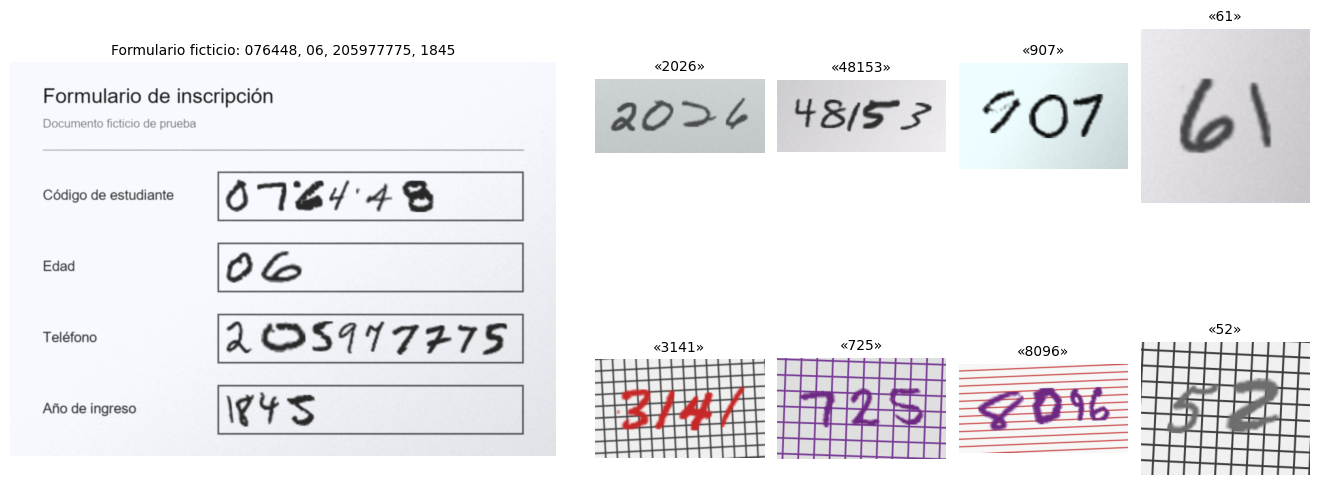

In [4]:
TIPOS_FORMULARIO = {
    "inscripcion": ("Formulario de inscripción", [("Código de estudiante", 6), ("Edad", 2), ("Teléfono", 9), ("Año de ingreso", 4)]),
    "pago": ("Comprobante de pago", [("N.º de factura", 6), ("Monto", 4), ("Cuotas", 1), ("Referencia", 8)]),
    "solicitud": ("Solicitud de servicio", [("N.º de solicitud", 5), ("Documento de identidad", 8), ("Cantidad", 2), ("Teléfono", 9)]),
}
COLORES_CUADRICULA = [(60, 60, 60), (140, 140, 140), (230, 180, 130), (160, 80, 20), (230, 200, 90), (170, 220, 160),
                      (60, 130, 40), (60, 60, 200), (190, 150, 240), (40, 140, 240), (150, 60, 120), (40, 80, 120)]
COLORES_TINTA = [(30, 30, 30), (150, 50, 20), (40, 40, 200), (40, 120, 20), (110, 110, 110), (130, 40, 110)]


def fuente(tamano):
    for nombre in ("arial.ttf", "DejaVuSans.ttf", "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf"):
        try:
            return ImageFont.truetype(nombre, tamano)
        except OSError:
            continue
    return ImageFont.load_default()


def recortar_tinta(capa, umbral=0.05):
    ys, xs = np.nonzero(capa > umbral)
    return capa[ys.min(): ys.max() + 1, xs.min(): xs.max() + 1]


class GeneradorDigitos:
    def __init__(self, X, y, semilla=SEMILLA):
        self.imagenes = X.reshape(-1, 28, 28)
        self.indices = {d: np.flatnonzero(y == d) for d in range(10)}
        self.azar = np.random.default_rng(semilla)

    def _muestra(self, digito):
        return recortar_tinta(self.imagenes[self.azar.choice(self.indices[digito])], 0.2)

    def capa_tinta(self, texto, altura=80, separacion=(6, 26), toque=0.0):
        azar, piezas = self.azar, []
        for caracter in texto:
            base = self._muestra(int(caracter))
            alto = max(12, round(altura * azar.uniform(0.9, 1.1)))
            ancho = max(3, round(base.shape[1] * alto / base.shape[0]))
            pieza = np.clip(cv2.resize(base, (ancho, alto), interpolation=cv2.INTER_CUBIC), 0, 1)
            if alto >= 50 and azar.random() < 0.25:
                pieza = cv2.dilate(pieza, np.ones((3, 3), np.uint8))
            piezas.append(pieza)
        margen = int(altura * 0.45) + 10
        huecos = [-int(azar.integers(2, 6)) if azar.random() < toque else int(azar.integers(*separacion)) for _ in piezas[:-1]]
        ancho_total = sum(p.shape[1] for p in piezas) + sum(huecos) + 2 * margen
        alto_total = int(altura * 1.4) + 2 * margen
        lienzo = np.zeros((alto_total, ancho_total), np.float32)
        cursor = margen
        for i, pieza in enumerate(piezas):
            y = int((alto_total - pieza.shape[0]) / 2 + azar.uniform(-0.08, 0.08) * altura)
            zona = lienzo[y: y + pieza.shape[0], cursor: cursor + pieza.shape[1]]
            np.maximum(zona, pieza, out=zona)
            cursor += pieza.shape[1] + (huecos[i] if i < len(huecos) else 0)
        centro = (ancho_total / 2, alto_total / 2)
        inclinacion = azar.uniform(-0.2, 0.2)
        lienzo = cv2.warpAffine(lienzo, np.float32([[1, inclinacion, -inclinacion * centro[1]], [0, 1, 0]]), (ancho_total, alto_total))
        return cv2.warpAffine(lienzo, cv2.getRotationMatrix2D(centro, azar.uniform(-3, 3), 1.0), (ancho_total, alto_total))

    def _efecto_foto(self, gris, dificultad):
        azar = self.azar
        alto, ancho = gris.shape
        yy, xx = np.mgrid[0:alto, 0:ancho].astype(np.float32)
        angulo = azar.uniform(0, 2 * np.pi)
        gradiente = np.cos(angulo) * (xx / ancho - 0.5) + np.sin(angulo) * (yy / alto - 0.5)
        gris = gris * (1 + azar.uniform(0.04, 0.22) * dificultad * 2 * gradiente)
        gris = gris + azar.normal(0, 1 + 7 * dificultad, gris.shape)
        sigma = azar.uniform(0, 1.4 * dificultad + 0.3)
        if sigma > 0.3:
            gris = cv2.GaussianBlur(gris, (0, 0), sigma)
        gris = np.clip(gris, 0, 255)
        tinte = np.array([1.0, azar.uniform(0.97, 1.0), azar.uniform(0.93, 1.0)], np.float32)
        return np.clip(gris[..., None] * tinte, 0, 255).astype(np.uint8)

    def foto_numero(self, texto, dificultad=0.5, altura=None, toque=0.0):
        tinta = self.capa_tinta(texto, altura or int(self.azar.integers(60, 110)), toque=toque)
        papel, color_tinta = self.azar.uniform(205, 248), self.azar.uniform(15, 80)
        return self._efecto_foto(papel - tinta * (papel - color_tinta), dificultad)

    def foto_cuadriculada(self, texto, dificultad=0.5, color_linea=None, color_tinta=None, rayada=None):
        azar = self.azar
        tinta = self.capa_tinta(texto, int(azar.integers(60, 110)), toque=0.1 if dificultad >= 0.5 else 0.0)
        alto, ancho = tinta.shape
        paso = int(azar.integers(18, 34))
        grosor = 2 if azar.random() < 0.3 + 0.4 * dificultad else 1
        grande = int(np.hypot(alto, ancho)) + 2 * paso
        papel = np.full((grande, grande, 3), azar.uniform(215, 248), np.float32)
        color_linea = tuple(float(c) for c in (color_linea or COLORES_CUADRICULA[int(azar.integers(len(COLORES_CUADRICULA)))]))
        rayada = azar.random() < 0.25 if rayada is None else rayada
        for v in range(int(azar.integers(0, paso)), grande, paso):
            cv2.line(papel, (0, v), (grande, v), color_linea, grosor)
            if not rayada:
                cv2.line(papel, (v, 0), (v, grande), color_linea, grosor)
        angulo = azar.uniform(-1, 1) * (1 + 4 * dificultad)
        papel = cv2.warpAffine(papel, cv2.getRotationMatrix2D((grande / 2, grande / 2), angulo, 1.0), (grande, grande),
                               borderMode=cv2.BORDER_REFLECT)
        y0, x0 = (grande - alto) // 2, (grande - ancho) // 2
        papel = papel[y0: y0 + alto, x0: x0 + ancho]
        color_tinta = np.array(color_tinta or COLORES_TINTA[int(azar.integers(len(COLORES_TINTA)))], np.float32)
        imagen = papel * (1 - tinta[..., None]) + color_tinta * tinta[..., None]
        imagen = imagen + azar.normal(0, 1 + 5 * dificultad, imagen.shape)
        imagen = cv2.GaussianBlur(imagen, (0, 0), azar.uniform(0.3, 0.5 + dificultad))
        return np.clip(imagen, 0, 255).astype(np.uint8)

    def numero_aleatorio(self, largo):
        return "".join(str(d) for d in self.azar.integers(0, 10, size=largo))

    def formulario(self, tipo, dificultad=0.4):
        titulo, definidos = TIPOS_FORMULARIO[tipo]
        alto = 200 + 130 * len(definidos)
        hoja = Image.new("L", (1000, alto), 255)
        pincel = ImageDraw.Draw(hoja)
        pincel.text((60, 40), titulo, fill=20, font=fuente(38))
        pincel.text((60, 100), "Documento ficticio de prueba", fill=110, font=fuente(22))
        pincel.line([(60, 160), (940, 160)], fill=150, width=2)
        campos = []
        for i, (etiqueta, largo) in enumerate(definidos):
            y = 200 + 130 * i
            caja = (380, y, 560, 90)
            pincel.text((60, y + 28), etiqueta, fill=40, font=fuente(26))
            pincel.rectangle([caja[0], caja[1], caja[0] + caja[2], caja[1] + caja[3]], outline=90, width=3)
            campos.append({"etiqueta": etiqueta, "valor": self.numero_aleatorio(largo), "caja": caja})
        base = np.array(hoja, np.float32)
        tinta = np.zeros_like(base)
        for campo in campos:
            x, y, w, h = campo["caja"]
            capa = recortar_tinta(self.capa_tinta(campo["valor"], altura=54, separacion=(8, 20)))
            escala = min(1.0, (w - 30) / capa.shape[1], (h - 16) / capa.shape[0])
            if escala < 1:
                capa = cv2.resize(capa, (round(capa.shape[1] * escala), round(capa.shape[0] * escala)), interpolation=cv2.INTER_AREA)
            y0, x0 = y + (h - capa.shape[0]) // 2, x + 15
            zona = tinta[y0: y0 + capa.shape[0], x0: x0 + capa.shape[1]]
            np.maximum(zona, capa, out=zona)
        gris = base * (1 - tinta) + tinta * self.azar.uniform(20, 70)
        return self._efecto_foto(gris, dificultad), campos


# Los datos ficticios salen solo de los dígitos de ENTRENAMIENTO: el test de MNIST queda intacto
generador = GeneradorDigitos(x_ent, y_ent)
formulario_ejemplo, campos_ejemplo = generador.formulario("inscripcion", 0.45)
lisos = [(n, generador.foto_numero(n, 0.5)) for n in ("2026", "48153", "907", "61")]
cuadriculados = [(n, generador.foto_cuadriculada(n, 0.5)) for n in ("3141", "725", "8096", "52")]

figura = plt.figure(figsize=(13, 6.5))
eje = figura.add_axes([0, 0, 0.42, 1]); eje.imshow(cv2.cvtColor(formulario_ejemplo, cv2.COLOR_BGR2RGB)); eje.axis("off")
eje.set_title("Formulario ficticio: " + ", ".join(c["valor"] for c in campos_ejemplo), fontsize=10)
for i, (n, img) in enumerate(lisos + cuadriculados):
    eje = figura.add_axes([0.45 + (i % 4) * 0.14, 0.52 - (i // 4) * 0.45, 0.13, 0.4])
    eje.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); eje.axis("off"); eje.set_title(f"«{n}»", fontsize=10)
guardar_figura(figura, "ficticios_ejemplos")

## Paso 5 · Preparación de las imágenes (preprocesado)

**Qué hace:** convierte la foto de un formulario o de un número en dígitos sueltos de **28 × 28**, iguales en forma a los de MNIST,
para que los modelos los puedan leer.

**Cómo funciona** (8 pasos, el mismo código de la aplicación):

| # | Paso | Para qué sirve | Técnica |
| --- | --- | --- | --- |
| 1 | Limitar tamaño | Que todas las fotos se procesen igual de rápido | Lado mayor a 1000 px (`cv2.resize`, INTER_AREA) |
| 2 | **Escala de grises** | El color no ayuda a saber qué dígito es | `cvtColor` BGR→gris; si la cuadrícula es de otro color que la tinta, se usa el canal (azul, verde o rojo) donde la cuadrícula casi desaparece |
| 3 | **Normalizar la iluminación** | Quitar sombras y dejar el papel blanco parejo | Se estima el fondo (dilatación + mediana) y se divide la foto por él; luego se estira a 0-255 |
| 4 | Binarizar | Separar tinta (blanco) de papel (negro) | Umbral automático de **Otsu** |
| 5 | Quitar cuadrícula o renglones | Que las líneas de la hoja no se confundan con trazos | Se buscan rectas largas y finas (apertura morfológica) y se borran sin tocar los trazos, más gruesos |
| 6 | **Segmentar** los dígitos | Encontrar cada dígito por separado | Componentes conectados → filtro de manchas → unir trazos de un mismo dígito (la barra del 5) → ordenar por filas y de izquierda a derecha → si se sabe cuántos dígitos hay, unir o partir cajas (dígitos pegados se parten por el valle de la proyección vertical) |
| 7 | Recortar como MNIST | Que el dígito quede como los de entrenamiento | Lado mayor a 20 px, centrado por **centro de masa** en un lienzo de 28 × 28 |
| 8 | **Normalizar** valores | Escala de 0 a 1 (y para las redes, media 0,1307 y desviación 0,3081 de MNIST) | División por 255 y estandarización |

Si los dígitos salen muy chicos (número lejano), se recorta esa zona de la foto y se procesa otra vez con más detalle.

In [5]:
LADO_MAXIMO = 1000
ALTURA_COMODA = 45


def limitar_tamano(imagen, lado_maximo=LADO_MAXIMO):
    alto, ancho = imagen.shape[:2]
    escala = lado_maximo / max(alto, ancho)
    if escala < 1:
        imagen = cv2.resize(imagen, (round(ancho * escala), round(alto * escala)), interpolation=cv2.INTER_AREA)
    return imagen


def normalizar_iluminacion(gris):
    # Divide por el fondo estimado para quitar sombras y dejar el papel casi blanco
    if np.median(gris) < 110:
        gris = 255 - gris
    lado = max(15, min(gris.shape) // 12) | 1
    fondo = cv2.medianBlur(cv2.dilate(gris, np.ones((lado, lado), np.uint8)), lado * 2 + 1)
    normalizada = cv2.divide(gris, np.maximum(fondo, 1), scale=255)
    return cv2.normalize(normalizada, None, 0, 255, cv2.NORM_MINMAX)


def binarizar(normalizada):
    _, binaria = cv2.threshold(normalizada, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    return binaria


def lineas_largas(binaria, horizontal):
    # Rectas de una hoja cuadriculada o rayada: cruzan casi toda la foto o, si están torcidas, salen por un borde
    alto, ancho = binaria.shape
    largo_total = ancho if horizontal else alto
    tramo = max(15, largo_total // 20)
    if horizontal:
        tramos = cv2.morphologyEx(cv2.dilate(binaria, np.ones((3, 1), np.uint8)), cv2.MORPH_OPEN, np.ones((1, tramo), np.uint8))
    else:
        tramos = cv2.morphologyEx(cv2.dilate(binaria, np.ones((1, 3), np.uint8)), cv2.MORPH_OPEN, np.ones((tramo, 1), np.uint8))
    cantidad, etiquetas, estadisticas, _ = cv2.connectedComponentsWithStats(tramos, connectivity=8)
    elegidas = []
    for i in range(1, cantidad):
        x, y, w, h, area = estadisticas[i]
        largo = w if horizontal else h
        toca_borde = x == 0 or y == 0 or x + w == ancho or y + h == alto
        if largo >= 0.8 * largo_total or (toca_borde and largo >= max(tramo, 0.1 * largo_total) and area <= 6 * largo):
            elegidas.append(i)
    return np.where(np.isin(etiquetas, elegidas), 255, 0).astype(np.uint8)


def a_gris(imagen):
    # Gris; si la cuadrícula es de otro color que la tinta, usa el canal donde la cuadrícula casi desaparece
    if imagen.ndim != 3:
        return imagen.copy()
    gris = cv2.cvtColor(imagen, cv2.COLOR_BGR2GRAY)
    binaria = binarizar(normalizar_iluminacion(gris))
    lineas = cv2.bitwise_and(cv2.bitwise_or(lineas_largas(binaria, True), lineas_largas(binaria, False)), binaria)
    if np.count_nonzero(lineas) < 50:
        return gris
    distancia = cv2.distanceTransform(binaria, cv2.DIST_L2, 3)
    radio = float(np.median(distancia[lineas > 0]))
    if not np.isfinite(radio) or radio > min(binaria.shape) / 8:
        return gris
    tinta = distancia > radio + 1.5
    cerca_de_tinta = cv2.dilate(tinta.astype(np.uint8), np.ones((5, 5), np.uint8)).astype(bool)
    linea_fina = (lineas > 0) & (distancia <= radio + 0.5) & ~cerca_de_tinta
    papel = binaria == 0
    if tinta.sum() < 20 or linea_fina.sum() < 50 or papel.sum() < 50:
        return gris
    candidatos = [gris] + [imagen[..., c] for c in range(3)]
    puntajes = []
    for canal in candidatos:
        fondo = float(np.median(canal[papel]))
        puntajes.append(fondo - float(np.median(canal[tinta])) - max(0.0, fondo - float(np.median(canal[linea_fina]))))
    mejor = int(np.argmax(puntajes))
    if mejor == 0 or puntajes[mejor] < puntajes[0] + 20:
        return gris
    return candidatos[mejor].copy()


def quitar_cuadricula(binaria):
    # Borra las líneas finas de la hoja sin tocar los trazos, más gruesos, del dígito
    lineas = cv2.bitwise_and(cv2.bitwise_or(lineas_largas(binaria, True), lineas_largas(binaria, False)), binaria)
    if not lineas.any():
        return binaria
    distancia = cv2.distanceTransform(binaria, cv2.DIST_L2, 3)
    radio = float(np.median(distancia[lineas > 0]))
    if not np.isfinite(radio) or radio > min(binaria.shape) / 8:
        return binaria
    lado = 2 * int(np.ceil(radio + 2)) + 1
    nucleos = (distancia > radio + 1.5).astype(np.uint8)
    cantidad, etiquetas, estadisticas, _ = cv2.connectedComponentsWithStats(nucleos, connectivity=8)
    grandes = [i for i in range(1, cantidad)
               if max(estadisticas[i, cv2.CC_STAT_WIDTH], estadisticas[i, cv2.CC_STAT_HEIGHT]) >= 2 * lado]
    nucleos = np.where(np.isin(etiquetas, grandes), 255, 0).astype(np.uint8)
    gruesos = cv2.dilate(nucleos, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (lado, lado)))
    limpia = cv2.bitwise_and(binaria, cv2.bitwise_not(cv2.bitwise_and(lineas, cv2.bitwise_not(gruesos))))
    limpia = cv2.morphologyEx(limpia, cv2.MORPH_CLOSE, np.ones((5, 1), np.uint8))
    limpia = cv2.morphologyEx(limpia, cv2.MORPH_CLOSE, np.ones((1, 5), np.uint8))
    return cv2.morphologyEx(limpia, cv2.MORPH_OPEN, np.ones((2, 2), np.uint8))


def unir(a, b):
    x, y = min(a[0], b[0]), min(a[1], b[1])
    return (x, y, max(a[0] + a[2], b[0] + b[2]) - x, max(a[1] + a[3], b[1] + b[3]) - y)


def solape_horizontal(a, b):
    return max(0, min(a[0] + a[2], b[0] + b[2]) - max(a[0], b[0])) / max(1, min(a[2], b[2]))


def unir_fragmentos(cajas):
    # Une trazos de un mismo dígito (la barra del 5, las ramas del 4) que se superponen en horizontal
    cajas, cambio = list(cajas), True
    while cambio:
        cambio = False
        for i in range(len(cajas)):
            for j in range(i + 1, len(cajas)):
                if solape_horizontal(cajas[i], cajas[j]) >= 0.5:
                    cajas[i] = unir(cajas[i], cajas[j]); del cajas[j]; cambio = True
                    break
            if cambio:
                break
    return cajas


def ordenar_cajas(cajas):
    # Orden de lectura: filas de arriba abajo y, en cada fila, de izquierda a derecha
    if not cajas:
        return []
    altura, filas = np.median([c[3] for c in cajas]), []
    for caja in sorted(cajas, key=lambda c: c[1] + c[3] / 2):
        centro = caja[1] + caja[3] / 2
        if filas and abs(centro - filas[-1]["centro"]) < 0.6 * altura:
            filas[-1]["cajas"].append(caja)
            filas[-1]["centro"] = np.mean([c[1] + c[3] / 2 for c in filas[-1]["cajas"]])
        else:
            filas.append({"centro": centro, "cajas": [caja]})
    return [c for fila in filas for c in sorted(fila["cajas"], key=lambda c: c[0])]


def detectar_cajas(binaria):
    alto, ancho = binaria.shape
    cantidad, _, estadisticas, _ = cv2.connectedComponentsWithStats(binaria, connectivity=8)
    area_minima = max(12, 0.00003 * alto * ancho)
    candidatas = []
    for i in range(1, cantidad):
        x, y, w, h, area = estadisticas[i]
        if area < area_minima or h < 6 or w > 0.8 * ancho or h > 0.8 * alto or w > 5 * h:
            continue
        candidatas.append((int(x), int(y), int(w), int(h)))
    cajas = unir_fragmentos(candidatas)
    if cajas:
        mayor = max(c[3] for c in cajas)
        cajas = [c for c in cajas if c[3] >= 0.3 * mayor]
    return ordenar_cajas(cajas)


def mismo_renglon(a, b):
    return abs((a[1] + a[3] / 2) - (b[1] + b[3] / 2)) < 0.6 * max(a[3], b[3])


def ajustar_caja(binaria, caja):
    x, y, w, h = caja
    ys, xs = np.nonzero(binaria[y: y + h, x: x + w])
    if len(xs) == 0:
        return caja
    return (x + int(xs.min()), y + int(ys.min()), int(xs.max() - xs.min() + 1), int(ys.max() - ys.min() + 1))


def dividir_caja(binaria, caja):
    # Parte una caja por el valle más profundo de su proyección vertical (dígitos pegados)
    x, y, w, h = caja
    proyeccion = np.convolve((binaria[y: y + h, x: x + w] > 0).sum(axis=0).astype(np.float32), np.ones(3) / 3, mode="same")
    inicio, fin = int(w * 0.25), max(int(w * 0.75), int(w * 0.25) + 1)
    corte = inicio + int(np.argmin(proyeccion[inicio:fin]))
    return ajustar_caja(binaria, (x, y, corte, h)), ajustar_caja(binaria, (x + corte, y, w - corte, h))


def ajustar_cantidad(binaria, cajas, esperado):
    # Une o parte cajas hasta llegar a la cantidad de dígitos esperada
    cajas = list(cajas)
    while len(cajas) > esperado and len(cajas) > 1:
        pares = [(i, cajas[i + 1][0] - (cajas[i][0] + cajas[i][2])) for i in range(len(cajas) - 1) if mismo_renglon(cajas[i], cajas[i + 1])]
        if not pares:
            break
        i = min(pares, key=lambda p: p[1])[0]
        cajas[i: i + 2] = [unir(cajas[i], cajas[i + 1])]
    while len(cajas) < esperado:
        anchas = [(i, c[2] / max(1, c[3])) for i, c in enumerate(cajas)]
        if not anchas:
            break
        i, relacion = max(anchas, key=lambda a: a[1])
        if relacion < 0.6:
            break
        cajas[i: i + 1] = list(dividir_caja(binaria, cajas[i]))
    return ordenar_cajas(cajas)


def caja_a_mnist(binaria, caja):
    # Recorta un dígito y lo deja como MNIST: lado mayor de 20 px, centrado por centro de masa en 28x28
    x, y, w, h = caja
    escala = 20.0 / max(w, h)
    tamano = (max(1, round(w * escala)), max(1, round(h * escala)))
    reducido = cv2.resize(binaria[y: y + h, x: x + w], tamano, interpolation=cv2.INTER_AREA)
    lienzo = np.zeros((28, 28), np.uint8)
    y0, x0 = (28 - tamano[1]) // 2, (28 - tamano[0]) // 2
    lienzo[y0: y0 + tamano[1], x0: x0 + tamano[0]] = reducido
    momentos = cv2.moments(lienzo)
    if momentos["m00"] > 0:
        dx, dy = 14 - momentos["m10"] / momentos["m00"], 14 - momentos["m01"] / momentos["m00"]
        lienzo = cv2.warpAffine(lienzo, np.float32([[1, 0, dx], [0, 1, dy]]), (28, 28))
    return lienzo


def dibujar_cajas(imagen, cajas):
    salida = imagen.copy() if imagen.ndim == 3 else cv2.cvtColor(imagen, cv2.COLOR_GRAY2BGR)
    for numero, (x, y, w, h) in enumerate(cajas, 1):
        cv2.rectangle(salida, (x, y), (x + w, y + h), (0, 160, 255), 2)
        cv2.putText(salida, str(numero), (x, max(14, y - 6)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 160, 255), 2)
    return salida


def procesar_una(imagen, esperado=None):
    imagen = limitar_tamano(imagen)
    gris = a_gris(imagen)
    iluminada = normalizar_iluminacion(gris)
    binaria = quitar_cuadricula(binarizar(iluminada))
    cajas = detectar_cajas(binaria)
    if esperado and len(cajas) != esperado:
        cajas = ajustar_cantidad(binaria, cajas, esperado)
    recortes = [caja_a_mnist(binaria, c) for c in cajas]
    digitos = (np.stack(recortes).reshape(-1, 784).astype(np.float32) / 255.0) if recortes else np.zeros((0, 784), np.float32)
    return {"pasos": {"original": imagen, "gris": gris, "iluminacion": iluminada, "binaria": binaria,
                      "segmentacion": dibujar_cajas(imagen, cajas)},
            "cajas": cajas, "digitos": digitos, "recortes": recortes}


def procesar_foto(imagen, esperado=None):
    # Todo el preprocesado; si los dígitos salen chicos, recorta esa zona con todo su detalle y la procesa otra vez
    resultado = procesar_una(imagen, esperado)
    cajas = resultado["cajas"]
    if not cajas:
        return resultado
    altura = float(np.median([c[3] for c in cajas]))
    if altura >= ALTURA_COMODA:
        return resultado
    alto, ancho = imagen.shape[:2]
    factor = max(alto, ancho) / max(resultado["pasos"]["original"].shape[:2])
    margen = 1.5 * altura
    x0 = max(0, int((min(c[0] for c in cajas) - margen) * factor))
    y0 = max(0, int((min(c[1] for c in cajas) - margen) * factor))
    x1 = min(ancho, int((max(c[0] + c[2] for c in cajas) + margen) * factor))
    y1 = min(alto, int((max(c[1] + c[3] for c in cajas) + margen) * factor))
    recorte = imagen[y0:y1, x0:x1]
    if min(recorte.shape[:2]) < 20:
        return resultado
    lado = max(recorte.shape[:2])
    objetivo = min(LADO_MAXIMO, lado * ALTURA_COMODA * 2 / altura / factor)
    if objetivo > lado:
        recorte = cv2.resize(recorte, None, fx=objetivo / lado, fy=objetivo / lado, interpolation=cv2.INTER_CUBIC)
    ampliado = procesar_una(recorte, esperado)
    if not ampliado["cajas"] or (esperado and len(ampliado["cajas"]) != esperado and len(cajas) == esperado):
        return resultado
    return ampliado


def recortar_campo(imagen, caja):
    # En un formulario se lee cada campo por separado (6 px hacia dentro para no tomar el borde del recuadro)
    x, y, w, h = caja
    return imagen[y + 6: y + h - 6, x + 6: x + w - 6]


print("Preprocesado listo: 8 pasos definidos.")

Preprocesado listo: 8 pasos definidos.


## Paso 6 · Ver el preprocesado paso a paso

**Qué hace:** aplica los pasos anteriores a dos imágenes ficticias (un campo del formulario y un número en hoja cuadriculada)
y muestra cada etapa.

**Cómo funciona:** `procesar_foto` guarda una copia de la imagen en cada etapa. En la última fila están los dígitos ya recortados
a 28 × 28, listos para los modelos: tienen el mismo aspecto que los de MNIST (blanco sobre negro y centrados).

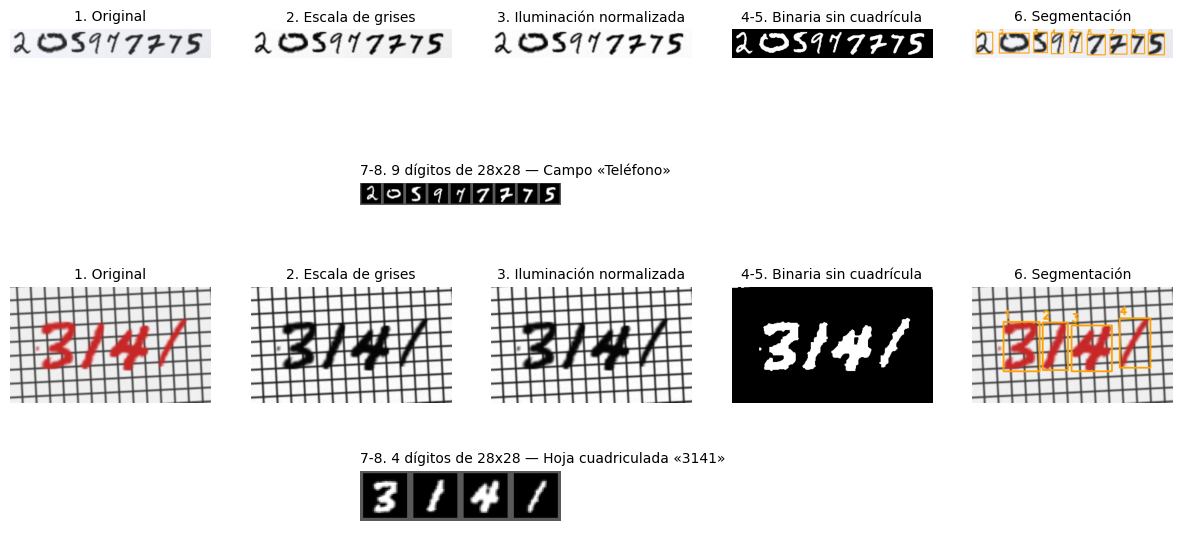

In [6]:
casos = [("Campo «" + campos_ejemplo[2]["etiqueta"] + "»", recortar_campo(formulario_ejemplo, campos_ejemplo[2]["caja"]), len(campos_ejemplo[2]["valor"])),
         ("Hoja cuadriculada «" + cuadriculados[0][0] + "»", cuadriculados[0][1], len(cuadriculados[0][0]))]
etapas = [("original", "1. Original"), ("gris", "2. Escala de grises"), ("iluminacion", "3. Iluminación normalizada"),
          ("binaria", "4-5. Binaria sin cuadrícula"), ("segmentacion", "6. Segmentación")]
figura, ejes = plt.subplots(len(casos) * 2, 5, figsize=(15, 7.5), gridspec_kw={"height_ratios": [3, 1] * len(casos)})
for fila, (titulo, imagen, esperado) in enumerate(casos):
    r = procesar_foto(imagen, esperado)
    for col, (clave, nombre) in enumerate(etapas):
        img = r["pasos"][clave]
        ejes[2 * fila, col].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB) if img.ndim == 3 else img, cmap=None if img.ndim == 3 else "gray")
        ejes[2 * fila, col].set_title(nombre, fontsize=10); ejes[2 * fila, col].axis("off")
    ejes[2 * fila, 0].set_ylabel(titulo)
    for col in range(5):
        ejes[2 * fila + 1, col].axis("off")
    tira = np.hstack([np.pad(rec, 2, constant_values=90) for rec in r["recortes"]]) if r["recortes"] else np.zeros((28, 28))
    eje = ejes[2 * fila + 1, 0]
    eje.imshow(tira, cmap="gray"); eje.set_title(f"7-8. {len(r['recortes'])} dígitos de 28x28 — {titulo}", fontsize=10, loc="left")
    eje.set_position([eje.get_position().x0, eje.get_position().y0, 0.6, eje.get_position().height])
guardar_figura(figura, "preprocesado_pasos")

## Paso 7 · ¿Qué tan bien separa los dígitos? (datos ficticios)

**Qué hace:** mide la **segmentación** en 120 imágenes ficticias de tres tipos: hoja lisa, hoja cuadriculada y campos de formulario.

**Cómo funciona:** cuenta en qué porcentaje de imágenes se encontró **exactamente** la cantidad de dígitos que tiene el número.
Se mide dos veces: sin decirle cuántos dígitos hay y diciéndoselo (en la aplicación la persona escribe el número de cada foto, y en un
formulario se sabe cuántas cifras lleva cada campo).

In [7]:
gen_seg = GeneradorDigitos(x_ent, y_ent, semilla=7)
pruebas_seg = []
for _ in range(40):
    n = gen_seg.numero_aleatorio(int(gen_seg.azar.integers(2, 7)))
    pruebas_seg.append(("Hoja lisa", gen_seg.foto_numero(n, float(gen_seg.azar.uniform(0.2, 0.8))), n))
for _ in range(40):
    n = gen_seg.numero_aleatorio(int(gen_seg.azar.integers(2, 6)))
    pruebas_seg.append(("Hoja cuadriculada", gen_seg.foto_cuadriculada(n, float(gen_seg.azar.uniform(0.2, 0.8))), n))
for i in range(10):
    hoja, campos = gen_seg.formulario(list(TIPOS_FORMULARIO)[i % 3], float(gen_seg.azar.uniform(0.2, 0.7)))
    pruebas_seg += [("Campo de formulario", recortar_campo(hoja, c["caja"]), c["valor"]) for c in campos]

filas = []
for tipo, imagen, numero in pruebas_seg:
    filas.append({"tipo": tipo, "sin ayuda": len(procesar_foto(imagen)["cajas"]) == len(numero),
                  "sabiendo cuántos": len(procesar_foto(imagen, len(numero))["cajas"]) == len(numero)})
segmentacion = pd.DataFrame(filas).groupby("tipo").agg(imagenes=("sin ayuda", "size"), sin_ayuda=("sin ayuda", "mean"),
                                                       sabiendo_cuantos=("sabiendo cuántos", "mean"))
segmentacion[["sin_ayuda", "sabiendo_cuantos"]] *= 100
display(segmentacion.round(1).rename(columns={"sin_ayuda": "% bien separadas (sin ayuda)", "sabiendo_cuantos": "% bien separadas (sabiendo cuántos)"}))

,imagenes,% bien separadas (sin ayuda),% bien separadas (sabiendo cuántos)
tipo,,,
Campo de formulario,40,100.0,100.0
Hoja cuadriculada,40,77.5,100.0
Hoja lisa,40,100.0,100.0


## Paso 8 · Los dígitos de MNIST ya vienen preparados

**Qué hace:** comprueba que los dígitos que salen del preprocesado (paso 6) y los de MNIST tienen la misma forma, para que
lo aprendido con MNIST sirva en las fotos.

**Cómo funciona:** MNIST ya está en escala de grises, centrado por centro de masa en 28 × 28 y con el dígito de unos 20 px. Por eso
el paso 7 del preprocesado (recortar como MNIST) copia exactamente esa receta. Abajo, el promedio de cada dígito en MNIST: la
«forma típica» que aprenderán los modelos.

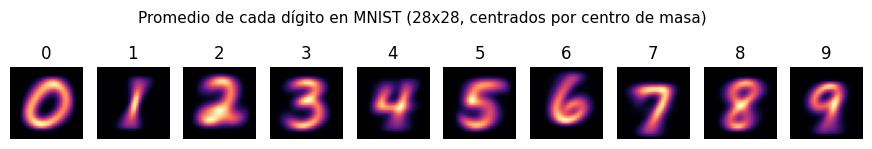

In [8]:
figura, ejes = plt.subplots(1, 10, figsize=(11, 1.6))
for d in range(10):
    ejes[d].imshow(x_ent[y_ent == d].mean(axis=0).reshape(28, 28), cmap="magma"); ejes[d].axis("off"); ejes[d].set_title(str(d))
figura.suptitle("Promedio de cada dígito en MNIST (28x28, centrados por centro de masa)", fontsize=11, y=1.08)
guardar_figura(figura, "mnist_promedios")

## Paso 9 · Selección de algoritmos

**Qué hace:** define los siete modelos que se comparan, con el mismo código que la aplicación.

**Por qué estos algoritmos:**

| Modelo | Tipo | Por qué se eligió | Cómo decide |
| --- | --- | --- | --- |
| **CNN** (principal) | Red neuronal convolucional, supervisada | Las capas convolucionales detectan trazos, curvas y esquinas sin importar dónde estén: es el estándar para imágenes | Filtros aprendidos → capas densas → softmax con 10 probabilidades |
| MLP | Red neuronal densa, supervisada | Red neuronal sin convoluciones: muestra cuánto aportan las capas convolucionales | 784 píxeles → 2 capas ocultas → softmax |
| SVM (núcleo RBF) | Supervisado | Muy fuerte con pocos datos; alternativa clásica pedida en el caso | Frontera de máximo margen en un espacio transformado (sobre 50 componentes PCA) |
| KNN | Supervisado, basado en ejemplos | Alternativa pedida en el caso; sencillo de explicar | Mira los *k* dígitos guardados más parecidos y vota (pesado por distancia, sobre PCA) |
| Regresión logística | Supervisado, lineal | Modelo de **regresión** base: un peso por píxel y por dígito | Probabilidad con softmax de una combinación lineal de los píxeles |
| Regresión lineal | Supervisado, lineal | Pedida en el caso (regresión); muestra el límite de un modelo lineal simple | Mínimos cuadrados con un objetivo 1/0 por dígito; gana el puntaje mayor |
| K-Means | **No supervisado** + etiqueta por mayoría | Pedido en el caso; agrupa sin usar etiquetas | Forma grupos de dígitos parecidos; cada grupo toma el dígito más común de sus miembros |

**PCA (50 componentes)** reduce los 784 píxeles a 50 valores que guardan la mayor parte de la información: SVM, KNN y K-Means
trabajan así mucho más rápido y con menos ruido.

In [9]:
MEDIA_MNIST, DESVIACION_MNIST = 0.1307, 0.3081


def softmax(valores):
    valores = valores - valores.max(axis=1, keepdims=True)
    e = np.exp(valores)
    return e / e.sum(axis=1, keepdims=True)


class ModeloBase:
    clave = ""

    def __init__(self, **parametros):
        self.parametros = {**PARAMETROS_INICIALES[self.clave], **parametros}

    def predecir(self, X):
        return self.probabilidades(X).argmax(axis=1)


class RedNeuronal(ModeloBase):
    # Base de la CNN y la MLP (PyTorch): optimizador Adam, entropía cruzada, lotes de 128
    def entrenar(self, X, y, X_val=None, y_val=None, mostrar=False):
        torch.manual_seed(SEMILLA)
        self.red = self.construir().to(DISPOSITIVO)
        optimizador = torch.optim.Adam(self.red.parameters(), lr=self.parametros["tasa_aprendizaje"])
        perdida_fn = nn.CrossEntropyLoss()
        X_t, y_t = torch.from_numpy(X), torch.from_numpy(y)
        historial = []
        for epoca in range(1, self.parametros["epocas"] + 1):
            inicio = time.perf_counter()
            self.red.train()
            orden = torch.randperm(len(y_t))
            perdida_total, aciertos = 0.0, 0
            for i in range(0, len(y_t), 128):
                indices = orden[i: i + 128]
                lote_x, lote_y = self.preparar(X_t[indices]).to(DISPOSITIVO), y_t[indices].to(DISPOSITIVO)
                optimizador.zero_grad()
                salida = self.red(lote_x)
                perdida = perdida_fn(salida, lote_y)
                perdida.backward()
                optimizador.step()
                perdida_total += perdida.item() * len(indices)
                aciertos += (salida.argmax(1) == lote_y).sum().item()
            registro = {"epoca": epoca, "perdida": perdida_total / len(y_t), "exactitud": aciertos / len(y_t),
                        "segundos": time.perf_counter() - inicio}
            if X_val is not None:
                registro["exactitud_val"] = float((self.predecir(X_val) == y_val).mean())
            historial.append(registro)
            if mostrar:
                print(f"  época {epoca}: pérdida {registro['perdida']:.4f} | exactitud {registro['exactitud']:.4f}"
                      + (f" | validación {registro['exactitud_val']:.4f}" if X_val is not None else ""))
        return historial

    def probabilidades(self, X):
        self.red.eval()
        salida = []
        with torch.no_grad():
            for i in range(0, len(X), 2048):
                lote = self.preparar(torch.from_numpy(X[i: i + 2048])).to(DISPOSITIVO)
                salida.append(torch.softmax(self.red(lote), dim=1).cpu().numpy())
        return np.concatenate(salida)

    def total_parametros(self):
        return int(sum(p.numel() for p in self.red.parameters()))

    def actualizar(self, X_nuevo, y_nuevo, X_memoria, y_memoria, fuerza=1.0):
        # Ajuste fino con los dígitos corregidos mezclados con memoria, a tasa baja para no olvidar
        torch.manual_seed(SEMILLA + 1)
        X_t = torch.from_numpy(np.concatenate([X_nuevo, X_memoria]))
        y_t = torch.from_numpy(np.concatenate([y_nuevo, y_memoria]))
        optimizador = torch.optim.Adam(self.red.parameters(), lr=self.parametros["tasa_aprendizaje"] * 0.12 * fuerza)
        perdida_fn = nn.CrossEntropyLoss()
        for _ in range(4):
            self.red.train()
            orden = torch.randperm(len(y_t))
            for i in range(0, len(y_t), 64):
                indices = orden[i: i + 64]
                optimizador.zero_grad()
                perdida = perdida_fn(self.red(self.preparar(X_t[indices]).to(DISPOSITIVO)), y_t[indices].to(DISPOSITIVO))
                perdida.backward()
                optimizador.step()


class ModeloCNN(RedNeuronal):
    clave = "cnn"

    def preparar(self, lote):
        return ((lote - MEDIA_MNIST) / DESVIACION_MNIST).view(-1, 1, 28, 28)

    def construir(self):
        f, p = self.parametros["filtros"], self.parametros["dropout"]
        return nn.Sequential(
            nn.Conv2d(1, f, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),          # bloque 1: bordes y trazos
            nn.Conv2d(f, 2 * f, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),      # bloque 2: curvas, esquinas, partes del dígito
            nn.Flatten(), nn.Dropout(p),
            nn.Linear(2 * f * 7 * 7, 64), nn.ReLU(), nn.Dropout(p),
            nn.Linear(64, 10),                                                   # 10 salidas (softmax en la pérdida)
        )


class ModeloMLP(RedNeuronal):
    clave = "mlp"

    def preparar(self, lote):
        return (lote - MEDIA_MNIST) / DESVIACION_MNIST

    def construir(self):
        n, p = self.parametros["neuronas"], self.parametros["dropout"]
        return nn.Sequential(nn.Linear(784, n), nn.ReLU(), nn.Dropout(p), nn.Linear(n, n // 2), nn.ReLU(), nn.Linear(n // 2, 10))


class ModeloClasico(ModeloBase):
    # Modelos de scikit-learn que trabajan sobre 50 componentes PCA
    def ajustar_pca(self, X):
        self.pca = PCA(n_components=self.parametros["componentes"], random_state=SEMILLA).fit(X)
        return self.pca.transform(X)

    def proyectar(self, X):
        return self.pca.transform(X)

    def entrenar(self, X, y, X_val=None, y_val=None, mostrar=False):
        self.ajustar(X, y)
        return []


class ModeloSVM(ModeloClasico):
    clave = "svm"

    def ajustar(self, X, y):
        self.modelo = SVC(kernel="rbf", C=self.parametros["C"], gamma=self.parametros["gamma"]).fit(self.ajustar_pca(X), y)

    def probabilidades(self, X):
        return softmax(2.0 * self.modelo.decision_function(self.proyectar(X)))

    def actualizar(self, X_nuevo, y_nuevo, X_memoria, y_memoria, fuerza=1.0):
        # Reentrena con los vectores de soporte anteriores (definen la frontera), la memoria y lo nuevo
        anterior = self.modelo
        Z = np.concatenate([anterior.support_vectors_, self.proyectar(X_memoria), self.proyectar(X_nuevo)])
        etiquetas = np.concatenate([np.repeat(anterior.classes_, anterior.n_support_), y_memoria, y_nuevo])
        self.modelo = SVC(kernel="rbf", C=self.parametros["C"], gamma=self.parametros["gamma"]).fit(Z, etiquetas)


class ModeloKNN(ModeloClasico):
    clave = "knn"

    def ajustar(self, X, y):
        self.modelo = KNeighborsClassifier(n_neighbors=self.parametros["k"], weights="distance", n_jobs=-1).fit(self.ajustar_pca(X), y)

    def probabilidades(self, X):
        return self.modelo.predict_proba(self.proyectar(X))

    def actualizar(self, X_nuevo, y_nuevo, X_memoria, y_memoria, fuerza=1.0):
        # Aprender es memorizar los dígitos nuevos junto a los que ya tenía
        anterior = self.modelo
        Z = np.concatenate([anterior._fit_X, self.proyectar(X_nuevo)])
        etiquetas = np.concatenate([anterior.classes_[anterior._y], y_nuevo])
        self.modelo = KNeighborsClassifier(n_neighbors=self.parametros["k"], weights="distance", n_jobs=-1).fit(Z, etiquetas)


class ModeloRegresion(ModeloClasico):
    clave = "regresion"

    def ajustar(self, X, y):
        self.modelo = LogisticRegression(C=self.parametros["C"], max_iter=self.parametros["iteraciones"]).fit(X, y)

    def probabilidades(self, X):
        return self.modelo.predict_proba(X)

    def actualizar(self, X_nuevo, y_nuevo, X_memoria, y_memoria, fuerza=1.0):
        # Sigue la optimización desde los pesos actuales (warm start) con lo nuevo y la memoria
        anterior = self.modelo
        continuado = LogisticRegression(C=self.parametros["C"], max_iter=self.parametros["iteraciones"], warm_start=True)
        continuado.coef_, continuado.intercept_, continuado.classes_ = anterior.coef_.copy(), anterior.intercept_.copy(), anterior.classes_
        continuado.fit(np.concatenate([X_nuevo, X_memoria]), np.concatenate([y_nuevo, y_memoria]))
        self.modelo = continuado


class ModeloRegresionLineal(ModeloClasico):
    # Mínimos cuadrados con una salida por dígito (objetivo 1 para el correcto y 0 para el resto)
    clave = "regresion_lineal"

    @staticmethod
    def con_sesgo(X):
        return np.hstack([X.astype(np.float64), np.ones((len(X), 1))])

    def resolver(self):
        regularizacion = self.parametros["alpha"] * np.eye(self.A.shape[0]); regularizacion[-1, -1] = 0.0
        self.pesos = np.linalg.solve(self.A + regularizacion, self.B)

    def ajustar(self, X, y):
        X1 = self.con_sesgo(X)
        self.A, self.B = X1.T @ X1, X1.T @ np.eye(10)[y]   # se guardan: aprender después es solo sumar
        self.resolver()

    def actualizar(self, X_nuevo, y_nuevo, X_memoria, y_memoria, fuerza=1.0):
        X1 = self.con_sesgo(X_nuevo)
        self.A = self.A + fuerza * (X1.T @ X1)
        self.B = self.B + fuerza * (X1.T @ np.eye(10)[y_nuevo])
        self.resolver()

    def probabilidades(self, X):
        return softmax(6.0 * (self.con_sesgo(X) @ self.pesos))


class ModeloKMeans(ModeloClasico):
    # No supervisado: agrupa y luego cada grupo toma el dígito más común de sus miembros
    clave = "kmeans"

    def ajustar(self, X, y):
        Z = self.ajustar_pca(X)
        self.modelo = KMeans(n_clusters=self.parametros["clusteres"], n_init=3, random_state=SEMILLA).fit(Z)
        self.etiqueta_cluster = np.array([np.bincount(y[self.modelo.labels_ == c], minlength=10).argmax()
                                          if (self.modelo.labels_ == c).any() else 0 for c in range(self.parametros["clusteres"])])

    def probabilidades(self, X):
        distancias = self.modelo.transform(self.proyectar(X))
        minimas = np.full((len(distancias), 10), 1e6)
        for d in range(10):
            columnas = np.flatnonzero(self.etiqueta_cluster == d)
            if len(columnas):
                minimas[:, d] = distancias[:, columnas].min(axis=1)
        return softmax(-(minimas - minimas.min(axis=1, keepdims=True)))

    def actualizar(self, X_nuevo, y_nuevo, X_memoria, y_memoria, fuerza=1.0):
        # Los dígitos mal asignados forman grupos nuevos con el dígito correcto
        Z = self.proyectar(X_nuevo)
        cercano = self.modelo.predict(Z)
        equivocado = self.etiqueta_cluster[cercano] != y_nuevo
        centros, etiquetas = [], []
        for etiqueta in np.unique(y_nuevo[equivocado]):
            for grupo in np.unique(cercano[equivocado & (y_nuevo == etiqueta)]):
                marca = equivocado & (y_nuevo == etiqueta) & (cercano == grupo)
                centros.append(Z[marca].mean(axis=0)); etiquetas.append(etiqueta)
        if centros:
            existentes = self.modelo.cluster_centers_
            self.modelo.cluster_centers_ = np.vstack([existentes, np.asarray(centros, dtype=existentes.dtype)])
            self.etiqueta_cluster = np.concatenate([self.etiqueta_cluster, etiquetas])


CLASES_MODELOS = {"cnn": ModeloCNN, "mlp": ModeloMLP, "svm": ModeloSVM, "knn": ModeloKNN,
                  "regresion": ModeloRegresion, "regresion_lineal": ModeloRegresionLineal, "kmeans": ModeloKMeans}


def crear_modelo(clave, **parametros):
    return CLASES_MODELOS[clave](**parametros)


print("Modelos definidos:", ", ".join(NOMBRES[c] for c in CLAVES))

Modelos definidos: CNN (red convolucional), MLP (red densa), SVM (RBF), KNN, Regresión logística, Regresión lineal, K-Means


## Paso 10 · Arquitectura de las redes neuronales

**Qué hace:** describe capa por capa la **CNN** (el modelo principal) y la MLP: forma de salida, nodos, función de activación,
cantidad de parámetros y estrategia de optimización. Se calcula con los hiperparámetros que gane la validación cruzada (paso 11),
así que esta tabla se vuelve a mostrar con los valores finales en el paso 12.

**Cómo funciona la CNN:**
- **Capas convolucionales** (3 × 3): cada filtro recorre la imagen buscando un patrón (un borde, una curva). El primer bloque encuentra
  trazos simples; el segundo los combina en partes del dígito. Esto es la **extracción de características**.
- **MaxPool 2 × 2**: reduce la imagen a la mitad quedándose con lo más fuerte; da tolerancia a pequeños desplazamientos.
- **ReLU**: activación que deja pasar solo lo positivo; hace que la red aprenda relaciones no lineales.
- **Dropout**: apaga neuronas al azar al entrenar para que no memorice (evita el sobreajuste).
- **Softmax** en la salida: 10 probabilidades que suman 1; gana el dígito más probable.
- **Optimización:** Adam (ajusta la tasa de aprendizaje de cada peso), pérdida de **entropía cruzada**, lotes de 128 imágenes.

**CNN con los valores de partida** (se ajustan en el paso 11):

,Capa,Forma de salida,Nodos / filtros,Activación,Parámetros
0,Entrada,28 x 28 x 1,-,-,0
1,Conv2D 3x3 (relleno 1),28 x 28 x 16,16 filtros,ReLU,160
2,MaxPool 2x2,14 x 14 x 16,-,-,0
3,Conv2D 3x3 (relleno 1),14 x 14 x 32,32 filtros,ReLU,4640
4,MaxPool 2x2,7 x 7 x 32,-,-,0
5,Aplanar,1568,-,-,0
6,Dropout,1568,"p = 0,25",-,0
7,Densa,64,64 neuronas,ReLU,100416
8,Dropout,64,"p = 0,25",-,0
9,Densa (salida),10,10 neuronas (dígitos 0-9),Softmax,650


,valor
Parámetros totales,105866
Optimizador,Adam
Tasa de aprendizaje,0.003
Función de pérdida,Entropía cruzada
Tamaño de lote,128
Épocas,3
Dropout,0.25


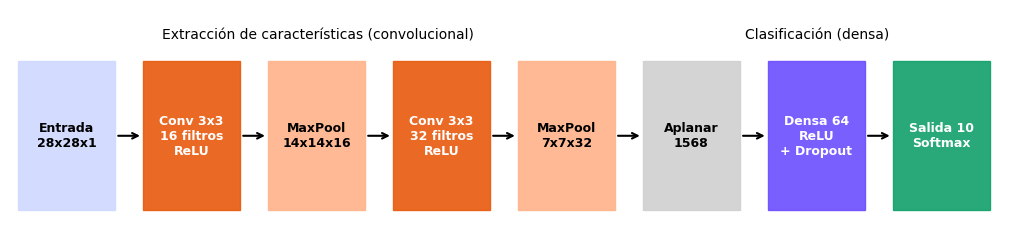

Sequential(
  (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Flatten(start_dim=1, end_dim=-1)
  (7): Dropout(p=0.25, inplace=False)
  (8): Linear(in_features=1568, out_features=64, bias=True)
  (9): ReLU()
  (10): Dropout(p=0.25, inplace=False)
  (11): Linear(in_features=64, out_features=10, bias=True)
)


In [10]:
def tabla_arquitectura(clave, parametros):
    p = {**PARAMETROS_INICIALES[clave], **parametros}
    d = str(p["dropout"]).replace(".", ",")
    if clave == "cnn":
        f = p["filtros"]
        capas = [("Entrada", "28 x 28 x 1", "-", "-", 0),
                 ("Conv2D 3x3 (relleno 1)", f"28 x 28 x {f}", f"{f} filtros", "ReLU", 9 * f + f),
                 ("MaxPool 2x2", f"14 x 14 x {f}", "-", "-", 0),
                 ("Conv2D 3x3 (relleno 1)", f"14 x 14 x {2 * f}", f"{2 * f} filtros", "ReLU", 9 * f * 2 * f + 2 * f),
                 ("MaxPool 2x2", f"7 x 7 x {2 * f}", "-", "-", 0),
                 ("Aplanar", f"{2 * f * 49}", "-", "-", 0),
                 ("Dropout", f"{2 * f * 49}", f"p = {d}", "-", 0),
                 ("Densa", "64", "64 neuronas", "ReLU", 2 * f * 49 * 64 + 64),
                 ("Dropout", "64", f"p = {d}", "-", 0),
                 ("Densa (salida)", "10", "10 neuronas (dígitos 0-9)", "Softmax", 64 * 10 + 10)]
    else:
        n = p["neuronas"]
        capas = [("Entrada", "784", "28x28 aplanado", "-", 0),
                 ("Densa", f"{n}", f"{n} neuronas", "ReLU", 784 * n + n),
                 ("Dropout", f"{n}", f"p = {d}", "-", 0),
                 ("Densa", f"{n // 2}", f"{n // 2} neuronas", "ReLU", n * (n // 2) + n // 2),
                 ("Densa (salida)", "10", "10 neuronas (dígitos 0-9)", "Softmax", (n // 2) * 10 + 10)]
    tabla = pd.DataFrame(capas, columns=["Capa", "Forma de salida", "Nodos / filtros", "Activación", "Parámetros"])
    resumen = {"Parámetros totales": int(tabla["Parámetros"].sum()), "Optimizador": "Adam",
               "Tasa de aprendizaje": p["tasa_aprendizaje"], "Función de pérdida": "Entropía cruzada",
               "Tamaño de lote": 128, "Épocas": p["epocas"], "Dropout": p["dropout"]}
    return tabla, resumen


def dibujar_cnn(f, nombre):
    figura, eje = plt.subplots(figsize=(13, 2.8))
    bloques = [("Entrada\n28x28x1", "#cfd8ff"), (f"Conv 3x3\n{f} filtros\nReLU", "#e8590c"), (f"MaxPool\n14x14x{f}", "#ffb38a"),
               (f"Conv 3x3\n{2 * f} filtros\nReLU", "#e8590c"), (f"MaxPool\n7x7x{2 * f}", "#ffb38a"), (f"Aplanar\n{2 * f * 49}", "#d0d0d0"),
               ("Densa 64\nReLU\n+ Dropout", "#6c4dff"), ("Salida 10\nSoftmax", "#12a06a")]
    for i, (texto, color) in enumerate(bloques):
        eje.add_patch(plt.Rectangle((i * 1.6, 0), 1.25, 1, color=color, alpha=0.9))
        eje.text(i * 1.6 + 0.625, 0.5, texto, ha="center", va="center", fontsize=9, color="white" if color in ("#e8590c", "#6c4dff", "#12a06a") else "black", fontweight="bold")
        if i:
            eje.annotate("", xy=(i * 1.6, 0.5), xytext=(i * 1.6 - 0.35, 0.5), arrowprops={"arrowstyle": "->", "lw": 1.5})
    eje.text(1.6 * 2.4, 1.15, "Extracción de características (convolucional)", ha="center", fontsize=10)
    eje.text(1.6 * 6.4, 1.15, "Clasificación (densa)", ha="center", fontsize=10)
    eje.set_xlim(-0.1, len(bloques) * 1.6); eje.set_ylim(-0.1, 1.35); eje.axis("off")
    guardar_figura(figura, nombre)


tabla, resumen = tabla_arquitectura("cnn", {})
display(Markdown("**CNN con los valores de partida** (se ajustan en el paso 11):"))
display(tabla)
display(pd.Series(resumen, name="valor").to_frame())
dibujar_cnn(PARAMETROS_INICIALES["cnn"]["filtros"], "arquitectura_cnn_inicial")
print(ModeloCNN().construir())

## Paso 11 · Validación cruzada y ajuste de hiperparámetros

**Qué hace:** elige los mejores hiperparámetros de cada modelo **sin mirar el test**.

**Cómo funciona:**
- Se toman 5000 dígitos de entrenamiento (proporción igual de cada dígito) y se dividen en **5 pliegues** (`StratifiedKFold`).
- Cada combinación de la malla se entrena 5 veces: con 4 pliegues aprende y con el quinto se mide. La nota es el **promedio** de las 5
  medidas; la **desviación** muestra si el resultado es estable.
- Se prueban: CNN (filtros 8/16 × tasa 0,001/0,003), MLP (neuronas 64/128 × tasa), SVM (C 1/10 × gamma), KNN (k = 1, 3, 5, 7),
  regresión logística (C = 0,1/1/10), regresión lineal (alpha = 0,1/1/10/100) y K-Means (10/30/60 grupos).
- En la validación cruzada las redes entrenan 2 épocas (para que sea rápido); el modelo final entrena las épocas completas.

CNN (red convolucional)  mejor: {'filtros': 16, 'tasa_aprendizaje': 0.003}  ->  0.9416 (± 0.0065)


MLP (red densa)          mejor: {'neuronas': 128, 'tasa_aprendizaje': 0.003}  ->  0.9014 (± 0.0123)


SVM (RBF)                mejor: {'C': 10, 'gamma': 0.05}  ->  0.9608 (± 0.0057)


KNN                      mejor: {'k': 7}  ->  0.9398 (± 0.0078)


Regresión logística      mejor: {'C': 0.1}  ->  0.9034 (± 0.0093)


Regresión lineal         mejor: {'alpha': 100.0}  ->  0.8568 (± 0.0065)


K-Means                  mejor: {'clusteres': 60}  ->  0.8140 (± 0.0154)

Validación cruzada completa en 183 s


,Modelo,Hiperparámetros,Exactitud media,Desviación,Elegido,Segundos
0,CNN,"filtros=16, tasa_aprendizaje=0.003",0.9416,0.0065,✔,18.0
1,CNN,"filtros=8, tasa_aprendizaje=0.003",0.9280,0.0096,,10.0
2,CNN,"filtros=16, tasa_aprendizaje=0.001",0.8992,0.0039,,21.2
3,CNN,"filtros=8, tasa_aprendizaje=0.001",0.8912,0.0124,,25.3
4,MLP,"neuronas=128, tasa_aprendizaje=0.003",0.9014,0.0123,✔,2.3
5,MLP,"neuronas=64, tasa_aprendizaje=0.003",0.8966,0.0101,,1.1
6,MLP,"neuronas=128, tasa_aprendizaje=0.001",0.8862,0.0084,,1.7
7,MLP,"neuronas=64, tasa_aprendizaje=0.001",0.8662,0.0168,,1.1
8,SVM,"C=10, gamma=0.05",0.9608,0.0057,✔,7.3
9,SVM,"C=1, gamma=0.05",0.9592,0.0070,,7.0


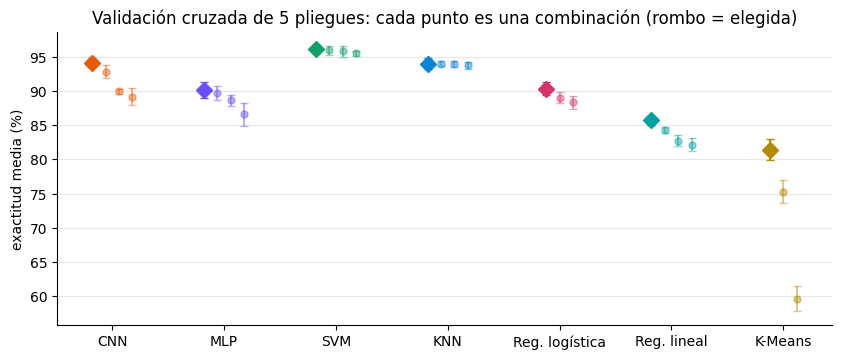

In [11]:
def validacion_cruzada(clave, X, y, parametros_fijos=None):
    grilla = GRILLAS[clave]
    divisor = StratifiedKFold(n_splits=PLIEGUES, shuffle=True, random_state=SEMILLA)
    resultados = []
    for valores in itertools.product(*grilla.values()):
        combinacion = dict(zip(grilla, valores))
        exactitudes, inicio = [], time.perf_counter()
        for entrenamiento, validacion in divisor.split(X, y):
            modelo = crear_modelo(clave, **{**(parametros_fijos or {}), **combinacion})
            modelo.entrenar(X[entrenamiento], y[entrenamiento])
            exactitudes.append(float((modelo.predecir(X[validacion]) == y[validacion]).mean()))
        resultados.append({"parametros": combinacion, "exactitud_media": float(np.mean(exactitudes)),
                           "desviacion": float(np.std(exactitudes)), "pliegues": exactitudes,
                           "segundos": time.perf_counter() - inicio})
    return sorted(resultados, key=lambda r: r["exactitud_media"], reverse=True)


X_cv, y_cv = submuestra_estratificada(x_ent, y_ent, MUESTRAS_VALIDACION_CRUZADA)
VALIDACION, MEJORES = {}, {}
inicio_total = time.perf_counter()
for clave in CLAVES:
    VALIDACION[clave] = validacion_cruzada(clave, X_cv, y_cv, {"epocas": 2} if clave in ("cnn", "mlp") else None)
    MEJORES[clave] = VALIDACION[clave][0]["parametros"]
    print(f"{NOMBRES[clave]:<24} mejor: {MEJORES[clave]}  ->  {VALIDACION[clave][0]['exactitud_media']:.4f} "
          f"(± {VALIDACION[clave][0]['desviacion']:.4f})")
print(f"\nValidación cruzada completa en {time.perf_counter() - inicio_total:.0f} s")

filas = []
for clave in CLAVES:
    for posicion, r in enumerate(VALIDACION[clave]):
        filas.append({"Modelo": CORTOS[clave], "Hiperparámetros": ", ".join(f"{k}={v}" for k, v in r["parametros"].items()),
                      "Exactitud media": r["exactitud_media"], "Desviación": r["desviacion"],
                      "Elegido": "✔" if posicion == 0 else "", "Segundos": round(r["segundos"], 1)})
tabla_cv = pd.DataFrame(filas)
display(tabla_cv)

figura, eje = plt.subplots(figsize=(10, 3.8))
for i, clave in enumerate(CLAVES):
    for j, r in enumerate(VALIDACION[clave]):
        eje.errorbar(i + (j - (len(VALIDACION[clave]) - 1) / 2) * 0.12, r["exactitud_media"] * 100, yerr=r["desviacion"] * 100,
                     fmt="o" if j else "D", color=COLORES[clave], alpha=1 if j == 0 else 0.45, ms=8 if j == 0 else 5, capsize=3)
eje.set_xticks(range(len(CLAVES))); eje.set_xticklabels([CORTOS[c] for c in CLAVES])
eje.set_ylabel("exactitud media (%)"); eje.set_title("Validación cruzada de 5 pliegues: cada punto es una combinación (rombo = elegida)")
eje.grid(axis="y", alpha=0.3)
guardar_figura(figura, "validacion_cruzada")

## Paso 12 · Entrenamiento final

**Qué hace:** entrena cada modelo con sus **mejores hiperparámetros** y con más datos: 30 000 dígitos (SVM 10 000 y KNN 20 000,
igual que la aplicación, porque con más se vuelven muy lentos al predecir).

**Cómo funciona:** en cada época la red ve todas las imágenes en lotes de 128, calcula el error (entropía cruzada) y Adam corrige los pesos
(retropropagación). Después de cada época se mide la exactitud en 2000 dígitos aparte para ver si sigue mejorando o empieza a
**sobreajustar** (aprende de memoria). Las curvas muestran la pérdida bajando y la exactitud subiendo.

CNN (red convolucional) con 30 000 dígitos y {'filtros': 16, 'tasa_aprendizaje': 0,003, 'epocas': 3, 'dropout': 0,25}


  época 1: pérdida 0.3241 | exactitud 0.8978 | validación 0.9730


  época 2: pérdida 0.1096 | exactitud 0.9657 | validación 0.9780


  época 3: pérdida 0.0834 | exactitud 0.9738 | validación 0.9825
  entrenado en 51.5 s
MLP (red densa) con 30 000 dígitos y {'neuronas': 128, 'tasa_aprendizaje': 0,003, 'epocas': 8, 'dropout': 0,2}


  época 1: pérdida 0.3746 | exactitud 0.8822 | validación 0.9340


  época 2: pérdida 0.1825 | exactitud 0.9439 | validación 0.9410


... (7 outputs left out)

  entrenado en 0.5 s
Regresión logística con 30 000 dígitos y {'C': 0,1, 'iteraciones': 200}


  entrenado en 12.8 s
Regresión lineal con 30 000 dígitos y {'alpha': 100,0}


  entrenado en 2.2 s
K-Means con 30 000 dígitos y {'clusteres': 60, 'componentes': 50}


  entrenado en 8.7 s


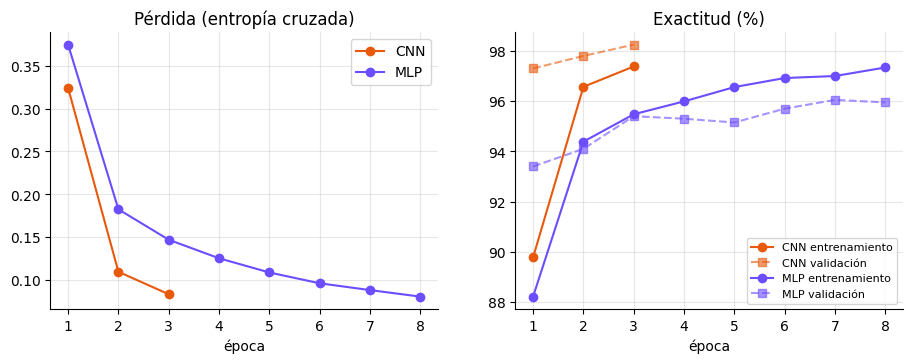

**Arquitectura final de la CNN** (con los hiperparámetros elegidos):

,Capa,Forma de salida,Nodos / filtros,Activación,Parámetros
0,Entrada,28 x 28 x 1,-,-,0
1,Conv2D 3x3 (relleno 1),28 x 28 x 16,16 filtros,ReLU,160
2,MaxPool 2x2,14 x 14 x 16,-,-,0
3,Conv2D 3x3 (relleno 1),14 x 14 x 32,32 filtros,ReLU,4640
4,MaxPool 2x2,7 x 7 x 32,-,-,0
5,Aplanar,1568,-,-,0
6,Dropout,1568,"p = 0,25",-,0
7,Densa,64,64 neuronas,ReLU,100416
8,Dropout,64,"p = 0,25",-,0
9,Densa (salida),10,10 neuronas (dígitos 0-9),Softmax,650


,valor
Parámetros totales,105866
Optimizador,Adam
Tasa de aprendizaje,0.003
Función de pérdida,Entropía cruzada
Tamaño de lote,128
Épocas,3
Dropout,0.25


Parámetros contados por PyTorch: 105866


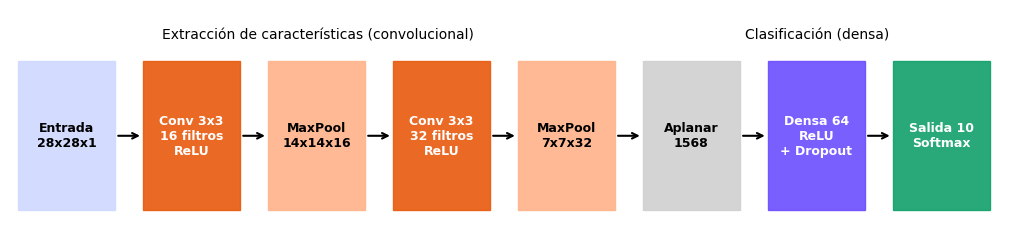

**Arquitectura final de la MLP:**

,Capa,Forma de salida,Nodos / filtros,Activación,Parámetros
0,Entrada,784,28x28 aplanado,-,0
1,Densa,128,128 neuronas,ReLU,100480
2,Dropout,128,"p = 0,2",-,0
3,Densa,64,64 neuronas,ReLU,8256
4,Densa (salida),10,10 neuronas (dígitos 0-9),Softmax,650


,valor
Parámetros totales,109386
Optimizador,Adam
Tasa de aprendizaje,0.003
Función de pérdida,Entropía cruzada
Tamaño de lote,128
Épocas,8
Dropout,0.2


In [12]:
MODELOS, HISTORIALES, TIEMPOS_ENTRENO = {}, {}, {}
for clave in CLAVES:
    X, y = submuestra_estratificada(x_ent, y_ent, MUESTRAS_ENTRENAMIENTO[clave])
    modelo = crear_modelo(clave, **MEJORES[clave])
    print(es(f"{NOMBRES[clave]} con {len(y):,} dígitos y {modelo.parametros}"))
    inicio = time.perf_counter()
    HISTORIALES[clave] = modelo.entrenar(X, y, X_val=x_pru[:2000] if clave in ("cnn", "mlp") else None,
                                         y_val=y_pru[:2000] if clave in ("cnn", "mlp") else None, mostrar=True)
    TIEMPOS_ENTRENO[clave] = time.perf_counter() - inicio
    MODELOS[clave] = modelo
    print(f"  entrenado en {TIEMPOS_ENTRENO[clave]:.1f} s")

figura, ejes = plt.subplots(1, 2, figsize=(11, 3.6))
for clave in ("cnn", "mlp"):
    h = pd.DataFrame(HISTORIALES[clave])
    ejes[0].plot(h["epoca"], h["perdida"], "o-", color=COLORES[clave], label=CORTOS[clave])
    ejes[1].plot(h["epoca"], h["exactitud"] * 100, "o-", color=COLORES[clave], label=f"{CORTOS[clave]} entrenamiento")
    ejes[1].plot(h["epoca"], h["exactitud_val"] * 100, "s--", color=COLORES[clave], alpha=0.6, label=f"{CORTOS[clave]} validación")
ejes[0].set_title("Pérdida (entropía cruzada)"); ejes[0].set_xlabel("época"); ejes[0].legend()
ejes[1].set_title("Exactitud (%)"); ejes[1].set_xlabel("época"); ejes[1].legend(fontsize=8)
for e in ejes:
    e.grid(alpha=0.3)
guardar_figura(figura, "curvas_entrenamiento")

display(Markdown("**Arquitectura final de la CNN** (con los hiperparámetros elegidos):"))
tabla_cnn, resumen_cnn = tabla_arquitectura("cnn", MEJORES["cnn"])
display(tabla_cnn); display(pd.Series(resumen_cnn, name="valor").to_frame())
print("Parámetros contados por PyTorch:", MODELOS["cnn"].total_parametros())
dibujar_cnn(MODELOS["cnn"].parametros["filtros"], "arquitectura_cnn")
display(Markdown("**Arquitectura final de la MLP:**"))
tabla_mlp, resumen_mlp = tabla_arquitectura("mlp", MEJORES["mlp"])
display(tabla_mlp); display(pd.Series(resumen_mlp, name="valor").to_frame())

## Paso 13 · Evaluación con el conjunto de test (datos de internet)

**Qué hace:** cada modelo clasifica los **10 000 dígitos de test** de MNIST, que no vio nunca, y se calculan las métricas.

**Cómo se lee cada métrica:**
- **Exactitud:** de todos los dígitos, qué porcentaje acertó.
- **Precisión** (de un dígito): de las veces que el modelo dijo «es un 7», cuántas era de verdad un 7.
- **Recall** (sensibilidad): de todos los 7 reales, cuántos encontró.
- **F1:** promedio armónico de precisión y recall (alto solo si las dos son altas).
- *Macro* = promedio de los 10 dígitos, todos con el mismo peso.
- **Matriz de confusión:** filas = dígito real, columnas = lo que predijo. La diagonal son los aciertos; fuera de ella, las confusiones.

,Modelo,Exactitud (%),Precisión macro (%),Recall macro (%),F1 macro (%),Errores (de 10 000),Entrenamiento (s),ms por dígito
1,CNN (red convolucional),98.69,98.68,98.68,98.68,131,51.50,0.38
2,SVM (RBF),97.39,97.38,97.38,97.38,261,4.53,0.74
3,MLP (red densa),96.85,96.89,96.80,96.83,315,8.28,0.01
4,KNN,96.78,96.81,96.76,96.77,322,0.46,0.14
5,Regresión logística,92.33,92.23,92.22,92.22,767,12.84,0.01
6,Regresión lineal,86.25,86.46,86.01,86.01,1375,2.20,0.01
7,K-Means,85.04,85.80,84.77,84.66,1496,8.74,0.00


**Métricas por dígito del mejor modelo: CNN (red convolucional)**

,precisión,recall,F1,soporte
dígito,,,,
0,99.39,99.49,99.44,980
1,98.95,99.74,99.34,1135
2,99.12,98.64,98.88,1032
3,99.11,98.71,98.91,1010
4,98.97,97.96,98.46,982
5,98.32,98.54,98.43,892
6,99.06,99.06,99.06,958
7,98.16,98.83,98.50,1028
8,97.36,98.46,97.91,974


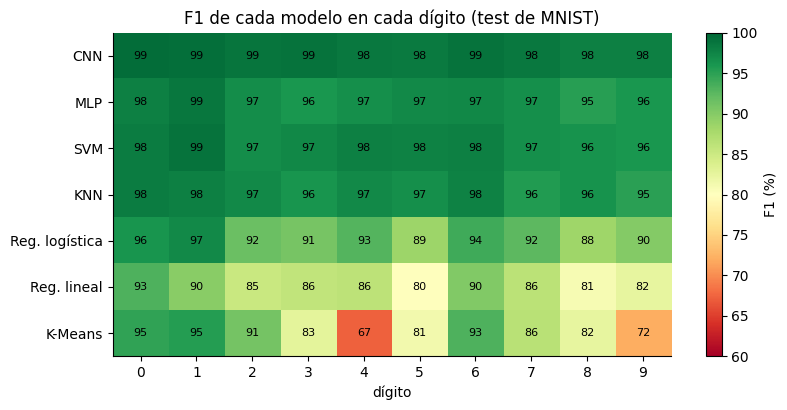

In [13]:
METRICAS, PREDICCIONES = {}, {}
for clave in CLAVES:
    inicio = time.perf_counter()
    predicho = MODELOS[clave].predecir(x_pru)
    ms = 1000 * (time.perf_counter() - inicio) / len(y_pru)
    p, r, f, s = precision_recall_fscore_support(y_pru, predicho, labels=CLASES, zero_division=0)
    pm, rm, fm, _ = precision_recall_fscore_support(y_pru, predicho, labels=CLASES, average="macro", zero_division=0)
    PREDICCIONES[clave] = predicho
    METRICAS[clave] = {"exactitud": accuracy_score(y_pru, predicho), "precision": pm, "recall": rm, "f1": fm,
                       "por_clase": pd.DataFrame({"precisión": p, "recall": r, "F1": f, "soporte": s}, index=CLASES),
                       "matriz": confusion_matrix(y_pru, predicho, labels=CLASES), "ms": ms}

resultados = pd.DataFrame([{"Modelo": NOMBRES[c], "Exactitud (%)": METRICAS[c]["exactitud"] * 100,
                            "Precisión macro (%)": METRICAS[c]["precision"] * 100, "Recall macro (%)": METRICAS[c]["recall"] * 100,
                            "F1 macro (%)": METRICAS[c]["f1"] * 100, "Errores (de 10 000)": int((PREDICCIONES[c] != y_pru).sum()),
                            "Entrenamiento (s)": TIEMPOS_ENTRENO[c], "ms por dígito": METRICAS[c]["ms"]} for c in CLAVES])
resultados = resultados.sort_values("Exactitud (%)", ascending=False).reset_index(drop=True)
resultados.index += 1
display(resultados.round(2))

MEJOR = max(CLAVES, key=lambda c: METRICAS[c]["exactitud"])
display(Markdown(f"**Métricas por dígito del mejor modelo: {NOMBRES[MEJOR]}**"))
tabla_clase = METRICAS[MEJOR]["por_clase"].copy()
tabla_clase.index.name = "dígito"
display((tabla_clase[["precisión", "recall", "F1"]] * 100).round(2).assign(soporte=tabla_clase["soporte"]))

f1_clase = pd.DataFrame({CORTOS[c]: METRICAS[c]["por_clase"]["F1"] * 100 for c in CLAVES})
figura, eje = plt.subplots(figsize=(9, 4.2))
imagen = eje.imshow(f1_clase.T.values, cmap="RdYlGn", vmin=60, vmax=100, aspect="auto")
eje.set_xticks(range(10)); eje.set_xlabel("dígito"); eje.set_yticks(range(len(CLAVES))); eje.set_yticklabels(f1_clase.columns)
for i in range(len(CLAVES)):
    for j in range(10):
        eje.text(j, i, f"{f1_clase.values[j, i]:.0f}", ha="center", va="center", fontsize=8)
figura.colorbar(imagen, label="F1 (%)"); eje.set_title("F1 de cada modelo en cada dígito (test de MNIST)")
guardar_figura(figura, "f1_por_digito")

## Paso 14 · Matrices de confusión de los siete modelos

**Qué hace:** dibuja la matriz de confusión de cada modelo y lista las confusiones más frecuentes.

**Cómo funciona:** se cuenta, para cada dígito real, cuántas veces se predijo cada dígito. Las celdas se pintan según el porcentaje
de su fila. Una matriz con la diagonal oscura y el resto casi blanco es un modelo que casi no se confunde.

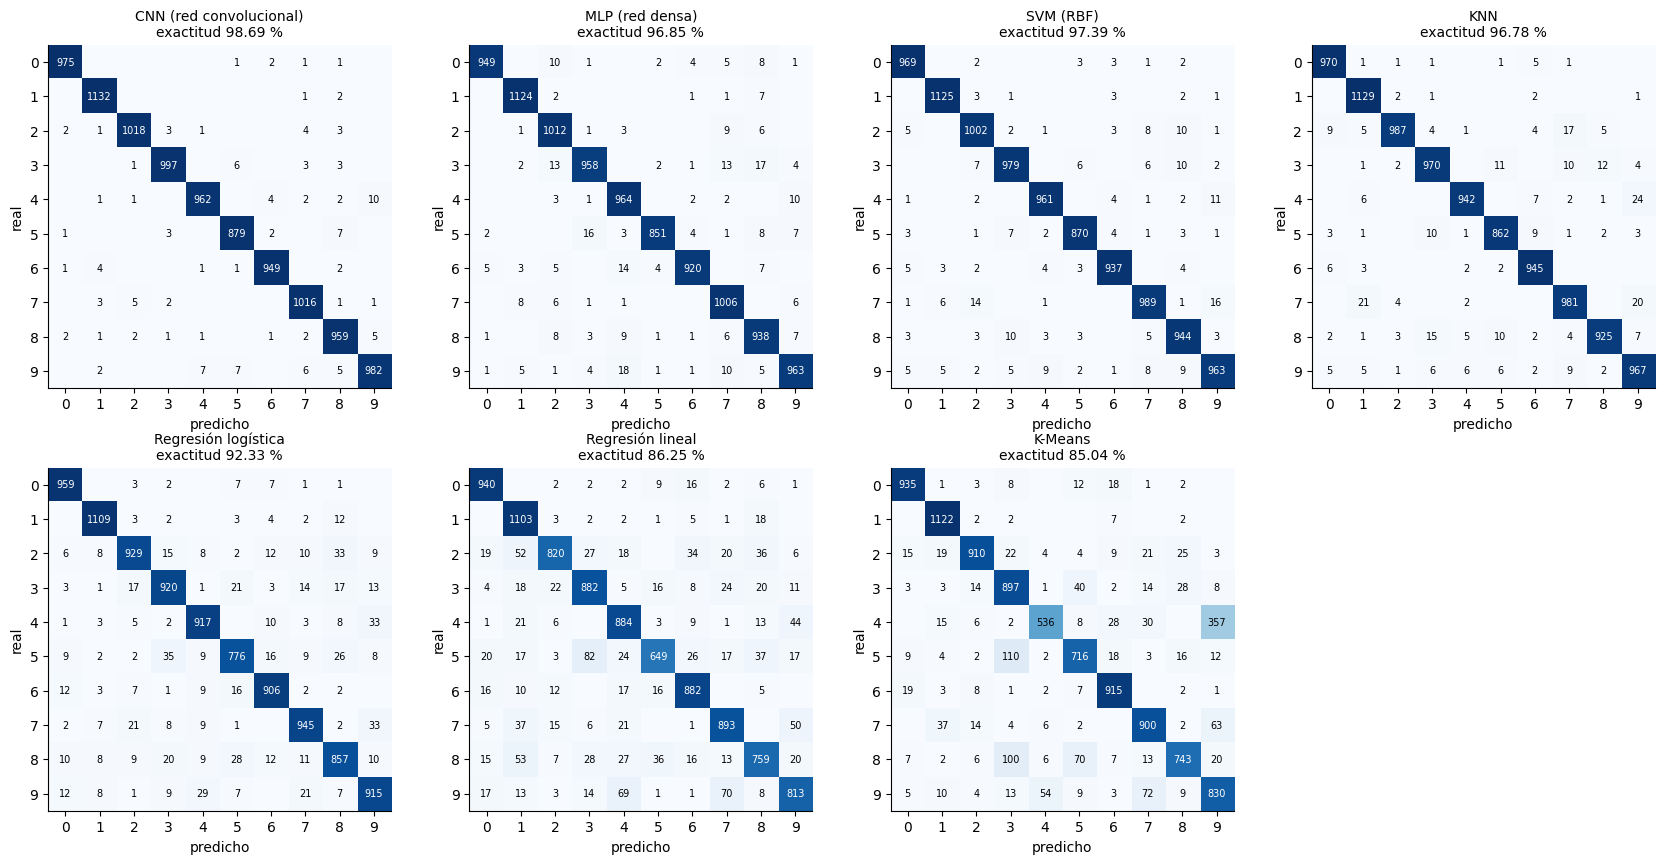

,Modelo,Confusiones más frecuentes (real → predicho: veces)
0,CNN,4 → 9: 10; 9 → 5: 7; 9 → 4: 7
1,MLP,9 → 4: 18; 3 → 8: 17; 5 → 3: 16
2,SVM,7 → 9: 16; 7 → 2: 14; 4 → 9: 11
3,KNN,4 → 9: 24; 7 → 1: 21; 7 → 9: 20
4,Reg. logística,5 → 3: 35; 4 → 9: 33; 7 → 9: 33
5,Reg. lineal,5 → 3: 82; 9 → 7: 70; 9 → 4: 69
6,K-Means,4 → 9: 357; 5 → 3: 110; 8 → 3: 100


In [14]:
figura, ejes = plt.subplots(2, 4, figsize=(17, 8.6))
for eje, clave in zip(ejes.flat, CLAVES):
    m = METRICAS[clave]["matriz"]
    porcentaje = m / m.sum(axis=1, keepdims=True) * 100
    eje.imshow(porcentaje, cmap="Blues", vmin=0, vmax=100)
    for i in range(10):
        for j in range(10):
            if m[i, j]:
                eje.text(j, i, m[i, j], ha="center", va="center", fontsize=7, color="white" if porcentaje[i, j] > 55 else "black")
    eje.set_xticks(range(10)); eje.set_yticks(range(10)); eje.set_xlabel("predicho"); eje.set_ylabel("real")
    eje.set_title(f"{NOMBRES[clave]}\nexactitud {METRICAS[clave]['exactitud'] * 100:.2f} %", fontsize=10)
ejes.flat[-1].axis("off")
figura.tight_layout()
guardar_figura(figura, "matrices_confusion")

filas = []
for clave in CLAVES:
    m = METRICAS[clave]["matriz"].copy(); np.fill_diagonal(m, 0)
    top = np.dstack(np.unravel_index(np.argsort(m.ravel())[::-1][:3], m.shape))[0]
    filas.append({"Modelo": CORTOS[clave], "Confusiones más frecuentes (real → predicho: veces)":
                  ";  ".join(f"{a} → {b}: {m[a, b]}" for a, b in top)})
display(pd.DataFrame(filas))

## Paso 15 · Comparación e interpretación de los resultados

**Qué hace:** compara los siete modelos en exactitud, F1, tiempo de entrenamiento y velocidad, y explica qué significan los números.

**Cómo funciona:** los gráficos salen de la tabla del paso 13; el texto de interpretación se escribe con los valores obtenidos en esta
ejecución (no son números fijos).

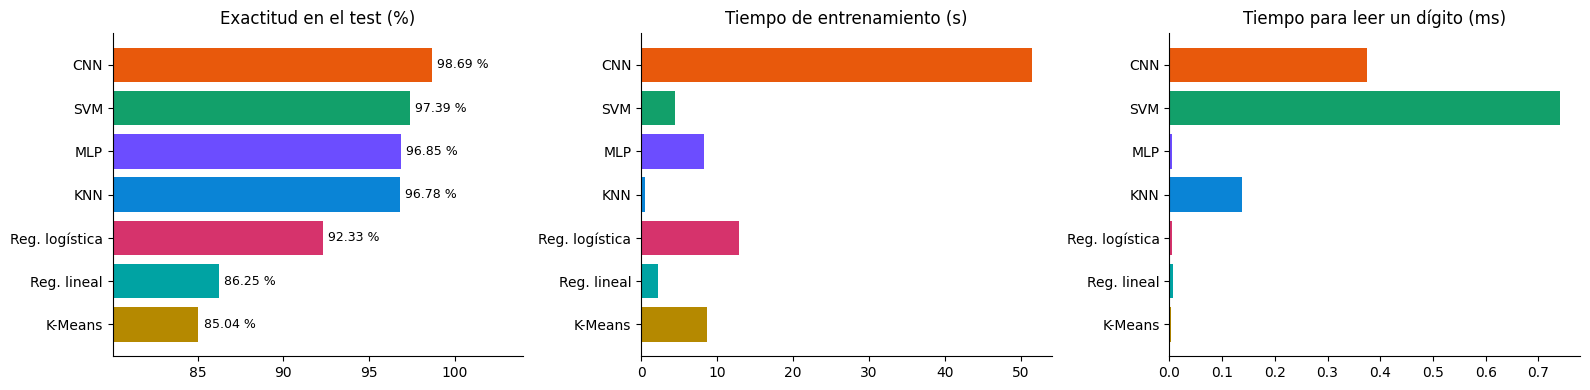

### Interpretación
- El mejor modelo es la CNN (red convolucional) con 98,69 % de exactitud y F1 macro de 98,68 %: de 10 000 dígitos que nunca vio se equivocó en 131. Le sigue SVM (RBF) con 97,39 % (261 errores).
- La CNN supera a la MLP (98,69 % frente a 96,85 % y con menos parámetros): las capas convolucionales reconocen trazos y curvas aunque el dígito esté corrido, mientras que la MLP ve cada píxel por separado.
- SVM (97,39 %) y KNN (96,78 %), las alternativas pedidas, quedan cerca de las redes gracias a las 50 componentes PCA. Para leer un dígito tardan 0,742 ms (SVM) y 0,139 ms (KNN), frente a 0,375 ms de la CNN; la SVM compara cada dígito con sus vectores de soporte y KNN con todos los ejemplos que guardó, así que se vuelven más lentos cuantos más datos tienen.
- Los modelos lineales tienen un techo: regresión logística 92,33 % y regresión lineal 86,25 %. Un único peso por píxel no puede representar las distintas formas de escribir un mismo dígito.
- K-Means (85,04 %) no usa las etiquetas para aprender: agrupa dígitos parecidos y solo después cada grupo toma un nombre. Que llegue a ese valor muestra que los dígitos forman grupos naturales, pero confunde los que se escriben parecido.
- La confusión más frecuente de la CNN es 4 → 9 (10 veces) y su dígito más difícil es el 9 (F1 97,86 %): son pares que también confunden las personas cuando la letra es descuidada.
- En la validación cruzada la CNN tuvo una desviación de ±0,65 puntos entre pliegues: el resultado es estable y no depende de qué datos tocaron en cada parte.
- Decisión: para TecnoForms se recomienda la CNN como modelo principal (la más exacta) y SVM como respaldo para comparar.

In [15]:
orden = sorted(CLAVES, key=lambda c: METRICAS[c]["exactitud"])
figura, ejes = plt.subplots(1, 3, figsize=(16, 4))
ejes[0].barh([CORTOS[c] for c in orden], [METRICAS[c]["exactitud"] * 100 for c in orden], color=[COLORES[c] for c in orden])
for i, c in enumerate(orden):
    ejes[0].text(METRICAS[c]["exactitud"] * 100 + 0.3, i, f"{METRICAS[c]['exactitud'] * 100:.2f} %", va="center", fontsize=9)
ejes[0].set_xlim(min(METRICAS[c]["exactitud"] for c in CLAVES) * 100 - 5, 104); ejes[0].set_title("Exactitud en el test (%)")
ejes[1].barh([CORTOS[c] for c in orden], [TIEMPOS_ENTRENO[c] for c in orden], color=[COLORES[c] for c in orden])
ejes[1].set_title("Tiempo de entrenamiento (s)")
ejes[2].barh([CORTOS[c] for c in orden], [METRICAS[c]["ms"] for c in orden], color=[COLORES[c] for c in orden])
ejes[2].set_title("Tiempo para leer un dígito (ms)")
figura.tight_layout()
guardar_figura(figura, "comparacion_modelos")

ex = {c: METRICAS[c]["exactitud"] * 100 for c in CLAVES}
err = {c: int((PREDICCIONES[c] != y_pru).sum()) for c in CLAVES}
ranking = sorted(CLAVES, key=lambda c: -ex[c])
segundo = ranking[1]
m = METRICAS[MEJOR]["matriz"].copy(); np.fill_diagonal(m, 0)
a, b = np.unravel_index(m.argmax(), m.shape)
peor_digito = int(METRICAS[MEJOR]["por_clase"]["F1"].idxmin())
INTERPRETACION = [
    f"El mejor modelo es la {NOMBRES[MEJOR]} con {ex[MEJOR]:.2f} % de exactitud y F1 macro de {METRICAS[MEJOR]['f1'] * 100:.2f} %: "
    f"de 10 000 dígitos que nunca vio se equivocó en {err[MEJOR]}. Le sigue {NOMBRES[segundo]} con {ex[segundo]:.2f} % ({err[segundo]} errores).",
    (f"La CNN supera a la MLP ({ex['cnn']:.2f} % frente a {ex['mlp']:.2f} %"
     + (" y con menos parámetros" if MODELOS["cnn"].total_parametros() < MODELOS["mlp"].total_parametros() else "")
     + "): las capas convolucionales reconocen trazos y curvas aunque el dígito esté corrido, mientras que la MLP ve cada píxel por separado."
     if ex["cnn"] >= ex["mlp"] else
     f"La MLP ({ex['mlp']:.2f} %) quedó por encima de la CNN ({ex['cnn']:.2f} %) en esta ejecución; la CNN suele ganar cuando entrena más épocas, "
     "porque sus capas convolucionales reconocen trazos y curvas aunque el dígito esté corrido."),
    f"SVM ({ex['svm']:.2f} %) y KNN ({ex['knn']:.2f} %), las alternativas pedidas, quedan cerca de las redes gracias a las 50 componentes PCA. "
    f"Para leer un dígito tardan {METRICAS['svm']['ms']:.3f} ms (SVM) y {METRICAS['knn']['ms']:.3f} ms (KNN), frente a {METRICAS['cnn']['ms']:.3f} ms de la CNN; "
    "la SVM compara cada dígito con sus vectores de soporte y KNN con todos los ejemplos que guardó, así que se vuelven más lentos cuantos más datos tienen.",
    f"Los modelos lineales tienen un techo: regresión logística {ex['regresion']:.2f} % y regresión lineal {ex['regresion_lineal']:.2f} %. "
    "Un único peso por píxel no puede representar las distintas formas de escribir un mismo dígito.",
    f"K-Means ({ex['kmeans']:.2f} %) no usa las etiquetas para aprender: agrupa dígitos parecidos y solo después cada grupo toma un nombre. "
    "Que llegue a ese valor muestra que los dígitos forman grupos naturales, pero confunde los que se escriben parecido.",
    f"La confusión más frecuente de la {CORTOS[MEJOR]} es {a} → {b} ({m[a, b]} veces) y su dígito más difícil es el {peor_digito} "
    f"(F1 {METRICAS[MEJOR]['por_clase']['F1'][peor_digito] * 100:.2f} %): son pares que también confunden las personas cuando la letra es descuidada.",
    f"En la validación cruzada la {CORTOS[MEJOR]} tuvo una desviación de ±{VALIDACION[MEJOR][0]['desviacion'] * 100:.2f} puntos entre pliegues: "
    "el resultado es estable y no depende de qué datos tocaron en cada parte.",
    f"Decisión: para TecnoForms se recomienda la {CORTOS[MEJOR]} como modelo principal (la más exacta"
    + (" y de las más rápidas al leer" if METRICAS[MEJOR]["ms"] <= sorted(METRICAS[c]["ms"] for c in CLAVES)[2] else "")
    + f") y {CORTOS[segundo]} como respaldo para comparar.",
]
INTERPRETACION = [es(t) for t in INTERPRETACION]
display(Markdown("### Interpretación\n" + "\n".join(f"- {t}" for t in INTERPRETACION)))

## Paso 16 · Resultados visuales: predicción frente a la etiqueta real (datos de internet)

**Qué hace:** muestra dígitos del test con su **etiqueta real** y lo que **predijo** cada modelo, en verde si acertó y en rosa si se
equivocó (como la galería de la aplicación).

**Cómo funciona:** por cada modelo se elige un acierto de cada dígito (0 a 9) y dos de sus errores, con semilla fija. Abajo, una
galería más grande solo con errores de la CNN y la probabilidad que les dio: ayuda a ver que muchos errores son dígitos ambiguos.

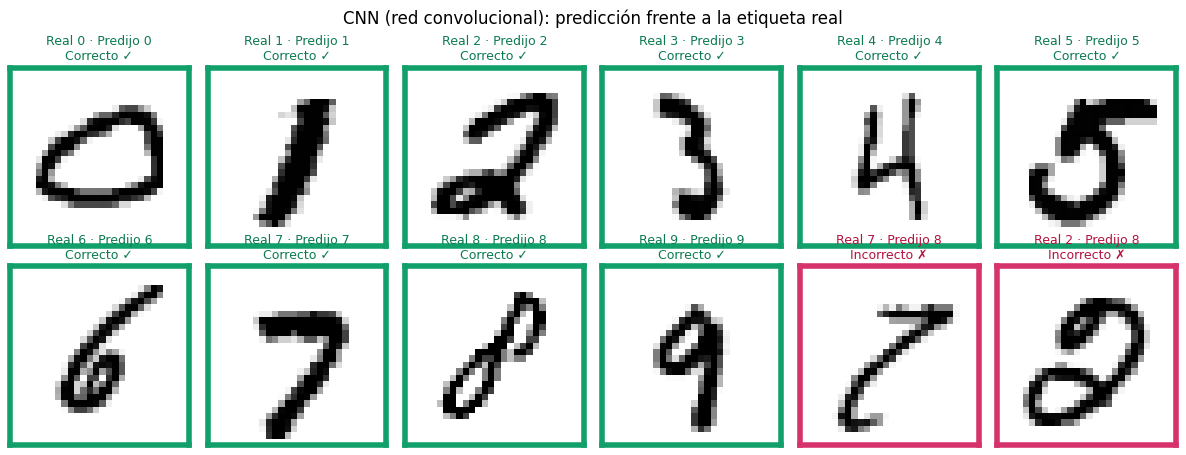

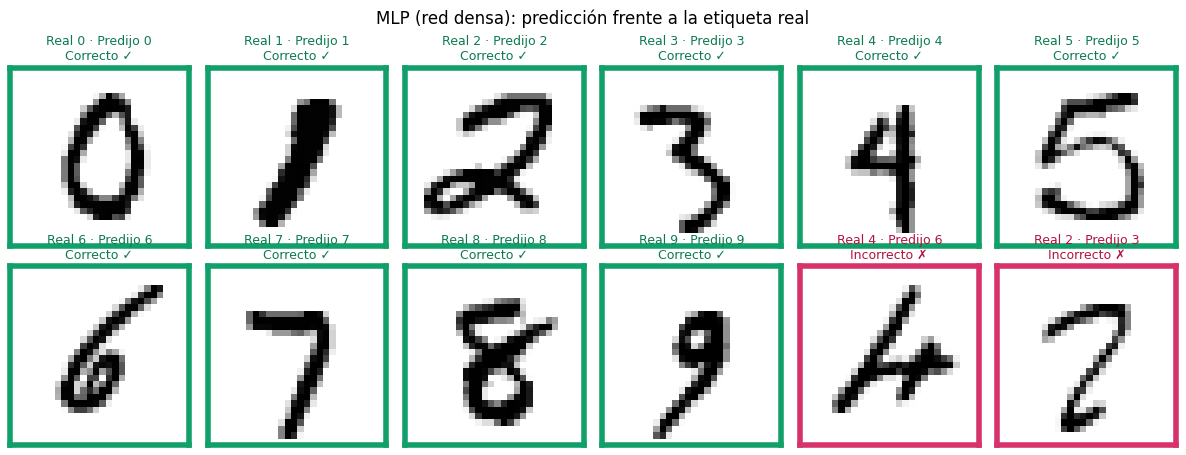

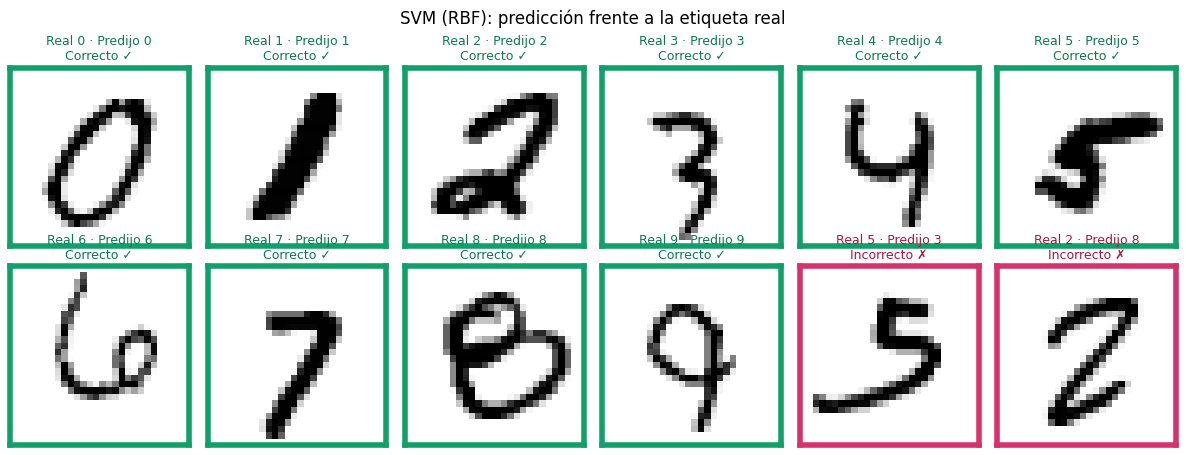

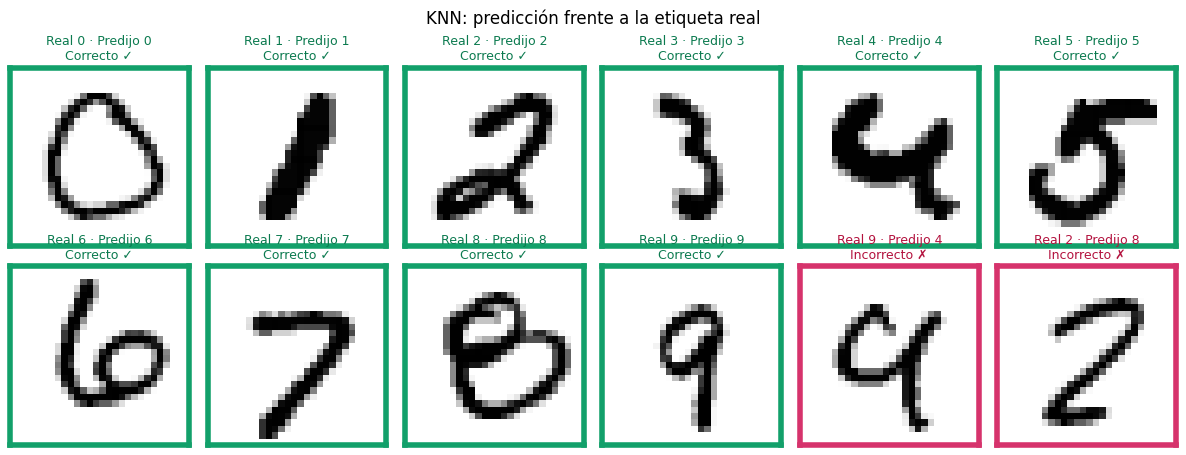

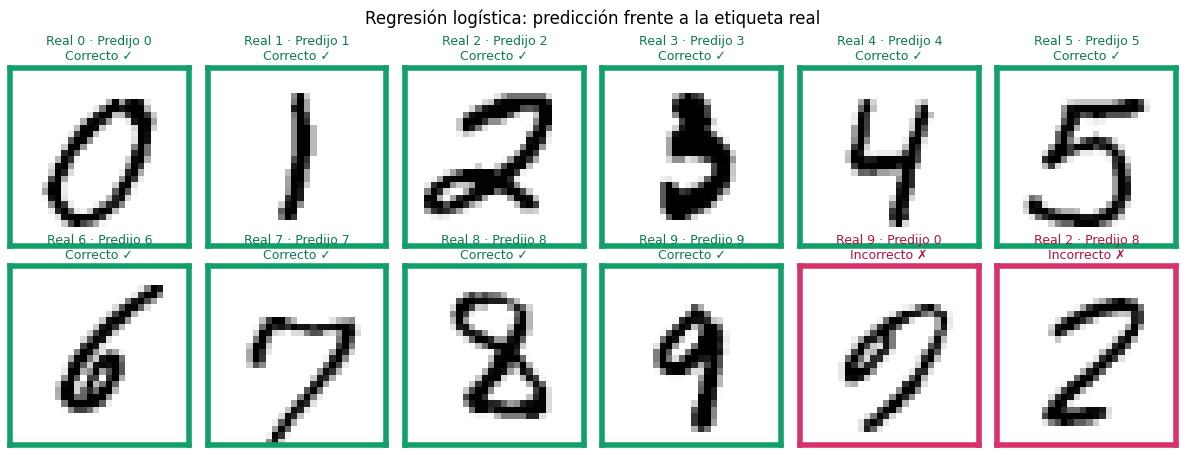

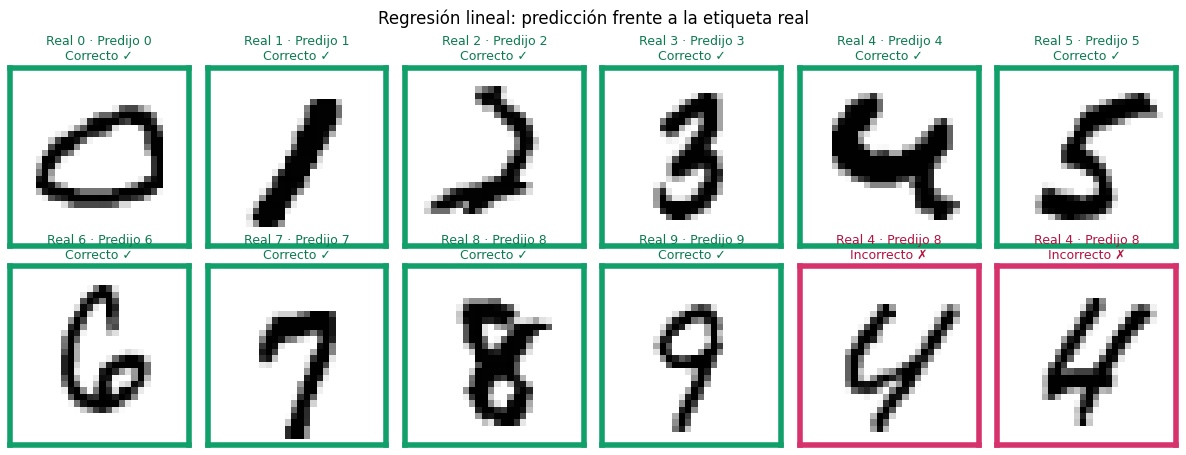

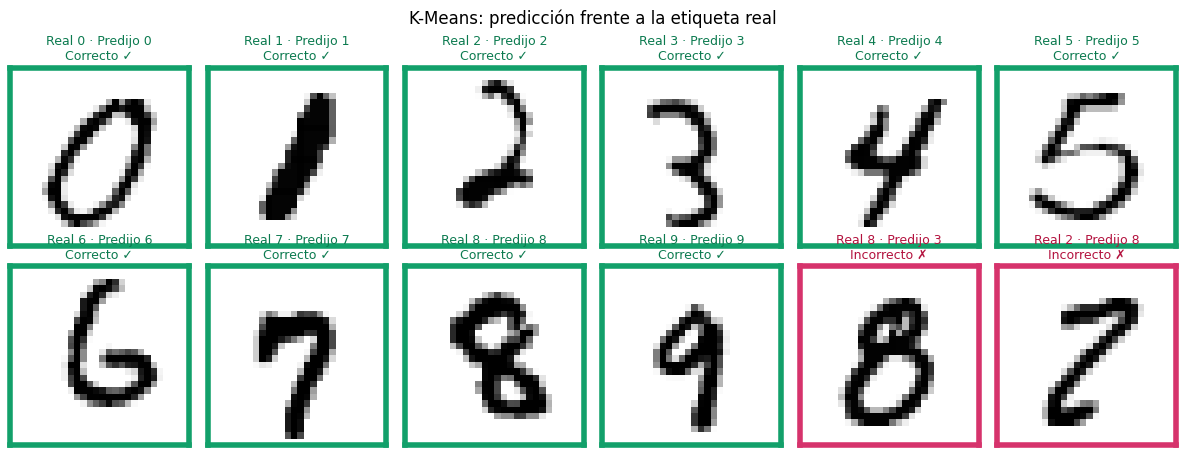

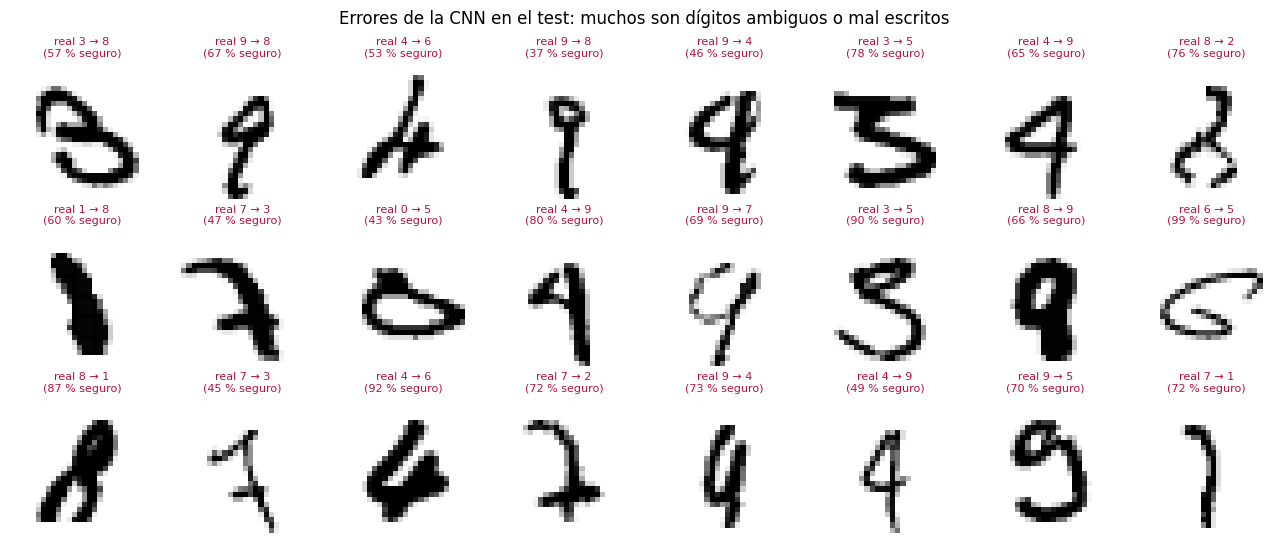

In [16]:
def galeria(clave, nombre):
    azar = np.random.default_rng(SEMILLA)
    predicho = PREDICCIONES[clave]
    elegidos = [int(azar.choice(np.flatnonzero((y_pru == d) & (predicho == d)))) for d in range(10)]
    errores = np.flatnonzero(predicho != y_pru)
    elegidos += [int(i) for i in azar.choice(errores, size=min(2, len(errores)), replace=False)]
    figura, ejes = plt.subplots(2, 6, figsize=(12, 4.6))
    for eje, i in zip(ejes.flat, elegidos):
        bien = predicho[i] == y_pru[i]
        eje.imshow(x_pru[i].reshape(28, 28), cmap="gray_r")
        eje.set_xticks([]); eje.set_yticks([])
        for borde in eje.spines.values():
            borde.set_visible(True); borde.set_color("#12a06a" if bien else "#d6336c"); borde.set_linewidth(4)
        eje.set_title(f"Real {y_pru[i]} · Predijo {predicho[i]}\n{'Correcto ✓' if bien else 'Incorrecto ✗'}", fontsize=9,
                      color="#0b7a4f" if bien else "#b3123e")
    figura.suptitle(f"{NOMBRES[clave]}: predicción frente a la etiqueta real", fontsize=12)
    figura.tight_layout()
    guardar_figura(figura, nombre)


for clave in CLAVES:
    galeria(clave, f"predicciones_{clave}")

probabilidades = MODELOS["cnn"].probabilidades(x_pru)
errores = np.flatnonzero(PREDICCIONES["cnn"] != y_pru)[:24]
figura, ejes = plt.subplots(3, 8, figsize=(13, 5.6))
for eje, i in zip(ejes.flat, errores):
    eje.imshow(x_pru[i].reshape(28, 28), cmap="gray_r"); eje.axis("off")
    eje.set_title(f"real {y_pru[i]} → {PREDICCIONES['cnn'][i]}\n({probabilidades[i].max() * 100:.0f} % seguro)", fontsize=8, color="#b3123e")
for eje in list(ejes.flat)[len(errores):]:
    eje.axis("off")
figura.suptitle("Errores de la CNN en el test: muchos son dígitos ambiguos o mal escritos", fontsize=12)
figura.tight_layout()
guardar_figura(figura, "errores_cnn")

## Paso 17 · Todo el sistema con datos ficticios: de la foto al número

**Qué hace:** prueba el proceso completo de TecnoForms con imágenes que los modelos nunca vieron: **preprocesado + segmentación +
clasificación** en 60 números (hoja lisa y cuadriculada) y en 6 formularios completos.

**Cómo funciona:** cada imagen pasa por `procesar_foto` (paso 5) diciéndole cuántas cifras tiene el número; los recortes de 28 × 28
los leen los siete modelos. Se mide la exactitud **por dígito** y el **número exacto** (todas las cifras bien). El número exacto es
más difícil: un número de 9 cifras falla si falla una sola.

**84 números ficticios (344 dígitos):**

,Dígitos bien (%),Número exacto (%)
modelo,,
CNN,99.1,96.4
SVM,98.0,91.7
KNN,98.0,91.7
MLP,96.2,85.7
Reg. logística,92.4,70.2
K-Means,86.3,56.0
Reg. lineal,86.0,54.8


Número exacto (%) por tipo de imagen,Formulario,Hoja cuadriculada,Hoja lisa
modelo,,,
CNN,91.7,100.0,96.7
SVM,87.5,100.0,86.7
KNN,87.5,96.7,90.0
MLP,75.0,93.3,86.7
Reg. logística,62.5,80.0,66.7
K-Means,41.7,63.3,60.0
Reg. lineal,37.5,70.0,53.3


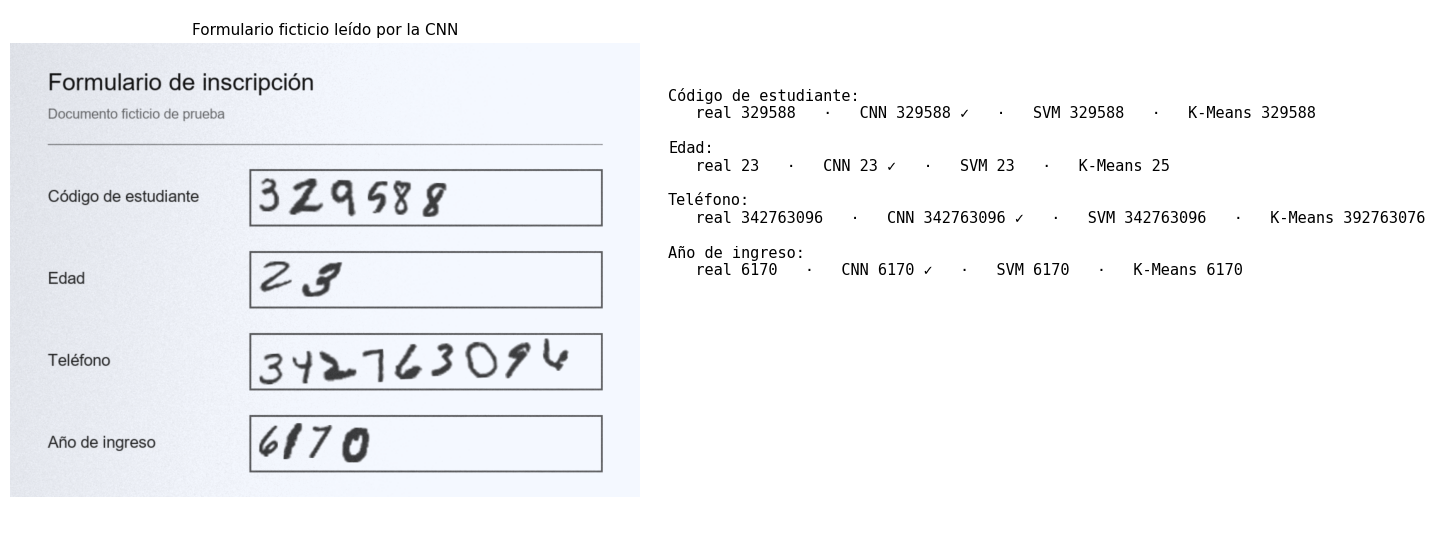

In [17]:
gen_prueba = GeneradorDigitos(x_ent, y_ent, semilla=2026)
imagenes_prueba = []
for _ in range(30):
    n = gen_prueba.numero_aleatorio(int(gen_prueba.azar.integers(2, 7)))
    imagenes_prueba.append(("Hoja lisa", gen_prueba.foto_numero(n, float(gen_prueba.azar.uniform(0.2, 0.8))), n))
for _ in range(30):
    n = gen_prueba.numero_aleatorio(int(gen_prueba.azar.integers(2, 6)))
    imagenes_prueba.append(("Hoja cuadriculada", gen_prueba.foto_cuadriculada(n, float(gen_prueba.azar.uniform(0.2, 0.8))), n))
formularios_prueba = [gen_prueba.formulario(list(TIPOS_FORMULARIO)[i % 3], float(gen_prueba.azar.uniform(0.25, 0.6))) for i in range(6)]
for hoja, campos in formularios_prueba:
    imagenes_prueba += [("Formulario", recortar_campo(hoja, c["caja"]), c["valor"]) for c in campos]


def leer_numero(imagen, esperado):
    r = procesar_foto(imagen, len(esperado))
    if not len(r["digitos"]):
        return {c: "" for c in CLAVES}, r
    return {c: "".join(str(d) for d in MODELOS[c].predecir(r["digitos"])) for c in CLAVES}, r


filas = []
for tipo, imagen, numero in imagenes_prueba:
    lecturas, _ = leer_numero(imagen, numero)
    for c in CLAVES:
        leido = lecturas[c]
        completo = len(leido) == len(numero)
        filas.append({"tipo": tipo, "modelo": CORTOS[c], "exacto": leido == numero,
                      "digitos_ok": sum(x == y for x, y in zip(leido, numero)) if completo else 0, "digitos": len(numero)})
ficticios = pd.DataFrame(filas)
por_modelo = ficticios.groupby("modelo").agg(digitos_ok=("digitos_ok", "sum"), digitos=("digitos", "sum"), exacto=("exacto", "mean"))
por_modelo["Dígitos bien (%)"] = por_modelo["digitos_ok"] / por_modelo["digitos"] * 100
por_modelo["Número exacto (%)"] = por_modelo["exacto"] * 100
por_modelo = por_modelo.loc[[CORTOS[c] for c in CLAVES], ["Dígitos bien (%)", "Número exacto (%)"]].sort_values("Dígitos bien (%)", ascending=False)
display(Markdown(f"**{len(imagenes_prueba)} números ficticios ({ficticios['digitos'].sum() // len(CLAVES)} dígitos):**"))
display(por_modelo.round(1))
display((ficticios.pivot_table(index="modelo", columns="tipo", values="exacto", aggfunc="mean") * 100)
        .loc[por_modelo.index].round(1).rename_axis(columns="Número exacto (%) por tipo de imagen"))

hoja, campos = formularios_prueba[0]
figura = plt.figure(figsize=(14, 5.2))
eje = figura.add_axes([0, 0, 0.45, 1]); eje.imshow(cv2.cvtColor(hoja, cv2.COLOR_BGR2RGB)); eje.axis("off")
eje.set_title("Formulario ficticio leído por la CNN", fontsize=11)
texto = []
for c in campos:
    lecturas, r = leer_numero(recortar_campo(hoja, c["caja"]), c["valor"])
    marca = "✓" if lecturas["cnn"] == c["valor"] else "✗"
    texto.append(f"{c['etiqueta']}:\n   real {c['valor']}   ·   CNN {lecturas['cnn']} {marca}   ·   SVM {lecturas['svm']}   ·   K-Means {lecturas['kmeans']}")
eje = figura.add_axes([0.47, 0, 0.53, 1]); eje.axis("off")
eje.text(0, 0.85, "\n\n".join(texto), va="top", fontsize=11, family="monospace")
guardar_figura(figura, "formulario_leido")

## Paso 18 · Prueba con tus propias fotos (opcional)

**Qué hace:** te deja subir **una o varias fotos** de números o formularios escritos a mano (cualquier color de tinta, hoja lisa,
cuadriculada o rayada) y muestra qué lee cada uno de los siete modelos.

**Cómo funciona:**
1. Al ejecutar esta celda en Colab aparece el botón *Elegir archivos*: elige tus fotos (puedes elegir varias a la vez).
2. Cada foto pasa por el mismo preprocesado del paso 5: si la tinta y la cuadrícula son de colores distintos (por ejemplo tinta roja en
   cuadrícula azul) se usa el canal de color donde la cuadrícula casi desaparece, y luego se borran las líneas finas de la hoja.
3. Los modelos leen los dígitos **sin que tengas que decir el número**.
4. Si no subes nada (o ejecutas fuera de Colab), se usan como ejemplo tres fotos ficticias con tintas y hojas diferentes.

No subiste fotos: se usan 3 ejemplos ficticios con tintas y hojas diferentes.


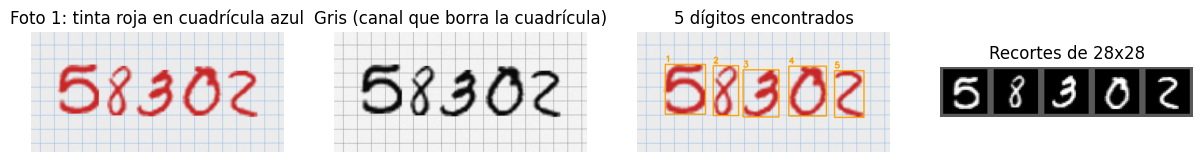

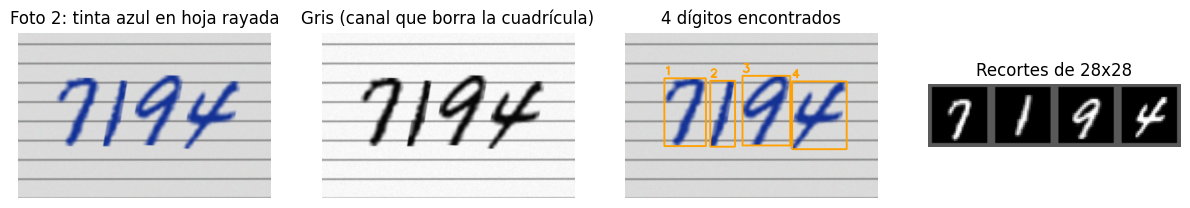

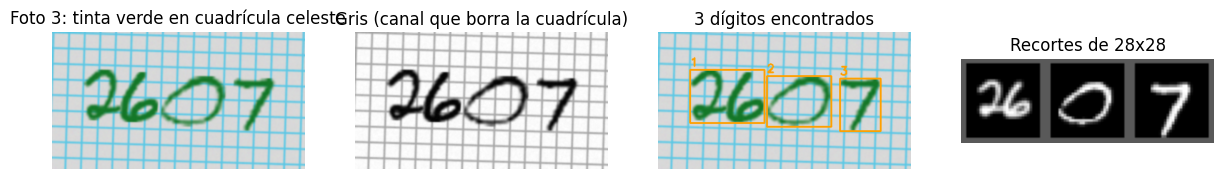

,Foto,CNN,MLP,SVM,KNN,Reg. logística,Reg. lineal,K-Means
0,1. tinta roja en cuadrícula azul,58302,58302,58302,58302,58308,58308,58302
1,2. tinta azul en hoja rayada,7194,7194,7194,7194,7194,7194,7194
2,3. tinta verde en cuadrícula celeste,207,207,207,207,407,407,207


In [18]:
MIS_FOTOS = []   # (nombre, imagen)
if EN_COLAB:
    from google.colab import files
    try:
        subida = files.upload()
        for nombre, datos in subida.items():
            imagen = cv2.imdecode(np.frombuffer(datos, np.uint8), cv2.IMREAD_COLOR)
            if imagen is not None:
                MIS_FOTOS.append((nombre, imagen))
    except Exception as error:
        print("No se subió ninguna foto:", error)
if not MIS_FOTOS:
    ejemplo = GeneradorDigitos(x_ent, y_ent, semilla=99)
    MIS_FOTOS = [("tinta roja en cuadrícula azul", ejemplo.foto_cuadriculada("58302", 0.5, color_linea=(230, 180, 130), color_tinta=(40, 40, 200), rayada=False)),
                 ("tinta azul en hoja rayada", ejemplo.foto_cuadriculada("7194", 0.5, color_linea=(140, 140, 140), color_tinta=(150, 50, 20), rayada=True)),
                 ("tinta verde en cuadrícula celeste", ejemplo.foto_cuadriculada("2607", 0.5, color_linea=(230, 200, 90), color_tinta=(40, 120, 20), rayada=False))]
    print("No subiste fotos: se usan 3 ejemplos ficticios con tintas y hojas diferentes.")


def mostrar_lectura(fotos, esperados=None):
    filas = []
    for i, (nombre, imagen) in enumerate(fotos):
        esperado = (esperados or [""] * len(fotos))[i]
        r = procesar_foto(imagen, len(esperado) if esperado else None)
        figura, ejes = plt.subplots(1, 4, figsize=(15, 3.2))
        ejes[0].imshow(cv2.cvtColor(r["pasos"]["original"], cv2.COLOR_BGR2RGB)); ejes[0].set_title(f"Foto {i + 1}: {nombre}"[:45])
        ejes[1].imshow(r["pasos"]["gris"], cmap="gray"); ejes[1].set_title("Gris (canal que borra la cuadrícula)")
        ejes[2].imshow(cv2.cvtColor(r["pasos"]["segmentacion"], cv2.COLOR_BGR2RGB)); ejes[2].set_title(f"{len(r['cajas'])} dígitos encontrados")
        if r["recortes"]:
            ejes[3].imshow(np.hstack([np.pad(x, 2, constant_values=90) for x in r["recortes"]]), cmap="gray")
        ejes[3].set_title("Recortes de 28x28")
        for e in ejes:
            e.axis("off")
        plt.show()
        fila = {"Foto": f"{i + 1}. {nombre}"[:40]}
        if esperado:
            fila["Número real"] = esperado
        for c in CLAVES:
            leido = "".join(str(d) for d in MODELOS[c].predecir(r["digitos"])) if len(r["digitos"]) else "—"
            fila[CORTOS[c]] = leido + ((" ✓" if leido == esperado else " ✗") if esperado else "")
        filas.append(fila)
    display(pd.DataFrame(filas))


VERDE, ROSA = "#12a06a", "#d6336c"


def mapa_sobre(vector, mapa, eje, titulo):
    mapa = np.asarray(mapa, np.float32)
    mapa = (mapa - mapa.min()) / (mapa.max() - mapa.min() + 1e-8)
    eje.imshow(vector.reshape(28, 28), cmap="gray")
    eje.imshow(cv2.resize(mapa, (28, 28), interpolation=cv2.INTER_CUBIC), cmap="jet", alpha=0.5)
    eje.set_title(titulo, fontsize=8); eje.axis("off")


def explicar(clave, vector, ejes):
    # Cómo llegó cada modelo a su respuesta (mismas ideas que la sección «Predecir» de la aplicación)
    modelo = MODELOS[clave]
    X = vector.reshape(1, 784).astype(np.float32)
    probs = modelo.probabilidades(X)[0]
    p = int(probs.argmax())
    for e in ejes:
        e.axis("off")
    if clave == "cnn":
        red = modelo.red.eval()
        entrada = modelo.preparar(torch.from_numpy(X)).to(DISPOSITIVO)
        intermedia = red[:5](entrada); intermedia.retain_grad()
        red[5:](intermedia)[0, p].backward()
        pesos = intermedia.grad.mean(dim=(2, 3), keepdim=True)
        cam = np.maximum((pesos * intermedia).sum(1)[0].detach().cpu().numpy(), 0)
        red.zero_grad()
        with torch.no_grad():
            filtros = red[:2](entrada)[0].cpu().numpy()
        mapa_sobre(vector, cam, ejes[0], f"Dónde miró (rojo = {p})")
        for k, e in enumerate(ejes[1:4]):
            e.imshow(filtros[k], cmap="magma"); e.set_title(f"Filtro {k + 1} de la 1.ª capa", fontsize=8)
        return (f"La CNN pasó el dígito por {len(filtros)} filtros que detectan bordes y trazos, los combinó en la segunda capa y calculó "
                f"qué zonas empujaron hacia el {p}. Respondió {p} con {probs[p]:.0%} de seguridad.")
    if clave == "mlp":
        red = modelo.red.eval()
        entrada = modelo.preparar(torch.from_numpy(X)).to(DISPOSITIVO).requires_grad_(True)
        red(entrada)[0, p].backward()
        sensibilidad = entrada.grad.abs()[0].cpu().numpy().reshape(28, 28)
        red.zero_grad()
        with torch.no_grad():
            oculta = torch.relu(red[0](modelo.preparar(torch.from_numpy(X)).to(DISPOSITIVO)))[0].cpu().numpy()
        mapa_sobre(vector, sensibilidad, ejes[0], "Píxeles que más pesaron")
        ejes[1].imshow(oculta.reshape(-1, 16), cmap="magma"); ejes[1].set_title(f"{int((oculta > 0).sum())} de {len(oculta)} neuronas activas", fontsize=8)
        return (f"La red densa mezcló los 784 píxeles en {len(oculta)} neuronas; se encendieron {int((oculta > 0).sum())}. "
                f"Al combinarlas concluyó que es un {p} ({probs[p]:.0%}).")
    if clave in ("regresion", "regresion_lineal"):
        pesos = (modelo.modelo.coef_[p] if clave == "regresion" else modelo.pesos[:784, p]).reshape(28, 28)
        mapa_sobre(vector, np.clip(pesos * vector.reshape(28, 28), 0, None), ejes[0], f"Aporte de cada píxel al {p}")
        ejes[1].imshow(pesos, cmap="RdBu_r"); ejes[1].set_title(f"Pesos aprendidos del {p}", fontsize=8)
        if clave == "regresion":
            return (f"La regresión logística tiene un peso por píxel para cada dígito y suma los píxeles encendidos por su peso. "
                    f"La suma del {p} fue la mayor ({probs[p]:.0%}).")
        puntaje = float((ModeloRegresionLineal.con_sesgo(X) @ modelo.pesos)[0, p])
        return (f"La regresión lineal calcula un puntaje por dígito (píxeles por pesos, ajustados por mínimos cuadrados) y gana el mayor. "
                f"El {p} sacó {puntaje:.2f} (1 sería un ajuste perfecto).")
    Z = modelo.proyectar(X)
    if clave == "svm":
        vectores = modelo.modelo.support_vectors_
        etiquetas = np.repeat(modelo.modelo.classes_, modelo.modelo.n_support_)
        distancias = np.linalg.norm(vectores - Z, axis=1)
        for e, i in zip(ejes, np.argsort(distancias)[:4]):
            e.imshow(np.clip(modelo.pca.inverse_transform(vectores[i: i + 1])[0], 0, 1).reshape(28, 28), cmap="gray")
            e.set_title(f"Vector de soporte: {etiquetas[i]}\ndistancia {distancias[i]:.2f}", fontsize=8)
        return (f"La SVM guarda {len(vectores)} ejemplos clave (vectores de soporte) que marcan las fronteras entre dígitos. "
                f"Comparó este dígito con ellos y el {p} sacó el puntaje más alto ({probs[p]:.0%}).")
    if clave == "knn":
        distancias, indices = modelo.modelo.kneighbors(Z)
        etiquetas = modelo.modelo.classes_[modelo.modelo._y[indices[0]]]
        for e, d, i, et in zip(ejes, distancias[0], indices[0], etiquetas):
            e.imshow(np.clip(modelo.pca.inverse_transform(modelo.modelo._fit_X[i: i + 1])[0], 0, 1).reshape(28, 28), cmap="gray")
            e.set_title(f"Vecino: {et}\ndistancia {d:.2f}", fontsize=8)
        return (f"KNN buscó los {len(etiquetas)} dígitos más parecidos que tiene guardados y votaron: {int((etiquetas == p).sum())} de "
                f"{len(etiquetas)} eran un {p}, así que respondió {p}.")
    distancias = modelo.modelo.transform(Z)[0]
    for e, i in zip(ejes, np.argsort(distancias)[:3]):
        e.imshow(np.clip(modelo.pca.inverse_transform(modelo.modelo.cluster_centers_[i: i + 1])[0], 0, 1).reshape(28, 28), cmap="gray")
        e.set_title(f"Grupo {i}: dígito {modelo.etiqueta_cluster[i]}\ndistancia {distancias[i]:.2f}", fontsize=8)
    return (f"K-Means agrupó los dígitos sin conocer las etiquetas y cada grupo tomó el dígito más común. "
            f"Este dígito cayó más cerca del grupo que representa al {p}.")


def comprobar_foto(nombre, imagen, esperado, digito_elegido=0):
    r = procesar_foto(imagen, len(esperado))
    if not len(r["digitos"]):
        print(f"{nombre}: no se encontraron dígitos.")
        return None
    lecturas = {c: MODELOS[c].predecir(r["digitos"]) for c in CLAVES}
    n = len(r["recortes"])
    display(Markdown(f"#### {nombre}: número real **{esperado}**"))
    # tarjetas Real / Predijo: una fila por modelo y una tarjeta por dígito
    figura, ejes = plt.subplots(len(CLAVES), n + 1, figsize=(1.6 * (n + 1) + 1.2, 1.75 * len(CLAVES)),
                                gridspec_kw={"width_ratios": [1.8] + [1] * n})
    for fila, c in enumerate(CLAVES):
        leido = "".join(str(d) for d in lecturas[c])
        bien_todo = leido == esperado
        ejes[fila, 0].axis("off")
        ejes[fila, 0].text(0, 0.5, f"{CORTOS[c]}\nleyó {leido}\n{'Correcto ✓' if bien_todo else 'Error ✗'}", va="center", fontsize=10,
                           fontweight="bold", color=VERDE if bien_todo else ROSA)
        for k in range(n):
            eje = ejes[fila, k + 1]
            real = esperado[k] if k < len(esperado) else "?"
            bien = str(lecturas[c][k]) == real
            eje.imshow(r["recortes"][k], cmap="gray"); eje.set_xticks([]); eje.set_yticks([])
            for borde in eje.spines.values():
                borde.set_visible(True); borde.set_color(VERDE if bien else ROSA); borde.set_linewidth(3.5)
            eje.set_title(f"Real {real} · Predijo {lecturas[c][k]}\n{'Correcto ✓' if bien else 'Error ✗'}", fontsize=8,
                          color=VERDE if bien else ROSA)
    figura.tight_layout()
    plt.show()
    # cómo lo hizo cada modelo con un dígito
    fallados = [k for k in range(n) if any(str(lecturas[c][k]) != (esperado[k] if k < len(esperado) else "?") for c in CLAVES)]
    k = (digito_elegido - 1) if 1 <= digito_elegido <= n else (fallados[0] if fallados else 0)
    display(Markdown(f"**Cómo lo hizo cada modelo con el dígito {k + 1}** (real {esperado[k] if k < len(esperado) else '?'}):"))
    figura, ejes = plt.subplots(len(CLAVES), 6, figsize=(14, 2.0 * len(CLAVES)), gridspec_kw={"width_ratios": [1, 1, 1, 1, 0.2, 4.5]})
    for fila, c in enumerate(CLAVES):
        texto = explicar(c, r["digitos"][k], ejes[fila, :4])
        bien = str(lecturas[c][k]) == (esperado[k] if k < len(esperado) else "?")
        ejes[fila, 4].axis("off"); ejes[fila, 5].axis("off")
        ejes[fila, 5].text(0, 0.5, f"{NOMBRES[c]} · predijo {lecturas[c][k]} · {'Correcto ✓' if bien else 'Error ✗'}\n" + texto,
                           va="center", fontsize=8.5, wrap=True, color="#222222")
        ejes[fila, 5].title.set_text("")
    figura.tight_layout()
    plt.show()
    return r


mostrar_lectura(MIS_FOTOS)

### Paso 18 b · Escribe qué número dice cada foto (opcional, después de subirlas)

**Qué hace:** igual que en la aplicación, después de ver las fotos puedes escribir el número real de cada una para comprobar qué modelos
acertaron.

**Cómo funciona:**
1. Escribe los números en el cuadro `NUMEROS`, en el mismo orden de las fotos y separados por comas (por ejemplo `58302, 7194, 2607`);
   deja vacía la posición de una foto si no quieres ponerla. Si dejas el cuadro vacío, esta celda no hace nada.
2. Al saber cuántas cifras tiene, el preprocesado une o parte los recortes hasta tener esa cantidad.
3. Para cada foto sale una tabla de tarjetas como en la aplicación: una fila por modelo y una tarjeta por dígito con
   **Real / Predijo** y **Correcto ✓** (verde) o **Error ✗** (rosa), más el número completo que leyó cada modelo.
4. Debajo, **cómo lo hizo cada modelo** con un dígito (el primero en que alguno se equivocó): la CNN muestra dónde miró (mapa de calor),
   la MLP los píxeles que más pesaron, las regresiones el aporte de cada píxel, la SVM sus vectores de soporte más cercanos, KNN los
   vecinos que votaron y K-Means los grupos más cercanos. En `DIGITO_A_EXPLICAR` puedes elegir otro dígito (1 = el primero).

#### tinta roja en cuadrícula azul: número real **58302**

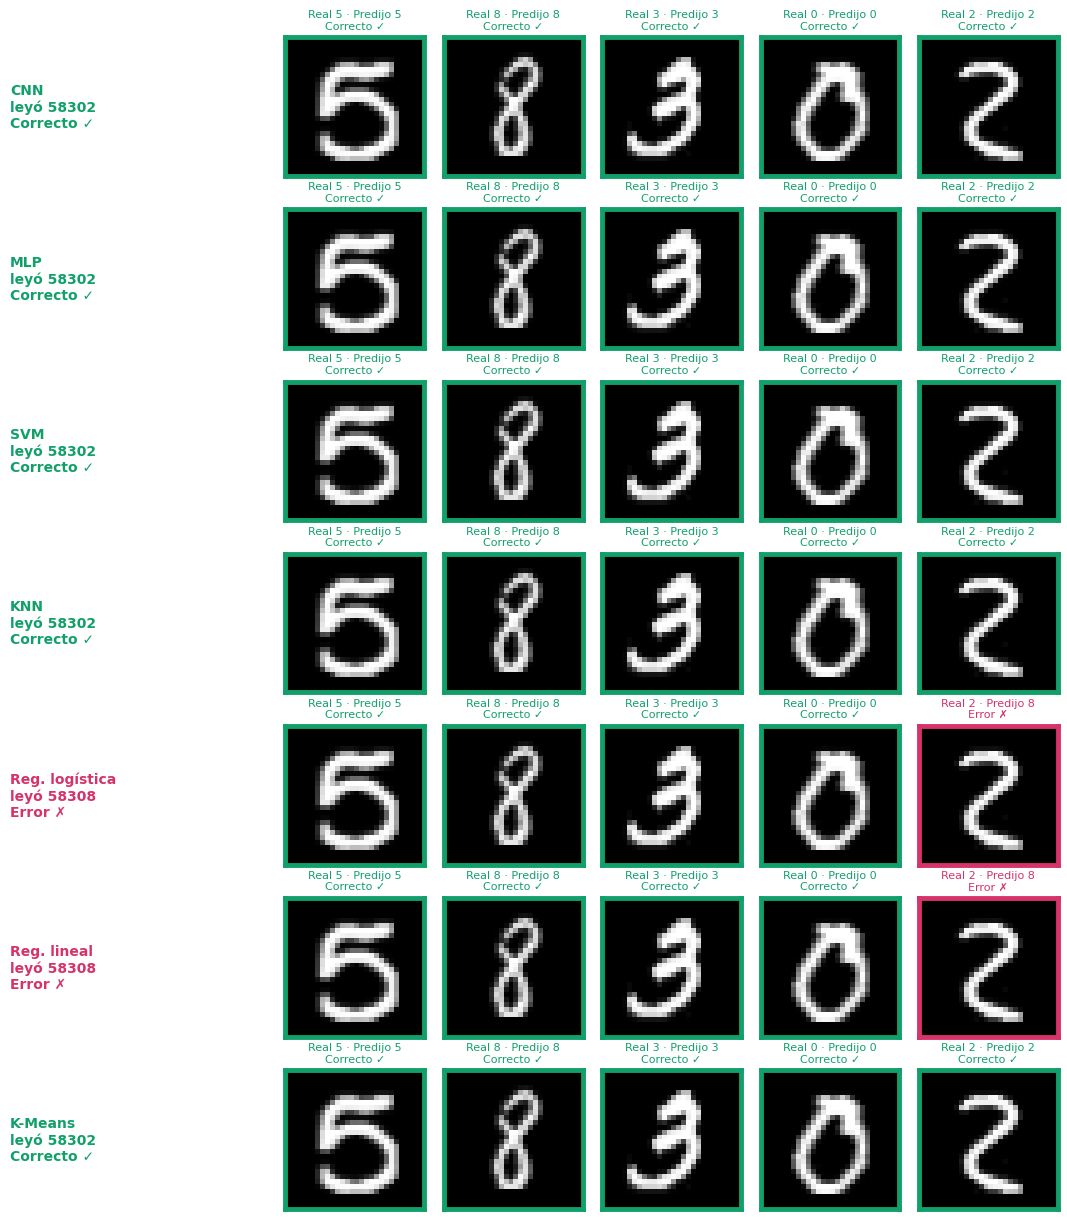

**Cómo lo hizo cada modelo con el dígito 5** (real 2):

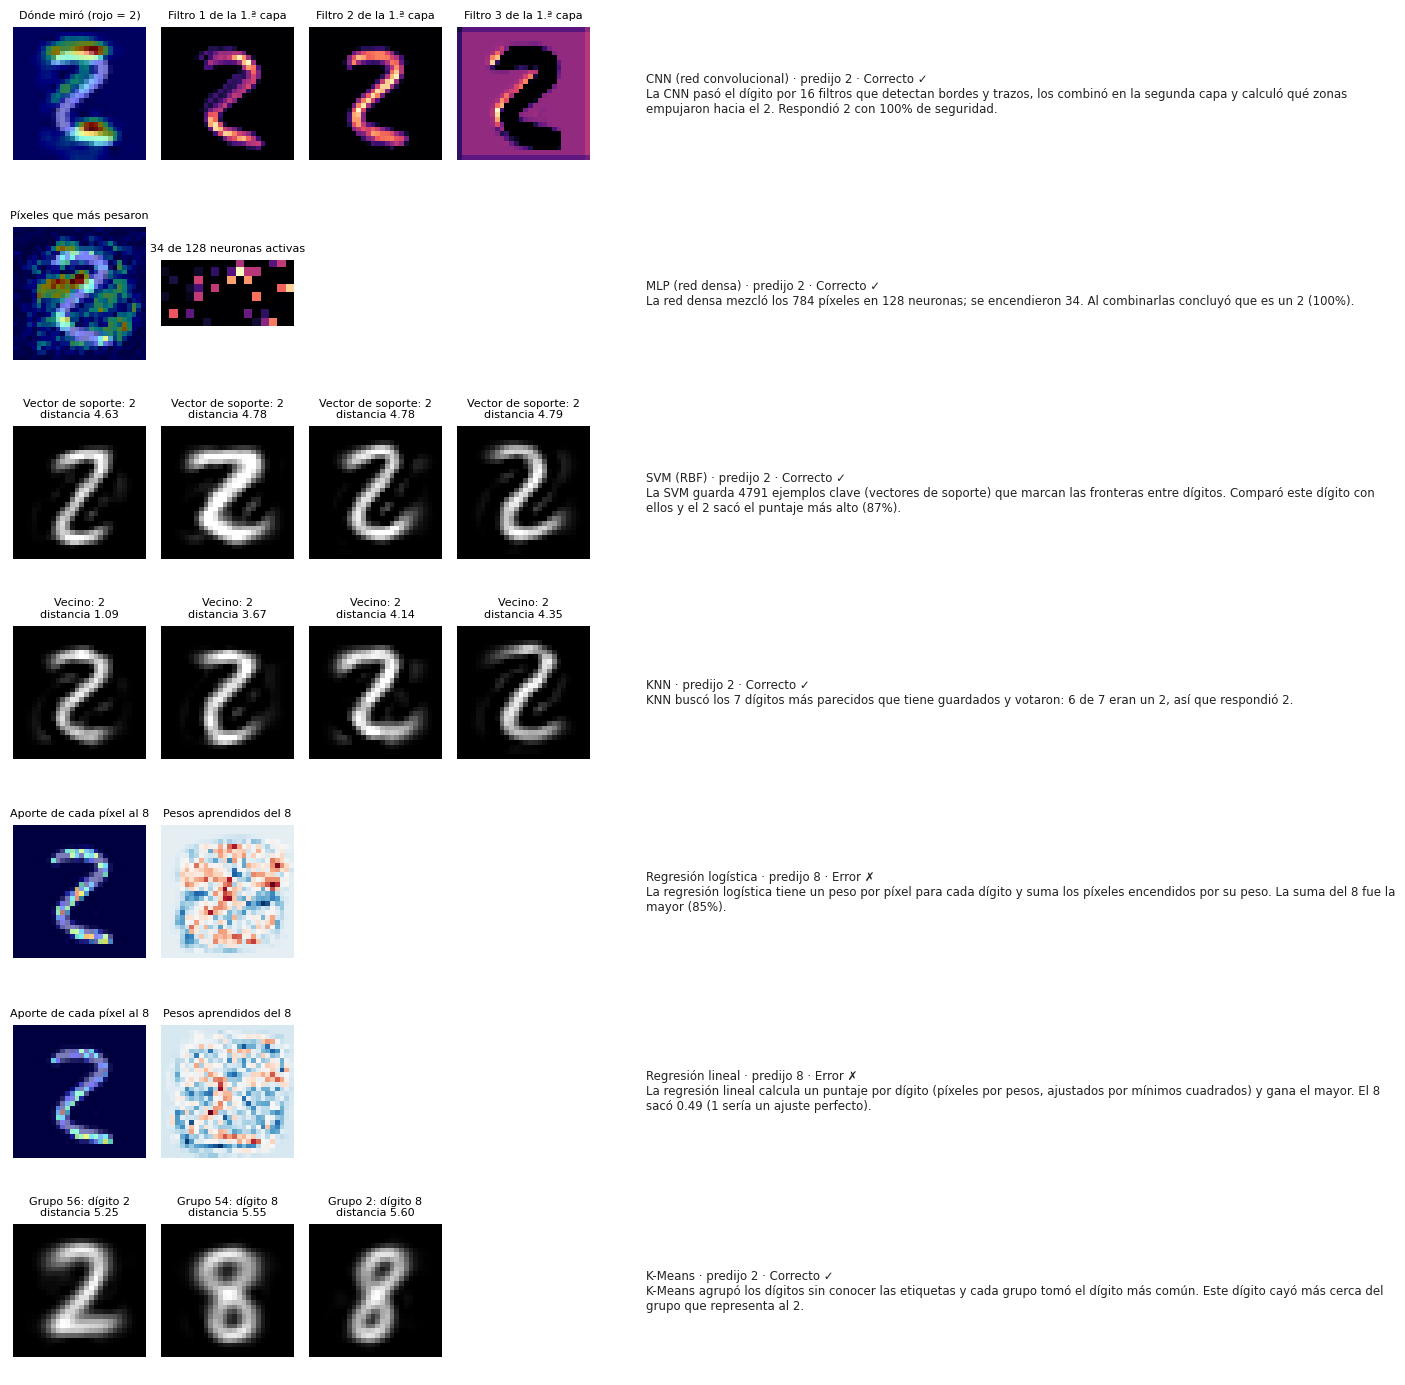

#### tinta azul en hoja rayada: número real **7194**

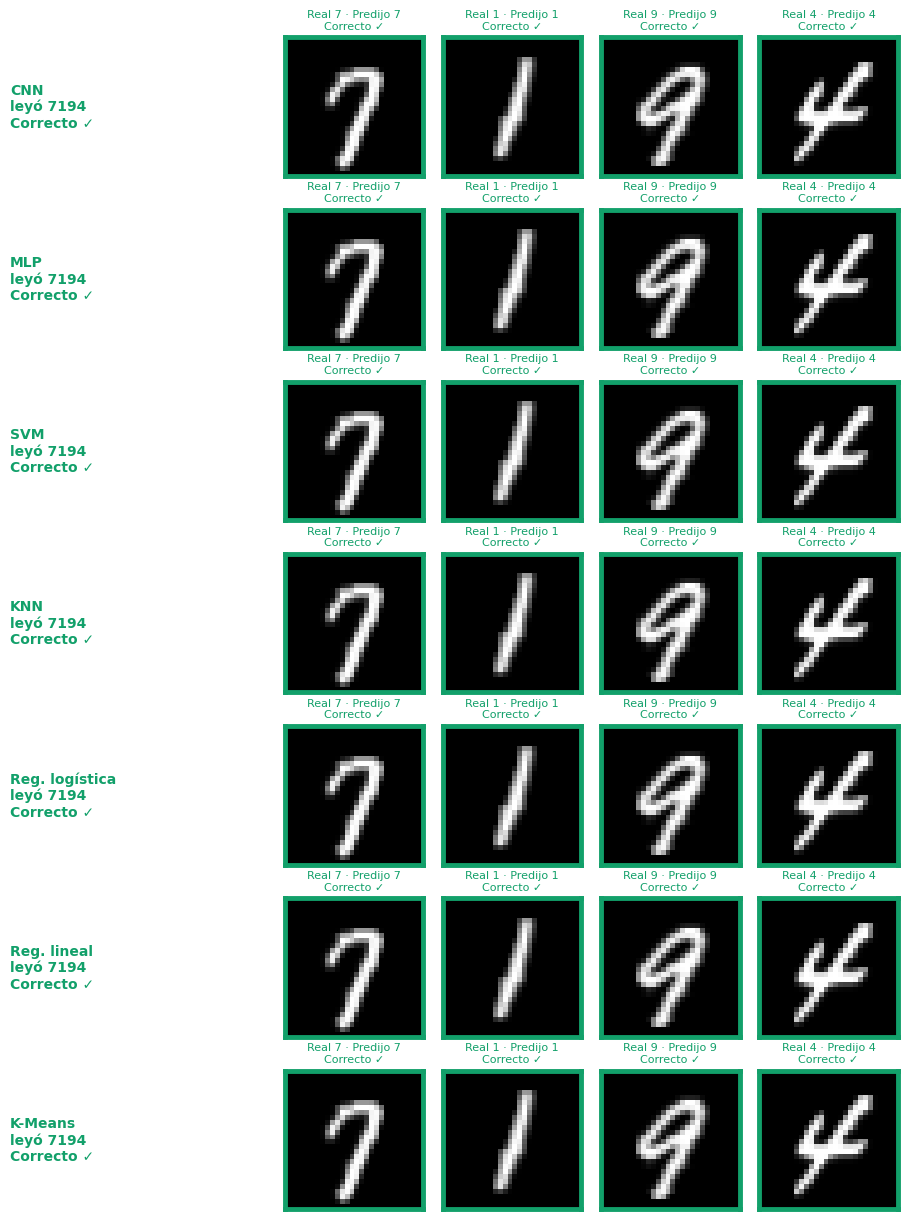

**Cómo lo hizo cada modelo con el dígito 1** (real 7):

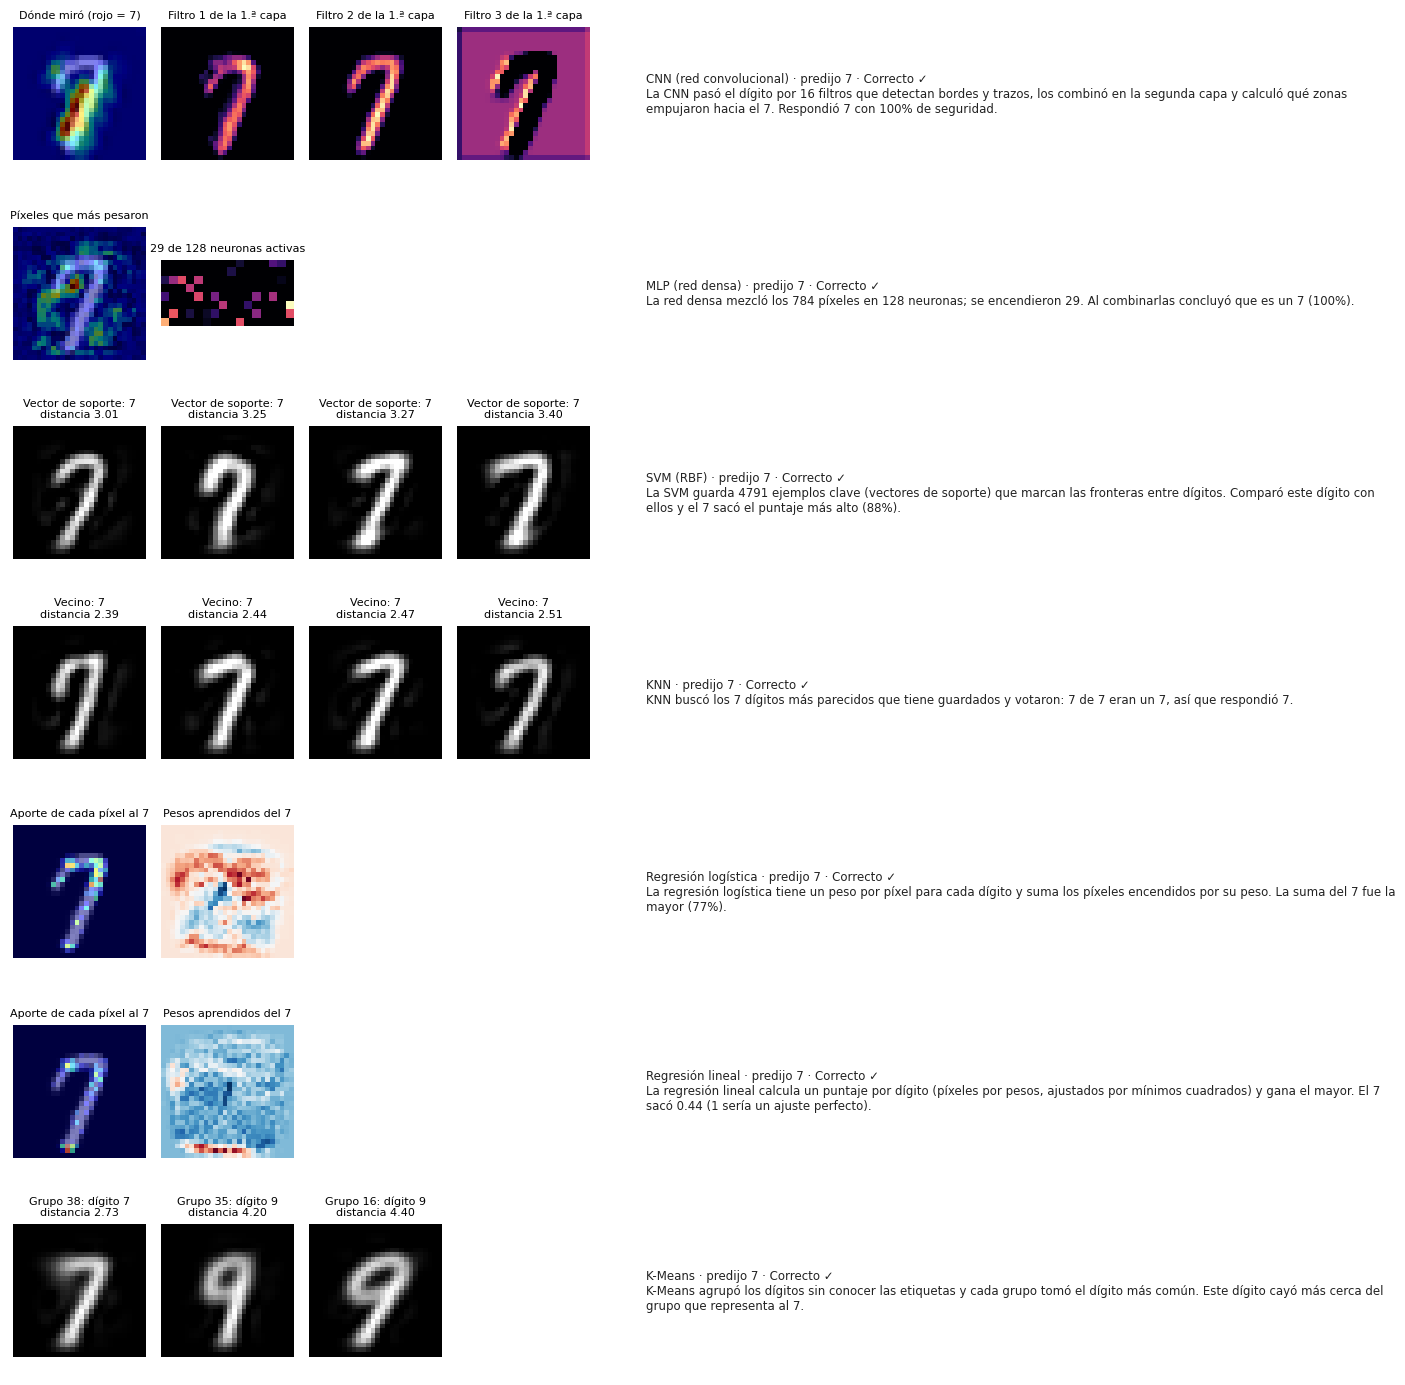

#### tinta verde en cuadrícula celeste: número real **2607**

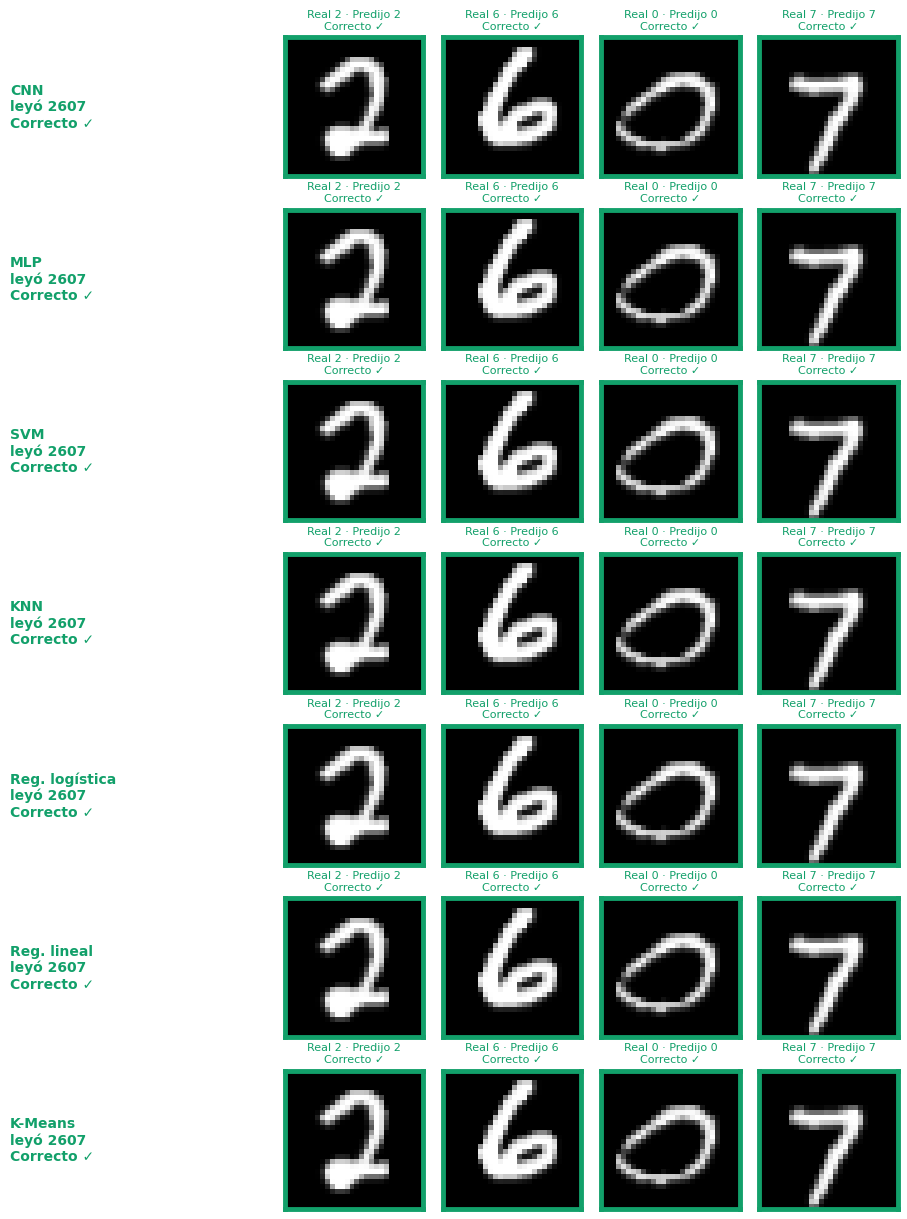

**Cómo lo hizo cada modelo con el dígito 1** (real 2):

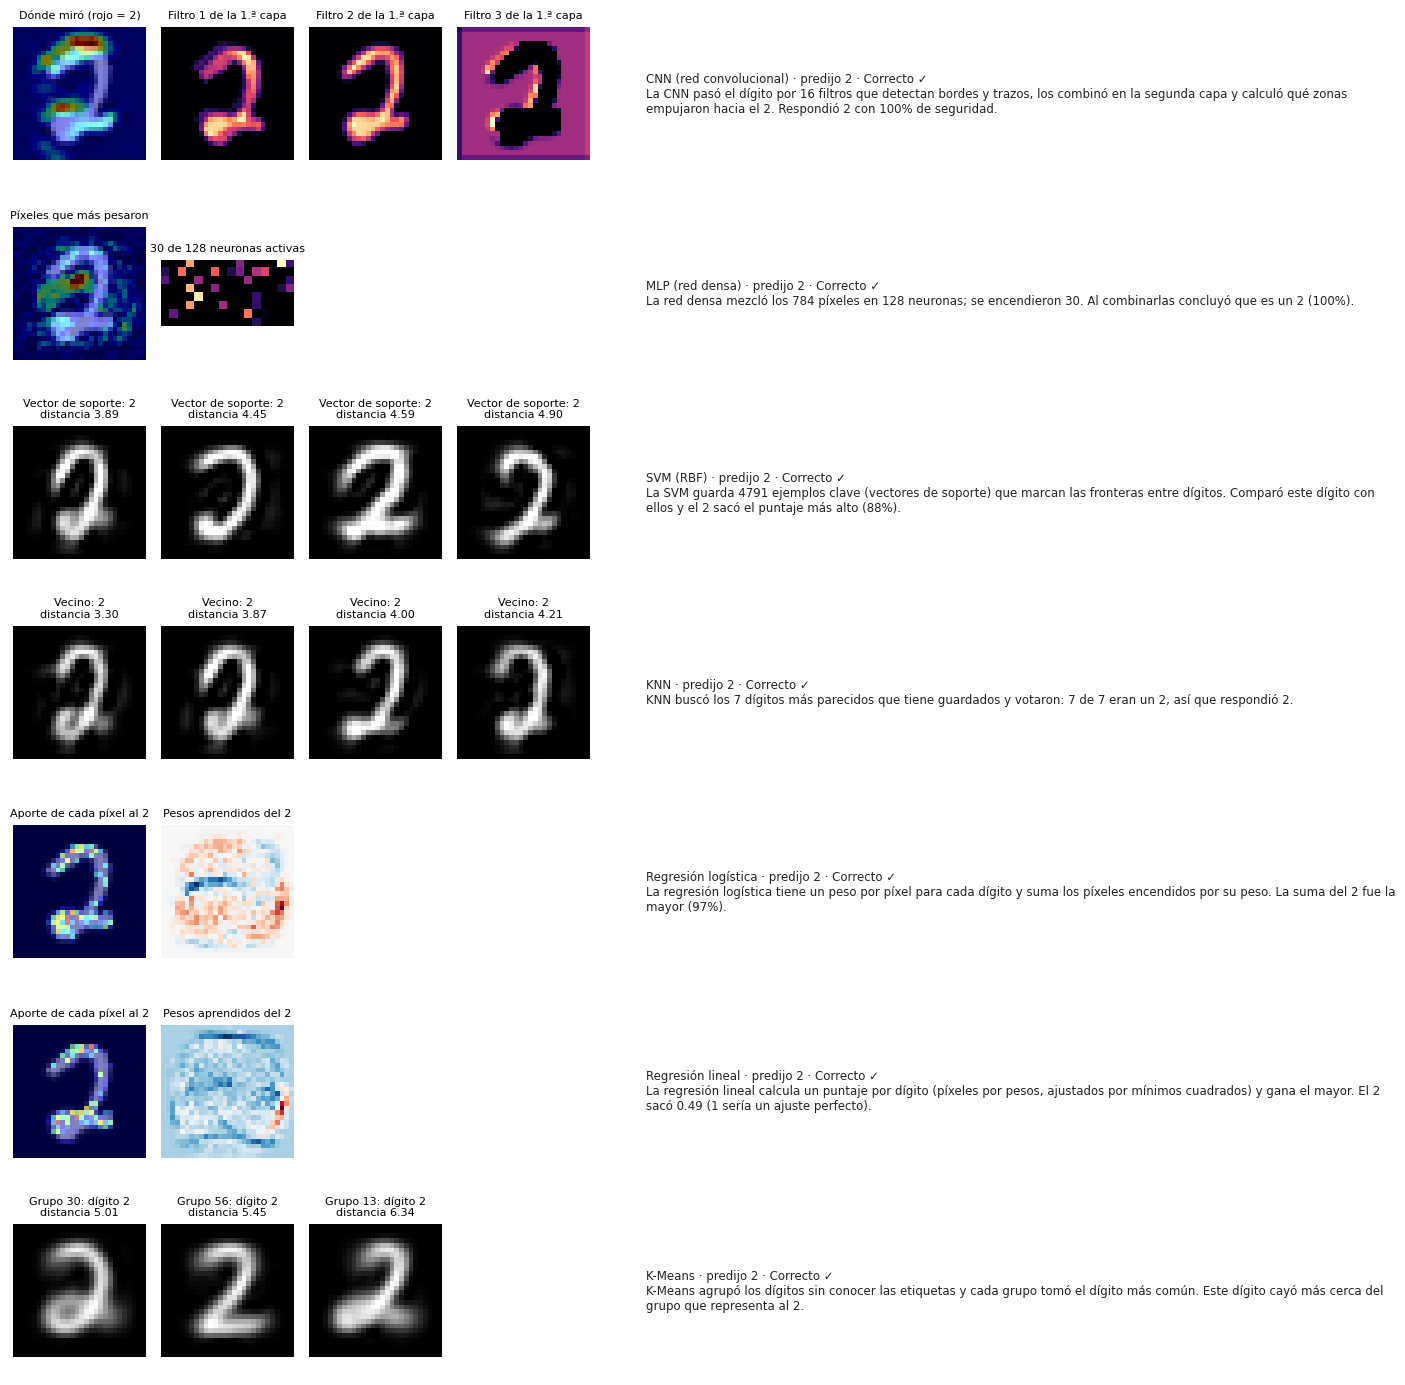

In [19]:
NUMEROS = ""  #@param {type:"string"}
DIGITO_A_EXPLICAR = 0  #@param {type:"integer"}

if not NUMEROS.strip() and not EN_COLAB:
    NUMEROS = "58302, 7194, 2607"   # fuera de Colab se usan los números de los ejemplos para mostrar el resultado
esperados = [n.strip() for n in NUMEROS.split(",")] if NUMEROS.strip() else []
esperados = [n if n.isdigit() else "" for n in esperados] + [""] * (len(MIS_FOTOS) - len(esperados))
DIGITOS_CON_NUMERO = []   # (dígitos 28x28, números reales, n.º de foto): los usa el paso 19 para corregir
if any(esperados):
    for posicion, ((nombre, imagen), esperado) in enumerate(zip(MIS_FOTOS, esperados)):
        if esperado:
            r = comprobar_foto(nombre, imagen, esperado, DIGITO_A_EXPLICAR)
            if r is not None and len(r["digitos"]) == len(esperado):
                DIGITOS_CON_NUMERO.append((r["digitos"], np.array([int(d) for d in esperado]), posicion))
else:
    print("No escribiste números: las lecturas de arriba quedan sin comprobar.")

## Paso 19 · Corregir a los modelos que se equivocaron (como «Entrenar a los que fallaron»)

**Qué hace:** con los dígitos de tus fotos que tienen número (paso 18 b), los modelos que se equivocaron aprenden de sus errores
**sin olvidar** lo que ya sabían. Se crea una versión nueva (v2, v3…) con los modelos que mejoraron.

**Cómo funciona** (el mismo método de la aplicación):
1. Solo aprenden los modelos que fallaron algún dígito; los que acertaron todo no cambian.
2. **Reserva para comprobar:** con 3 fotos o más, cerca del 30 % de las fotos no se usa para aprender, solo para ver si el modelo
   aprendió de verdad o solo memorizó.
3. Cada dígito fallado se practica con **20 variantes** (girado, más grande o más chico, corrido) y cada acierto con 3.
4. **Memoria:** junto con lo nuevo repasan 3000 dígitos de MNIST y los dígitos de correcciones anteriores.
5. Cada modelo aprende a su manera: las redes con un ajuste fino a tasa baja, KNN memorizando los dígitos nuevos, SVM reentrenando
   con sus vectores de soporte, la regresión logística siguiendo desde sus pesos, la regresión lineal sumando estadísticas y K-Means
   creando grupos nuevos para los dígitos mal agrupados.
6. **Solo se guarda si mejora sin perder:** si baja más de 0,5 puntos en el test de MNIST, si empieza a fallar dígitos de correcciones
   anteriores o si no corrige ningún dígito, se prueba con la mitad de fuerza y, si tampoco sirve, se queda el modelo anterior.

**Corrección con tus fotos:** 13 dígitos de 3 fotos; 9 para aprender y 4 en reserva para comprobar. Se equivocaron: Reg. logística, Reg. lineal.

,Modelo,Tus dígitos (antes → después),Reserva (antes → después),MNIST % (antes → después),Resultado,Motivo
0,CNN,9/9,4/4,"98,69",Sin cambios,No se equivocó: no necesita cambios.
1,MLP,9/9,4/4,"96,85",Sin cambios,No se equivocó: no necesita cambios.
2,SVM,9/9,4/4,"97,39",Sin cambios,No se equivocó: no necesita cambios.
3,KNN,9/9,4/4,"96,78",Sin cambios,No se equivocó: no necesita cambios.
4,Reg. logística,8/9 → 9/9,4/4 → 4/4,"92,33 → 90,07",Se mantuvo,"Bajaba en MNIST de 92,33 % a 90,07 %: se mantuvo el anterior para no perder lo aprendido."
5,Reg. lineal,8/9 → 8/9,4/4 → 4/4,"86,25 → 86,24",Se mantuvo,No logró corregir ningún dígito: se mantuvo el anterior.
6,K-Means,9/9,4/4,"85,04",Sin cambios,No se equivocó: no necesita cambios.


Ningún modelo mejoró sin perder lo aprendido: se conserva la versión actual.

**Tus fotos leídas otra vez (los modelos no cambiaron):**

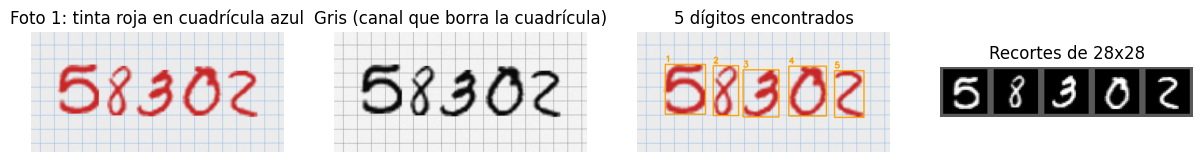

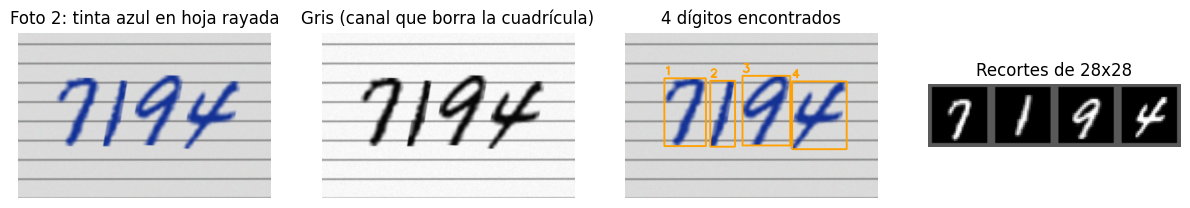

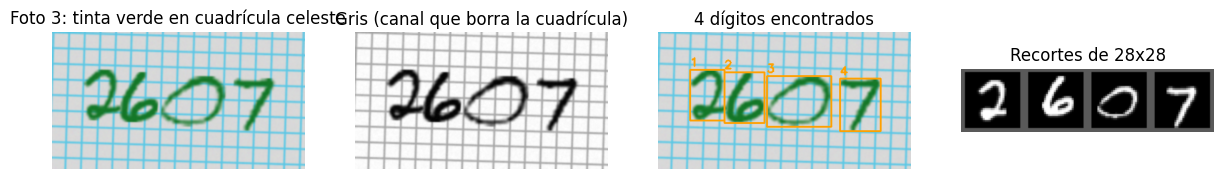

,Foto,Número real,CNN,MLP,SVM,KNN,Reg. logística,Reg. lineal,K-Means
0,1. tinta roja en cuadrícula azul,58302,58302 ✓,58302 ✓,58302 ✓,58302 ✓,58308 ✗,58308 ✗,58302 ✓
1,2. tinta azul en hoja rayada,7194,7194 ✓,7194 ✓,7194 ✓,7194 ✓,7194 ✓,7194 ✓,7194 ✓
2,3. tinta verde en cuadrícula celeste,2607,2607 ✓,2607 ✓,2607 ✓,2607 ✓,2607 ✓,2607 ✓,2607 ✓


In [20]:
import copy

TOLERANCIA_MNIST, COPIAS_ERROR, COPIAS_ACIERTO = 0.005, 20, 3
MUESTRA_MEMORIA_MNIST, COPIAS_MEMORIA_PREVIOS, FUERZAS = 3000, 4, (1.0, 0.4)
EXACTITUD_MNIST = {c: METRICAS[c]["exactitud"] for c in CLAVES}
VERSIONES = [{"Versión": "v1", "Origen": "Entrenamiento inicial con MNIST", "Modelos que cambiaron": "todos",
              **{CORTOS[c]: EXACTITUD_MNIST[c] * 100 for c in CLAVES}}]
MEMORIA_PROPIA = {"X": np.zeros((0, 784), np.float32), "y": np.zeros(0, np.int64)}
CORRECCIONES = []   # (título, tabla) para el informe


def aumentar(X, y, copias, semilla=0):
    # Variantes de cada dígito: giro, escala y desplazamiento pequeños
    if copias <= 0 or len(y) == 0:
        return X.copy(), y.copy()
    azar = np.random.default_rng(semilla)
    bloques_x, bloques_y = [X], [y]
    for _ in range(copias):
        nuevo = np.empty_like(X)
        for i, vector in enumerate(X):
            matriz = cv2.getRotationMatrix2D((13.5, 13.5), azar.uniform(-12, 12), azar.uniform(0.9, 1.1))
            matriz[:, 2] += azar.uniform(-2, 2, size=2)
            nuevo[i] = cv2.warpAffine(vector.reshape(28, 28), matriz, (28, 28)).reshape(-1)
        bloques_x.append(nuevo); bloques_y.append(y)
    return np.concatenate(bloques_x), np.concatenate(bloques_y)


def elegir_reserva(fotos, errores_por_modelo):
    # Con 3 fotos o más se reserva ~30 % para comprobar; cada modelo conserva para aprender al menos la mitad de sus fotos con errores
    if len(fotos) < 3:
        return set()
    cantidad, reserva = max(1, round(0.3 * len(fotos))), set()
    for foto in sorted(fotos, key=lambda i: (i * 2654435761) % 4294967296):
        if len(reserva) == cantidad:
            break
        prueba = reserva | {foto}
        if all(not f or (f - prueba and len(f - prueba) >= len(f) / 2) for f in errores_por_modelo.values()):
            reserva = prueba
    return reserva


def fraccion(a, b):
    return f"{a}/{b}" if b else "—"


def corregir(grupos, titulo):
    # grupos: lista de (dígitos 28x28, números reales, n.º de foto)
    if not grupos:
        print("No hay dígitos con número: escribe los números en el paso 18 b (o elige imágenes en el paso 20).")
        return None
    X = np.concatenate([g[0] for g in grupos]).astype(np.float32)
    y = np.concatenate([g[1] for g in grupos]).astype(np.int64)
    fotos = np.concatenate([[g[2]] * len(g[1]) for g in grupos])
    predicho = {c: MODELOS[c].predecir(X) for c in CLAVES}
    errores_foto = {c: {int(f) for f, p, r in zip(fotos, predicho[c], y) if p != r} for c in CLAVES}
    reserva_fotos = elegir_reserva(sorted({int(f) for f in fotos}), errores_foto)
    en_reserva = np.array([int(f) in reserva_fotos for f in fotos])
    Xa, ya, Xr, yr = X[~en_reserva], y[~en_reserva], X[en_reserva], y[en_reserva]
    con_errores = [c for c in CLAVES if (predicho[c][~en_reserva] != ya).any()]
    numero = len(VERSIONES) + 1
    X_mem, y_mem = submuestra_estratificada(x_ent, y_ent, MUESTRA_MEMORIA_MNIST, semilla=numero)
    hay_previos = len(MEMORIA_PROPIA["y"]) > 0
    if hay_previos:
        X_prev, y_prev = aumentar(MEMORIA_PROPIA["X"], MEMORIA_PROPIA["y"], COPIAS_MEMORIA_PREVIOS, semilla=numero)
        X_mem, y_mem = np.concatenate([X_mem, X_prev]), np.concatenate([y_mem, y_prev])
    display(Markdown(f"**{titulo}:** {len(y)} dígitos de {len(set(fotos.tolist()))} fotos; {len(ya)} para aprender y {len(yr)} en reserva "
                     f"para comprobar. Se equivocaron: {', '.join(CORTOS[c] for c in con_errores) or 'ninguno'}."))
    filas, aceptados = [], {}
    for c in CLAVES:
        actual = MODELOS[c]
        errores_antes = int((predicho[c][~en_reserva] != ya).sum())
        fila = {"Modelo": CORTOS[c], "Tus dígitos (antes → después)": fraccion(len(ya) - errores_antes, len(ya)),
                "Reserva (antes → después)": fraccion(int((predicho[c][en_reserva] == yr).sum()), len(yr)),
                "MNIST % (antes → después)": es(f"{EXACTITUD_MNIST[c] * 100:.2f}"), "Resultado": "Sin cambios",
                "Motivo": "No se equivocó: no necesita cambios."}
        if c not in con_errores:
            filas.append(fila)
            continue
        malos = predicho[c][~en_reserva] != ya
        X_err, y_err = aumentar(Xa[malos], ya[malos], COPIAS_ERROR, semilla=numero)
        X_ok, y_ok = aumentar(Xa[~malos], ya[~malos], COPIAS_ACIERTO, semilla=numero + 1)
        X_nuevo, y_nuevo = np.concatenate([X_err, X_ok]), np.concatenate([y_err, y_ok])
        previos_antes = int((actual.predecir(MEMORIA_PROPIA["X"]) == MEMORIA_PROPIA["y"]).sum()) if hay_previos else 0
        for fuerza in FUERZAS:
            candidato = copy.deepcopy(actual)
            candidato.actualizar(X_nuevo, y_nuevo, X_mem, y_mem, fuerza)
            mnist_despues = float((candidato.predecir(x_pru) == y_pru).mean())
            errores_despues = int((candidato.predecir(Xa) != ya).sum())
            previos_despues = int((candidato.predecir(MEMORIA_PROPIA["X"]) == MEMORIA_PROPIA["y"]).sum()) if hay_previos else 0
            if mnist_despues < EXACTITUD_MNIST[c] - TOLERANCIA_MNIST:
                motivo = es(f"Bajaba en MNIST de {EXACTITUD_MNIST[c] * 100:.2f} % a {mnist_despues * 100:.2f} %: se mantuvo el anterior para no perder lo aprendido.")
            elif hay_previos and previos_despues < previos_antes - max(1, round(0.05 * len(MEMORIA_PROPIA["y"]))):
                motivo = "Empezaba a fallar dígitos de correcciones anteriores: se mantuvo el anterior."
            elif errores_despues >= errores_antes:
                motivo = "No logró corregir ningún dígito: se mantuvo el anterior."
            else:
                motivo = None
                break
        reserva_despues = int((candidato.predecir(Xr) == yr).sum()) if len(yr) else 0
        fila["Tus dígitos (antes → después)"] = f"{fraccion(len(ya) - errores_antes, len(ya))} → {fraccion(len(ya) - errores_despues, len(ya))}"
        if len(yr):
            fila["Reserva (antes → después)"] = f"{fraccion(int((predicho[c][en_reserva] == yr).sum()), len(yr))} → {fraccion(reserva_despues, len(yr))}"
        fila["MNIST % (antes → después)"] = es(f"{EXACTITUD_MNIST[c] * 100:.2f} → {mnist_despues * 100:.2f}")
        if motivo is None:
            aceptados[c] = (candidato, mnist_despues)
            fila["Resultado"] = "Guardado ✓"
            fila["Motivo"] = (f"Corrigió {errores_antes - errores_despues} de {errores_antes} dígitos sin perder en MNIST"
                              + (" (con la mitad de fuerza)" if fuerza < 1 else "") + ".")
        else:
            fila["Resultado"] = "Se mantuvo"
            fila["Motivo"] = motivo
        filas.append(fila)
    tabla = pd.DataFrame(filas)
    display(tabla)
    CORRECCIONES.append((titulo, tabla))
    if not aceptados:
        display(Markdown("Ningún modelo mejoró sin perder lo aprendido: se conserva la versión actual."))
        return tabla
    for c, (candidato, exactitud) in aceptados.items():
        MODELOS[c] = candidato
        EXACTITUD_MNIST[c] = exactitud
    MEMORIA_PROPIA["X"] = np.concatenate([MEMORIA_PROPIA["X"], X]); MEMORIA_PROPIA["y"] = np.concatenate([MEMORIA_PROPIA["y"], y])
    VERSIONES.append({"Versión": f"v{numero}", "Origen": titulo, "Modelos que cambiaron": ", ".join(CORTOS[c] for c in aceptados),
                      **{CORTOS[c]: EXACTITUD_MNIST[c] * 100 for c in CLAVES}})
    display(Markdown(f"**Versión nueva v{numero}** con {', '.join(CORTOS[c] for c in aceptados)}. Exactitud en MNIST de cada versión (%):"))
    display(pd.DataFrame(VERSIONES).set_index("Versión").round(2))
    return tabla


versiones_antes = len(VERSIONES)
corregir(DIGITOS_CON_NUMERO, "Corrección con tus fotos")
if DIGITOS_CON_NUMERO:
    display(Markdown("**Tus fotos leídas otra vez " + ("con la versión nueva:**" if len(VERSIONES) > versiones_antes else "(los modelos no cambiaron):**")))
    mostrar_lectura(MIS_FOTOS, esperados[: len(MIS_FOTOS)])

## Paso 20 · Práctica con imágenes (datos ficticios)

**Qué hace:** igual que «Práctica con imágenes» de la aplicación: creas imágenes nuevas eligiendo **tipo, dificultad y cantidad**,
ves qué lee cada modelo y luego entrenas a los que se equivocaron.

**Cómo funciona:**
1. Elige en los cuadros: `TIPO` (hoja lisa, hoja cuadriculada o formulario), `DIFICULTAD` (fácil, normal, difícil, muy difícil o mezcla)
   y `CANTIDAD` (en formularios, cada formulario trae 4 campos y se crean como máximo 5).
2. Se crean con el generador del paso 4. La dificultad sube el ruido, la sombra, el desenfoque, la inclinación y los dígitos pegados.
3. Los siete modelos leen cada imagen (sabiendo cuántas cifras tiene) y se marca **✓** o **✗**.
4. En el paso 20 b eliges con cuáles entrenar (`ELEGIDAS`): `todas` o los números de imagen, por ejemplo `1, 3, 5`.

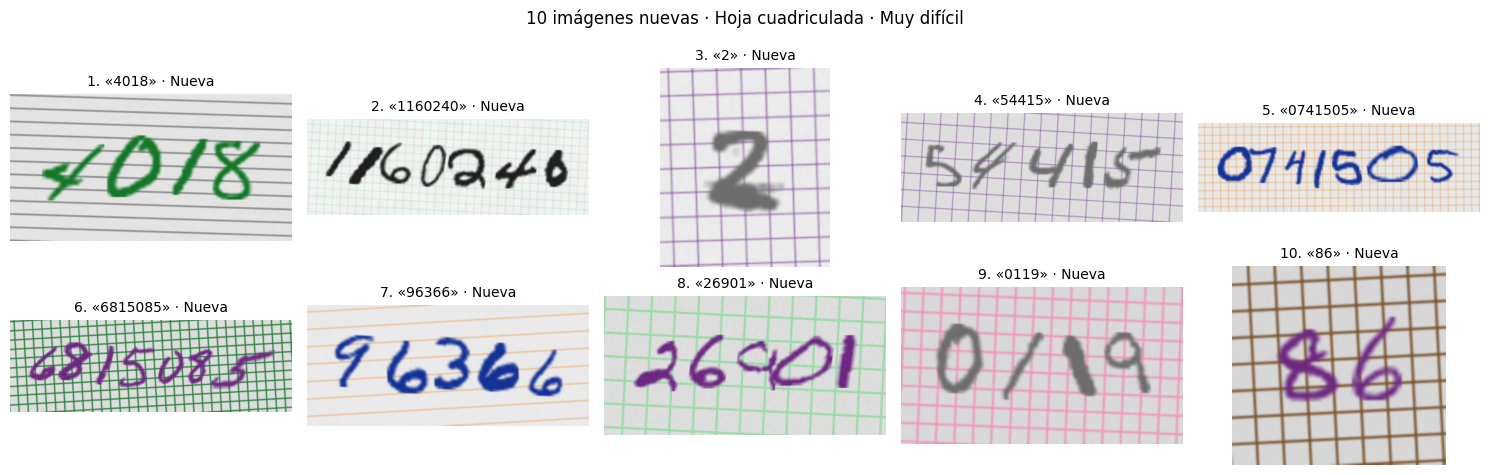

,Real,CNN,MLP,SVM,KNN,Reg. logística,Reg. lineal,K-Means
Imagen,,,,,,,,
1,4018,4018 ✓,4018 ✓,4018 ✓,4018 ✓,4018 ✓,4018 ✓,5013 ✗
2,1160240,1160246 ✗,1860246 ✗,1160240 ✓,1160240 ✓,1860246 ✗,1160246 ✗,1160246 ✗
3,2,2 ✓,2 ✓,2 ✓,2 ✓,2 ✓,2 ✓,2 ✓
4,54415,54415 ✓,59416 ✗,59416 ✗,54416 ✗,54416 ✗,54416 ✗,57416 ✗
5,0741505,0741505 ✓,0741505 ✓,0741505 ✓,0741505 ✓,0741505 ✓,0741505 ✓,0791503 ✗
6,6815085,9150825 ✗,4152825 ✗,4150825 ✗,2150825 ✗,4150848 ✗,4150815 ✗,9150825 ✗
7,96366,96366 ✓,96366 ✓,96366 ✓,96366 ✓,96366 ✓,96366 ✓,96366 ✓
8,26901,26001 ✗,26001 ✗,26001 ✗,26001 ✗,26501 ✗,26001 ✗,26001 ✗
9,0119,0119 ✓,0119 ✓,0119 ✓,0119 ✓,0189 ✗,0189 ✗,0119 ✓


,CNN,MLP,SVM,KNN,Reg. logística,Reg. lineal,K-Means
Antes de entrenar (% números exactos),70.0,60.0,70.0,70.0,50.0,50.0,30.0


In [21]:
TIPO = "Hoja cuadriculada"  #@param ["Hoja lisa", "Hoja cuadriculada", "Formulario"]
DIFICULTAD = "Muy difícil"  #@param ["Fácil", "Normal", "Difícil", "Muy difícil", "Mezcla"]
CANTIDAD = 10  #@param [5, 10, 20] {type:"raw"}

NIVELES = {"Fácil": (0.15, 0.2), "Normal": (0.35, 0.35), "Difícil": (0.55, 0.5), "Muy difícil": (0.8, 0.75)}
MEZCLA_NUMEROS, MEZCLA_FORMULARIOS = [0.15, 0.35, 0.55, 0.8], [0.2, 0.35, 0.5, 0.65]
gen_practica = GeneradorDigitos(x_ent, y_ent, semilla=31415)
PRACTICA = []   # (nombre, imagen, número real)
if TIPO == "Formulario":
    for i in range(min(5, max(1, int(CANTIDAD) // 4))):
        nivel = NIVELES[DIFICULTAD][1] if DIFICULTAD in NIVELES else MEZCLA_FORMULARIOS[i % 4]
        hoja, campos = gen_practica.formulario(list(TIPOS_FORMULARIO)[i % 3], nivel)
        PRACTICA += [(f"Formulario {i + 1} · {c['etiqueta']}", recortar_campo(hoja, c["caja"]), c["valor"]) for c in campos]
else:
    for i in range(int(CANTIDAD)):
        nivel = NIVELES[DIFICULTAD][0] if DIFICULTAD in NIVELES else MEZCLA_NUMEROS[i % 4]
        numero = gen_practica.numero_aleatorio(int(gen_practica.azar.integers(1, 8)))
        if TIPO == "Hoja lisa":
            imagen = gen_practica.foto_numero(numero, nivel, toque=0.25 if nivel >= 0.7 else 0.1 if nivel >= 0.5 else 0.0)
        else:
            imagen = gen_practica.foto_cuadriculada(numero, nivel)
        PRACTICA.append((f"{TIPO} {i + 1}", imagen, numero))

columnas = 5
filas_galeria = (len(PRACTICA) + columnas - 1) // columnas
figura, ejes = plt.subplots(filas_galeria, columnas, figsize=(15, 2.4 * filas_galeria))
for eje in np.atleast_1d(ejes).flat:
    eje.axis("off")
for i, (nombre, imagen, numero) in enumerate(PRACTICA):
    eje = np.atleast_1d(ejes).flat[i]
    eje.imshow(cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB)); eje.set_title(f"{i + 1}. «{numero}» · Nueva", fontsize=10)
figura.suptitle(f"{len(PRACTICA)} imágenes nuevas · {TIPO} · {DIFICULTAD}", fontsize=12)
figura.tight_layout()
plt.show()


def leer_practica(titulo):
    filas, grupos = [], []
    for i, (nombre, imagen, numero) in enumerate(PRACTICA):
        r = procesar_foto(imagen, len(numero))
        fila = {"Imagen": i + 1, "Real": numero}
        for c in CLAVES:
            leido = "".join(str(d) for d in MODELOS[c].predecir(r["digitos"])) if len(r["digitos"]) else "—"
            fila[CORTOS[c]] = leido + (" ✓" if leido == numero else " ✗")
        filas.append(fila)
        if len(r["digitos"]) == len(numero):
            grupos.append((r["digitos"], np.array([int(d) for d in numero]), i + 1))
    tabla = pd.DataFrame(filas).set_index("Imagen")
    resumen = pd.Series({CORTOS[c]: tabla[CORTOS[c]].str.endswith("✓").mean() * 100 for c in CLAVES}, name=titulo)
    return tabla, resumen, grupos


tabla_practica, ANTES_PRACTICA, GRUPOS_PRACTICA = leer_practica("Antes de entrenar (% números exactos)")
display(tabla_practica)
display(ANTES_PRACTICA.round(1).to_frame().T)

### Paso 20 b · Entrenar a los modelos con las imágenes elegidas

**Qué hace:** los modelos que se equivocaron en las imágenes elegidas aprenden de ellas con el mismo método del paso 19
(reserva para comprobar, variantes, memoria y la regla de no perder más de 0,5 puntos en MNIST).

**Cómo funciona:** escribe en `ELEGIDAS` `todas` o los números de imagen separados por comas. Al final se vuelven a leer las mismas
imágenes y se comparan los aciertos antes y después.

**Práctica: 10 imágenes (Hoja cuadriculada, Muy difícil):** 47 dígitos de 10 fotos; 31 para aprender y 16 en reserva para comprobar. Se equivocaron: CNN, MLP, SVM, KNN, Reg. logística, Reg. lineal, K-Means.

,Modelo,Tus dígitos (antes → después),Reserva (antes → después),MNIST % (antes → después),Resultado,Motivo
0,CNN,24/31 → 26/31,15/16 → 14/16,"98,69 → 98,51",Guardado ✓,Corrigió 2 de 7 dígitos sin perder en MNIST.
1,MLP,22/31 → 26/31,14/16 → 14/16,"96,85 → 96,47",Guardado ✓,Corrigió 4 de 9 dígitos sin perder en MNIST.
2,SVM,22/31 → 31/31,16/16 → 16/16,"97,39 → 97,44",Guardado ✓,Corrigió 9 de 9 dígitos sin perder en MNIST.
3,KNN,23/31 → 31/31,16/16 → 16/16,"96,78 → 96,77",Guardado ✓,Corrigió 8 de 8 dígitos sin perder en MNIST.
4,Reg. logística,21/31 → 27/31,14/16 → 15/16,"92,33 → 87,81",Se mantuvo,"Bajaba en MNIST de 92,33 % a 87,81 %: se mantuvo el anterior para no perder lo aprendido."
5,Reg. lineal,22/31 → 22/31,15/16 → 15/16,"86,25 → 86,19",Se mantuvo,No logró corregir ningún dígito: se mantuvo el anterior.
6,K-Means,20/31 → 31/31,12/16 → 12/16,"85,04 → 82,65",Se mantuvo,"Bajaba en MNIST de 85,04 % a 82,65 %: se mantuvo el anterior para no perder lo aprendido."


**Versión nueva v2** con CNN, MLP, SVM, KNN. Exactitud en MNIST de cada versión (%):

,Origen,Modelos que cambiaron,CNN,MLP,SVM,KNN,Reg. logística,Reg. lineal,K-Means
Versión,,,,,,,,,
v1,Entrenamiento inicial con MNIST,todos,98.69,96.85,97.39,96.78,92.33,86.25,85.04
v2,"Práctica: 10 imágenes (Hoja cuadriculada, Muy difícil)","CNN, MLP, SVM, KNN",98.51,96.47,97.44,96.77,92.33,86.25,85.04


,Antes de entrenar (% números exactos),Después de entrenar (% números exactos)
CNN,70.0,80.0
MLP,60.0,70.0
SVM,70.0,100.0
KNN,70.0,100.0
Reg. logística,50.0,50.0
Reg. lineal,50.0,50.0
K-Means,30.0,30.0


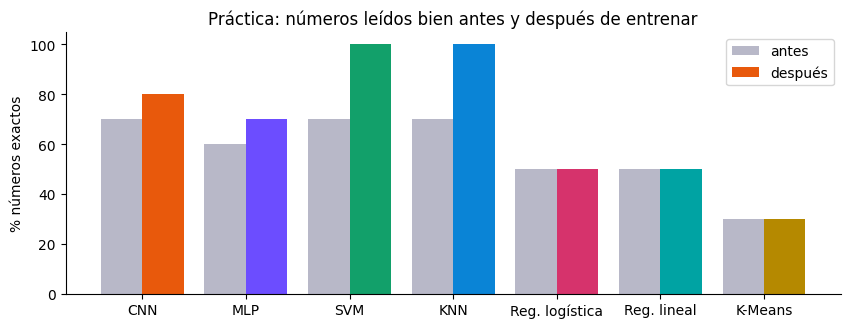

In [22]:
ELEGIDAS = "todas"  #@param {type:"string"}

if ELEGIDAS.strip().lower() in ("", "todas"):
    numeros_elegidos = {g[2] for g in GRUPOS_PRACTICA}
else:
    numeros_elegidos = {int(x) for x in ELEGIDAS.replace(" ", "").split(",") if x.isdigit()}
elegidos = [g for g in GRUPOS_PRACTICA if g[2] in numeros_elegidos][:20]
corregir(elegidos, f"Práctica: {len(elegidos)} imágenes ({TIPO}, {DIFICULTAD})")
_, DESPUES_PRACTICA, _ = leer_practica("Después de entrenar (% números exactos)")
comparacion_practica = pd.concat([ANTES_PRACTICA, DESPUES_PRACTICA], axis=1).round(1)
display(comparacion_practica)
figura, eje = plt.subplots(figsize=(10, 3.4))
posiciones = np.arange(len(CLAVES))
eje.bar(posiciones - 0.2, ANTES_PRACTICA.values, 0.4, label="antes", color="#b8b8c8")
eje.bar(posiciones + 0.2, DESPUES_PRACTICA.values, 0.4, label="después", color=[COLORES[c] for c in CLAVES])
eje.set_xticks(posiciones); eje.set_xticklabels([CORTOS[c] for c in CLAVES]); eje.set_ylabel("% números exactos")
eje.set_title("Práctica: números leídos bien antes y después de entrenar"); eje.legend()
guardar_figura(figura, "practica_antes_despues")

## Paso 21 · Informe: pasos, razonamiento, algoritmos y resultados

**Qué hace:** resume todo el trabajo en texto y genera el **informe en PDF** con las tablas y gráficos de esta ejecución
(`Informe_Cifra_TecnoForms.pdf`). En Colab se descarga solo; también queda en la carpeta del cuaderno.

**Cómo funciona:** el texto usa los números reales obtenidos arriba; el PDF se arma con ReportLab (portada, secciones, tablas y
figuras guardadas en `resultados_colab/`).

In [23]:
seg_media = segmentacion["sabiendo_cuantos"].mean()
mejor_fict = por_modelo.index[0]
exacto_tipo = ficticios[ficticios["modelo"] == mejor_fict].groupby("tipo")["exacto"].mean() * 100
tipo_dificil = exacto_tipo.idxmin()
INFORME = [
    ("1. Objetivo", [
        "TecnoForms necesita leer automáticamente los números escritos a mano en sus formularios (códigos, teléfonos, montos). "
        "Se construyó un sistema que toma la foto, separa cada dígito y lo clasifica, y se compararon siete algoritmos para elegir el mejor."]),
    ("2. Datos", [
        f"Datos de internet: MNIST, 60 000 dígitos para entrenar y 10 000 para el test final, escritos por personas reales; clases equilibradas "
        f"(entre {conteo['entrenamiento'].min():,} y {conteo['entrenamiento'].max():,} imágenes por dígito).",
        "Datos ficticios: formularios de inscripción, pago y solicitud, y números en hoja lisa o cuadriculada, armados con dígitos de MNIST "
        "y degradados (sombras, ruido, desenfoque, hojas torcidas y de colores). Se usan para probar el preprocesado y el sistema completo."]),
    ("3. Preparación de las imágenes", [
        "Pasos: limitar el tamaño, escala de grises (eligiendo el canal de color que borra la cuadrícula), normalizar la iluminación dividiendo "
        "por el fondo, binarizar con Otsu, quitar líneas de cuadrícula o renglones, segmentar con componentes conectados (uniendo trazos de un "
        "mismo dígito y partiendo dígitos pegados), recortar cada dígito a 20 px centrado por centro de masa en 28 x 28 y normalizar a 0-1.",
        f"Razonamiento: los modelos aprenden con MNIST, así que cada recorte debe verse como un dígito de MNIST. Con el número de cifras conocido, "
        f"la segmentación separó bien el {seg_media:.1f} % de las imágenes ficticias de prueba."]),
    ("4. Algoritmos elegidos", [
        "Modelo principal: red neuronal convolucional (CNN), porque sus filtros detectan trazos y curvas en cualquier posición. Se compara con una "
        "red densa (MLP), SVM con núcleo RBF, KNN, regresión logística, regresión lineal y K-Means (no supervisado). SVM, KNN y K-Means trabajan "
        "sobre 50 componentes PCA para ir más rápido."]),
    ("5. Arquitectura de la CNN", [
        f"Dos bloques convolucionales (3x3, {MODELOS['cnn'].parametros['filtros']} y {2 * MODELOS['cnn'].parametros['filtros']} filtros, ReLU y MaxPool 2x2), "
        f"dropout {MODELOS['cnn'].parametros['dropout']}, una capa densa de 64 neuronas ReLU y la salida de 10 neuronas con softmax; "
        f"{MODELOS['cnn'].total_parametros():,} parámetros. Optimizador Adam con tasa {MODELOS['cnn'].parametros['tasa_aprendizaje']}, "
        f"entropía cruzada, lotes de 128 y {MODELOS['cnn'].parametros['epocas']} épocas."]),
    ("6. Entrenamiento, validación cruzada e hiperparámetros", [
        "Cada modelo probó una malla de hiperparámetros con validación cruzada estratificada de 5 pliegues sobre 5000 dígitos, y se quedó con la "
        "combinación de mejor exactitud media. Luego se entrenó con 30 000 dígitos (SVM 10 000 y KNN 20 000).",
        "Elegidos: " + "; ".join(f"{CORTOS[c]} {', '.join(f'{k}={v}' for k, v in MEJORES[c].items())}" for c in CLAVES) + "."]),
    ("7. Resultados en el test", INTERPRETACION),
    ("8. Sistema completo con datos ficticios", [
        f"Con {len(imagenes_prueba)} números ficticios (hoja lisa, cuadriculada y campos de formulario), el mejor fue {mejor_fict}: "
        f"{por_modelo.iloc[0]['Dígitos bien (%)']:.1f} % de dígitos bien y {por_modelo.iloc[0]['Número exacto (%)']:.1f} % de números exactos. "
        f"Donde más le costó fue en «{tipo_dificil}» ({exacto_tipo[tipo_dificil]:.1f} % de números exactos): basta un dígito mal para fallar "
        "todo el número, y los campos de formulario tienen números largos (hasta 9 cifras)."]),
    ("9. Corrección y práctica", [
        "Igual que en la aplicación, los modelos que se equivocan pueden aprender de las fotos con su número real: practican con variantes de "
        "cada dígito fallado, repasan 3000 dígitos de MNIST y los de correcciones anteriores, y el cambio solo se guarda si no bajan más de "
        "0,5 puntos en MNIST ni olvidan dígitos ya aprendidos. Cada corrección crea una versión nueva.",
        ("En esta ejecución no se creó ninguna versión nueva." if len(VERSIONES) == 1 else "En esta ejecución se creó 1 versión nueva." if len(VERSIONES) == 2
         else f"En esta ejecución se crearon {len(VERSIONES) - 1} versiones nuevas.") + f" En la práctica ({TIPO}, {DIFICULTAD}) los números exactos de "
        f"la {CORTOS[MEJOR]} pasaron de {ANTES_PRACTICA[CORTOS[MEJOR]]:.1f} % a {DESPUES_PRACTICA[CORTOS[MEJOR]]:.1f} %, y en MNIST quedó en "
        f"{EXACTITUD_MNIST[MEJOR] * 100:.2f} % (antes {METRICAS[MEJOR]['exactitud'] * 100:.2f} %)."]),
    ("10. Conclusiones", [
        f"El modelo recomendado es {NOMBRES[MEJOR]}: {ex[MEJOR]:.2f} % de exactitud en el test y F1 macro de {METRICAS[MEJOR]['f1'] * 100:.2f} %.",
        "Las alternativas clásicas (SVM, KNN) quedan cerca y sirven de control; los modelos lineales y K-Means muestran el límite de los métodos simples.",
        "Limitaciones: MNIST es letra de personas estadounidenses en cajas limpias; con fotos reales conviene seguir corrigiendo a los modelos con "
        "los dígitos de TecnoForms (como hace la aplicación Cifra) y pedir fotos con buena luz y de frente."]),
]
INFORME = [(t, parrafos if t.startswith("7.") else [es(x) for x in parrafos]) for t, parrafos in INFORME]  # la interpretación ya viene en formato español
for titulo, parrafos in INFORME:
    display(Markdown(f"### {titulo}\n" + "\n".join(f"- {p}" for p in parrafos)))

### 1. Objetivo
- TecnoForms necesita leer automáticamente los números escritos a mano en sus formularios (códigos, teléfonos, montos). Se construyó un sistema que toma la foto, separa cada dígito y lo clasifica, y se compararon siete algoritmos para elegir el mejor.

### 2. Datos
- Datos de internet: MNIST, 60 000 dígitos para entrenar y 10 000 para el test final, escritos por personas reales; clases equilibradas (entre 5 421 y 6 742 imágenes por dígito).
- Datos ficticios: formularios de inscripción, pago y solicitud, y números en hoja lisa o cuadriculada, armados con dígitos de MNIST y degradados (sombras, ruido, desenfoque, hojas torcidas y de colores). Se usan para probar el preprocesado y el sistema completo.

### 3. Preparación de las imágenes
- Pasos: limitar el tamaño, escala de grises (eligiendo el canal de color que borra la cuadrícula), normalizar la iluminación dividiendo por el fondo, binarizar con Otsu, quitar líneas de cuadrícula o renglones, segmentar con componentes conectados (uniendo trazos de un mismo dígito y partiendo dígitos pegados), recortar cada dígito a 20 px centrado por centro de masa en 28 x 28 y normalizar a 0-1.
- Razonamiento: los modelos aprenden con MNIST, así que cada recorte debe verse como un dígito de MNIST. Con el número de cifras conocido, la segmentación separó bien el 100,0 % de las imágenes ficticias de prueba.

### 4. Algoritmos elegidos
- Modelo principal: red neuronal convolucional (CNN), porque sus filtros detectan trazos y curvas en cualquier posición. Se compara con una red densa (MLP), SVM con núcleo RBF, KNN, regresión logística, regresión lineal y K-Means (no supervisado). SVM, KNN y K-Means trabajan sobre 50 componentes PCA para ir más rápido.

### 5. Arquitectura de la CNN
- Dos bloques convolucionales (3x3, 16 y 32 filtros, ReLU y MaxPool 2x2), dropout 0,25, una capa densa de 64 neuronas ReLU y la salida de 10 neuronas con softmax; 105 866 parámetros. Optimizador Adam con tasa 0,003, entropía cruzada, lotes de 128 y 3 épocas.

### 6. Entrenamiento, validación cruzada e hiperparámetros
- Cada modelo probó una malla de hiperparámetros con validación cruzada estratificada de 5 pliegues sobre 5000 dígitos, y se quedó con la combinación de mejor exactitud media. Luego se entrenó con 30 000 dígitos (SVM 10 000 y KNN 20 000).
- Elegidos: CNN filtros=16, tasa_aprendizaje=0,003; MLP neuronas=128, tasa_aprendizaje=0,003; SVM C=10, gamma=0,05; KNN k=7; Reg. logística C=0,1; Reg. lineal alpha=100,0; K-Means clusteres=60.

### 7. Resultados en el test
- El mejor modelo es la CNN (red convolucional) con 98,69 % de exactitud y F1 macro de 98,68 %: de 10 000 dígitos que nunca vio se equivocó en 131. Le sigue SVM (RBF) con 97,39 % (261 errores).
- La CNN supera a la MLP (98,69 % frente a 96,85 % y con menos parámetros): las capas convolucionales reconocen trazos y curvas aunque el dígito esté corrido, mientras que la MLP ve cada píxel por separado.
- SVM (97,39 %) y KNN (96,78 %), las alternativas pedidas, quedan cerca de las redes gracias a las 50 componentes PCA. Para leer un dígito tardan 0,742 ms (SVM) y 0,139 ms (KNN), frente a 0,375 ms de la CNN; la SVM compara cada dígito con sus vectores de soporte y KNN con todos los ejemplos que guardó, así que se vuelven más lentos cuantos más datos tienen.
- Los modelos lineales tienen un techo: regresión logística 92,33 % y regresión lineal 86,25 %. Un único peso por píxel no puede representar las distintas formas de escribir un mismo dígito.
- K-Means (85,04 %) no usa las etiquetas para aprender: agrupa dígitos parecidos y solo después cada grupo toma un nombre. Que llegue a ese valor muestra que los dígitos forman grupos naturales, pero confunde los que se escriben parecido.
- La confusión más frecuente de la CNN es 4 → 9 (10 veces) y su dígito más difícil es el 9 (F1 97,86 %): son pares que también confunden las personas cuando la letra es descuidada.
- En la validación cruzada la CNN tuvo una desviación de ±0,65 puntos entre pliegues: el resultado es estable y no depende de qué datos tocaron en cada parte.
- Decisión: para TecnoForms se recomienda la CNN como modelo principal (la más exacta) y SVM como respaldo para comparar.

### 8. Sistema completo con datos ficticios
- Con 84 números ficticios (hoja lisa, cuadriculada y campos de formulario), el mejor fue CNN: 99,1 % de dígitos bien y 96,4 % de números exactos. Donde más le costó fue en «Formulario» (91,7 % de números exactos): basta un dígito mal para fallar todo el número, y los campos de formulario tienen números largos (hasta 9 cifras).

### 9. Corrección y práctica
- Igual que en la aplicación, los modelos que se equivocan pueden aprender de las fotos con su número real: practican con variantes de cada dígito fallado, repasan 3000 dígitos de MNIST y los de correcciones anteriores, y el cambio solo se guarda si no bajan más de 0,5 puntos en MNIST ni olvidan dígitos ya aprendidos. Cada corrección crea una versión nueva.
- En esta ejecución se creó 1 versión nueva. En la práctica (Hoja cuadriculada, Muy difícil) los números exactos de la CNN pasaron de 70,0 % a 80,0 %, y en MNIST quedó en 98,51 % (antes 98,69 %).

### 10. Conclusiones
- El modelo recomendado es CNN (red convolucional): 98,69 % de exactitud en el test y F1 macro de 98,68 %.
- Las alternativas clásicas (SVM, KNN) quedan cerca y sirven de control; los modelos lineales y K-Means muestran el límite de los métodos simples.
- Limitaciones: MNIST es letra de personas estadounidenses en cajas limpias; con fotos reales conviene seguir corrigiendo a los modelos con los dígitos de TecnoForms (como hace la aplicación Cifra) y pedir fotos con buena luz y de frente.

In [24]:
from reportlab.lib import colors
from reportlab.lib.enums import TA_CENTER
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import ParagraphStyle, getSampleStyleSheet
from reportlab.lib.units import cm
from reportlab.platypus import Image as ImagenPDF, PageBreak, Paragraph, SimpleDocTemplate, Spacer, Table, TableStyle

ARCHIVO_PDF = Path("Informe_Cifra_TecnoForms.pdf")
estilos = getSampleStyleSheet()
normal = ParagraphStyle("normal", parent=estilos["BodyText"], fontSize=10, leading=14)
titulo = ParagraphStyle("titulo", parent=estilos["Title"], fontSize=24, leading=30, textColor=colors.HexColor("#3b2a99"))
seccion = ParagraphStyle("seccion", parent=estilos["Heading2"], textColor=colors.HexColor("#3b2a99"), keepWithNext=1)
pie = ParagraphStyle("pie", parent=normal, fontSize=8.5, textColor=colors.HexColor("#555555"), alignment=TA_CENTER)
ANCHO = A4[0] - 4 * cm
numero_figura = [0]


def figura_pdf(nombre, leyenda, ancho=ANCHO):
    ruta = FIGURAS[nombre]
    with Image.open(ruta) as img:
        w, h = img.size
    alto = ancho * h / w
    if alto > 20 * cm:
        ancho, alto = ancho * 20 * cm / alto, 20 * cm
    numero_figura[0] += 1
    return [ImagenPDF(str(ruta), ancho, alto), Paragraph(f"Figura {numero_figura[0]}. {leyenda}", pie), Spacer(1, 10)]


def tabla_pdf(df, anchos=None):
    datos = [list(df.columns)] + [[es(f"{v:.2f}" if isinstance(v, float) else str(v)) for v in fila] for fila in df.values]
    t = Table([[Paragraph(str(c), ParagraphStyle("c", parent=normal, fontSize=8, leading=10)) for c in fila] for fila in datos],
              colWidths=anchos, repeatRows=1)
    t.setStyle(TableStyle([("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#ece8ff")), ("GRID", (0, 0), (-1, -1), 0.4, colors.HexColor("#bbbbbb")),
                           ("VALIGN", (0, 0), (-1, -1), "MIDDLE")]))
    return [t, Spacer(1, 10)]


historia = [Spacer(1, 5 * cm), Paragraph("Reconocimiento de dígitos manuscritos", titulo),
            Paragraph("Caso práctico TecnoForms · Cifra", ParagraphStyle("sub", parent=titulo, fontSize=15, textColor=colors.HexColor("#d6336c"))),
            Spacer(1, 1 * cm), Paragraph("Siete modelos comparados: CNN, MLP, SVM, KNN, regresión logística, regresión lineal y K-Means.", normal),
            Paragraph(es(f"Generado el {time.strftime('%d/%m/%Y')} con Google Colab. Mejor modelo: {NOMBRES[MEJOR]} ({ex[MEJOR]:.2f} % en el test)."), normal),
            PageBreak()]
for i, (t, parrafos) in enumerate(INFORME):
    historia.append(Paragraph(t, seccion))
    historia += [Paragraph(p, normal) for p in parrafos]
    historia.append(Spacer(1, 6))
    if i == 1:
        historia += figura_pdf("mnist_ejemplos", "Ejemplos de MNIST (datos de internet).")
        historia += figura_pdf("ficticios_ejemplos", "Formulario y números ficticios.")
    if i == 2:
        historia += figura_pdf("preprocesado_pasos", "Preprocesado paso a paso en un campo de formulario y en una hoja cuadriculada.")
        seg = segmentacion.reset_index().rename(columns={"tipo": "Tipo", "imagenes": "Imágenes", "sin_ayuda": "% sin ayuda", "sabiendo_cuantos": "% sabiendo cuántos"})
        historia += tabla_pdf(seg)
    if i == 4:
        historia += figura_pdf("arquitectura_cnn", "Arquitectura de la CNN.")
        historia += tabla_pdf(tabla_cnn, [4.2 * cm, 3 * cm, 4 * cm, 2.2 * cm, 2.4 * cm])
        historia += tabla_pdf(tabla_mlp, [4.2 * cm, 3 * cm, 4 * cm, 2.2 * cm, 2.4 * cm])
    if i == 5:
        historia += figura_pdf("validacion_cruzada", "Validación cruzada de 5 pliegues.")
        historia += tabla_pdf(tabla_cv.drop(columns=["Segundos"]), [2.6 * cm, 5.6 * cm, 2.8 * cm, 2.4 * cm, 1.6 * cm])
        historia += figura_pdf("curvas_entrenamiento", "Curvas de entrenamiento de la CNN y la MLP.")
    if i == 6:
        historia += tabla_pdf(resultados.drop(columns=["Entrenamiento (s)"]).round(2))
        historia += figura_pdf("comparacion_modelos", "Comparación de exactitud y velocidad.")
        historia += figura_pdf("matrices_confusion", "Matrices de confusión de los siete modelos (test de MNIST).")
        historia += figura_pdf("f1_por_digito", "F1 de cada modelo en cada dígito.", ANCHO * 0.85)
        for c in CLAVES:
            historia += figura_pdf(f"predicciones_{c}", f"{NOMBRES[c]}: predicción frente a la etiqueta real.", ANCHO * 0.9)
        historia += figura_pdf("errores_cnn", "Errores de la CNN.")
    if i == 7:
        historia += tabla_pdf(por_modelo.round(1).reset_index().rename(columns={"modelo": "Modelo"}))
        historia += figura_pdf("formulario_leido", "Formulario ficticio leído por los modelos.")
    if i == 8:
        for titulo_c, tabla_c in CORRECCIONES:
            historia.append(Paragraph(es(titulo_c), normal))
            historia += tabla_pdf(tabla_c, [2.2 * cm, 2.6 * cm, 2.4 * cm, 2.6 * cm, 2 * cm, 5.2 * cm])
        historia += tabla_pdf(pd.DataFrame(VERSIONES).round(2))
        historia += figura_pdf("practica_antes_despues", "Práctica: números leídos bien antes y después de entrenar.")

SimpleDocTemplate(str(ARCHIVO_PDF), pagesize=A4, leftMargin=2 * cm, rightMargin=2 * cm, topMargin=2 * cm, bottomMargin=2 * cm,
                  title="Informe Cifra TecnoForms").build(historia)
print(f"Informe listo: {ARCHIVO_PDF} ({ARCHIVO_PDF.stat().st_size / 1e6:.1f} MB, {numero_figura[0]} figuras)")
if EN_COLAB:
    files.download(str(ARCHIVO_PDF))

Informe listo: Informe_Cifra_TecnoForms.pdf (2.3 MB, 19 figuras)


## Fin

Todo el caso TecnoForms queda cubierto: preparación de imágenes, siete algoritmos (redes neuronales, SVM, KNN, regresiones y K-Means),
validación cruzada con ajuste de hiperparámetros, test con métricas y matrices de confusión, resultados visuales, arquitectura y el informe en PDF.